# Minimum acquisition for NODDI+soma (Tort2) with NODDI-informed non-soma composition priors

## Aim

Determine the minimum acquisition needed to fit the full **NODDI+soma Tort2 model** at **SNR = 20**, using:

- fixed `d_in`, `d_soma`, and `d_csf`;
- DTI-informed fixed `theta` / `phi`;
- the Tort2 soma-aware extra-neurite diffusivity approximation;
- moderate Gaussian priors on `kappa` and on the **composition of the non-soma pool**.

### Fraction model

The model still has the four physical compartment fractions as an exact simplex:

`f_neurite + f_extra + f_soma + f_fw = 1`.

However, NODDI has only three compartments, so its fractions are interpreted as the **relative composition of the non-soma pool**:

`q_neurite = f_neurite / (1 - f_soma)`

`q_extra   = f_extra   / (1 - f_soma)`

`q_fw      = f_fw      / (1 - f_soma)`

with `q_neurite + q_extra + q_fw = 1`.

The NODDI-derived `q` values provide the **means and SDs of Gaussian priors**. There is deliberately **no prior on `f_soma`**, because `f_soma` is one of the biological parameters we want to estimate.

The four physical fractions remain the model outputs and are kept on an exact simplex. For numerical fitting, a simple stick-breaking representation is used internally; this replaces the previous ALR parameterisation and avoids introducing a separate Jacobian into the MCMC because the MCMC below samples the physical fractions directly.

### Stages

**Stage 1 — LS acquisition screening**: repeated noisy simulations across all supplied acquisitions and all three truth scenarios.

**Stage 2 — MCMC**: run posterior/degeneracy analyses for the best 3 acquisitions using direct physical fraction proposals.

**Stage 3 — robustness to incorrectly fixed diffusivities**: deliberately change the true `d_in`, `d_soma`, and `d_csf` while the fitted model keeps them fixed to the nominal values.

In [2]:
from pathlib import Path
from dataclasses import dataclass
import sys
import time
import itertools

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import least_squares


def find_repo_root(start: Path) -> Path:
    for candidate in [start, *start.parents]:
        if (candidate / "src").exists():
            return candidate
    raise RuntimeError("Could not locate repository root containing src/")


repo_root = find_repo_root(Path.cwd().resolve())
src_path = repo_root / "src"
if str(src_path) not in sys.path:
    sys.path.insert(0, str(src_path))

from dmri_models import (
    Ball,
    Component,
    Model,
    ModelPreset,
    Parameter,
    ParameterSpace,
    Simplex,
    Sphere,
    Stick,
)
from dmri_models import acquisitions
from dmri_models.compartments import WatsonFOD, FODConvolved


In [3]:
# =============================================================================
# 1. USER CONFIGURATION
# =============================================================================

SNR = 20.0

# Initial LS benchmark. Increase for the final run.
N_REPEATS = 30
BASE_SEED = 7000
N_STARTS = 10
MAX_NFEV = 300

# For estimating SDs of NODDI-informed q priors
N_Q_PRIOR_DRAWS = 10_000

# Which truth scenarios to benchmark.
TRUTH_SCENARIOS_TO_RUN = ["truth_1", "truth_2", "truth_3"]

VOLUME_BUDGETS = [
    200,
    300,
    400,
    500,
]

ALLOCATION_SCHEMES = [
    "uniform",
    "low",
    "high",
    "strong_high",
    "middle",
    "edge",
]

ACQUISITION_FAMILIES = [
    "rm_no_b4_or_b5",
    "rm_no_b3_or_b4",
    "rm_no_b3_or_b5",
    "rm_no_b4",
    "rm_10_shells",
]

ACQUISITION_NAMES = [
    f"{family}_{budget}_{allocation}"
    for family in ACQUISITION_FAMILIES
    for budget in VOLUME_BUDGETS
    for allocation in ALLOCATION_SCHEMES
]

ACQUISITIONS = {
    name: acquisitions.load(name)
    for name in ACQUISITION_NAMES
}

print(
    f"Loaded {len(ACQUISITIONS)} acquisitions"
)

# -----------------------------------------------------------------------------
# DTI-informed orientation.
# Supply a per-acquisition (theta, phi) if DTI gives different estimates for
# each acquisition. Defaults here are the truth orientation used in the
# synthetic simulations.
# -----------------------------------------------------------------------------

DTI_THETA = 1.0
DTI_PHI = 1.2

# -----------------------------------------------------------------------------
# Operational definition of a "passing" acquisition. These are deliberately
# configurable rather than treated as universal requirements.
# -----------------------------------------------------------------------------

MAX_MEAN_PRIMARY_REL_RMSE = 0.20
MAX_WORST_SCENARIO_PRIMARY_REL_RMSE = 0.30
MIN_SUCCESS_RATE = 0.95

# -----------------------------------------------------------------------------
# MCMC settings for the best 3 acquisitions.
# -----------------------------------------------------------------------------

MCMC_TRUTH_SCENARIO = "truth_2"
MCMC_LS_REPEAT = 0
MCMC_CHAINS = 4
MCMC_STEPS = 10000 # set back to 3000
MCMC_BURN = 3000 # set back to 1000
MCMC_THIN = 1 # may wish to increase later
MCMC_SEED = 9100
NODDI_SEED = 24680

# Proposal scales for:
# [S0, r_soma, kappa, f_soma, q_neurite, q_extra]

MCMC_PROPOSAL_SCALES = np.array([
    0.01,   # S0
    0.12,   # r_soma
    0.08,   # kappa
    0.01,   # f_soma
    0.02,   # q_neurite
    0.02,   # q_extra
])

# -----------------------------------------------------------------------------
# Fixed-diffusivity robustness. The fit always fixes the model to the baseline
# values below, while the synthetic truth is deliberately moved away from them.
# -----------------------------------------------------------------------------

FIXED_MODEL_DIFFUSIVITIES = {
    "d_in": 2.2,
    "d_soma": 3.0,
    "d_csf": 3.0,
}

MISFIX_FACTORS = {
    "d_in": np.array([0.60, 0.80, 1.00, 1.20]),
    "d_soma": np.array([0.60, 0.80, 1.00, 1.20]),
    "d_csf": np.array([0.60, 0.80, 1.00, 1.20]),
}

ROBUSTNESS_REPEATS = 20
ROBUSTNESS_MODE = "one_at_a_time"  # "one_at_a_time" or "full_grid"

LS_RESULTS_FILE = Path("minimum_acquisition_tort2_ls_checkpoint.csv")
ROBUSTNESS_RESULTS_FILE = Path("minimum_acquisition_tort2_fixed_diffusivity_checkpoint.csv")
MCMC_RESULTS_DIR = Path("minimum_acquisition_tort2_mcmc")
PLOT_DIR = Path("minimum_acquisition_tort2_plots")
MCMC_RESULTS_DIR.mkdir(exist_ok=True)
PLOT_DIR.mkdir(exist_ok=True)


Loaded 120 acquisitions


In [4]:
# =============================================================================
# 2. TRUTH SCENARIOS + NODDI PERFORMANCE MODEL
# =============================================================================

TRUE_BASE = {
    "S0": 1.0,
    "d_in": 2.2,
    "d_soma": 3.0,
    "d_csf": 3.0,
    "kappa": 2.0,
    "theta": DTI_THETA,
    "phi": DTI_PHI,
}

TRUTH_SCENARIOS = {
    "truth_1": {
        "label": "f_soma=0.10, r_soma=5, f_fw=0.15",
        "soma_fraction": 0.10,
        "r_soma": 5.0,
        "csf_fraction": 0.15,
    },
    "truth_2": {
        "label": "f_soma=0.15, r_soma=7, f_fw=0.20",
        "soma_fraction": 0.15,
        "r_soma": 7.0,
        "csf_fraction": 0.20,
    },
    "truth_3": {
        "label": "f_soma=0.20, r_soma=8, f_fw=0.25",
        "soma_fraction": 0.20,
        "r_soma": 8.0,
        "csf_fraction": 0.25,
    },
}


def make_truth(scenario, neurite_to_extra=2.0):
    f_soma = float(scenario["soma_fraction"])
    f_fw = float(scenario["csf_fraction"])
    remaining = 1.0 - f_soma - f_fw
    f_extra = remaining / (1.0 + neurite_to_extra)
    f_neurite = neurite_to_extra * f_extra

    truth = dict(TRUE_BASE)
    truth.update({
        "r_soma": float(scenario["r_soma"]),
        "neurite_fraction": f_neurite,
        "extra_fraction": f_extra,
        "soma_fraction": f_soma,
        "csf_fraction": f_fw,
    })
    return truth


TRUTH_BY_SCENARIO = {
    name: make_truth(scenario)
    for name, scenario in TRUTH_SCENARIOS.items()
}

# Reuse the conservative NODDI uncertainty assumptions from the previous
# notebook, unless a user supplies acquisition-specific values below.
DEFAULT_NODDI_MAE = {
    "kappa": 0.15,
    "extra_fraction": 0.06,
    "neurite_fraction": 0.02,
    "csf_fraction": 0.04,
}

# Optional acquisition-specific NODDI MAE overrides.
NODDI_MAE_BY_ACQUISITION = {
    "rm_full": {"kappa": 0.15, "extra_fraction": 0.06, "neurite_fraction": 0.02, "csf_fraction": 0.04,},
    "rm_10_shells_bmax_5": {"kappa": 0.15, "extra_fraction": 0.06, "neurite_fraction": 0.02, "csf_fraction": 0.04,},
    "rm_no_b0p5": {"kappa": 0.15, "extra_fraction": 0.075, "neurite_fraction": 0.02, "csf_fraction": 0.06,},
    "rm_no_b5": {"kappa": 0.15, "extra_fraction": 0.06, "neurite_fraction": 0.02, "csf_fraction": 0.04,},
    "rm_no_b4": {"kappa": 0.15, "extra_fraction": 0.06, "neurite_fraction": 0.02, "csf_fraction": 0.04,},
    "rm_no_b4_or_b5": {"kappa": 0.15, "extra_fraction": 0.075, "neurite_fraction": 0.025, "csf_fraction": 0.06,},
    "rm_no_b3_or_b4": {"kappa": 0.15, "extra_fraction": 0.075, "neurite_fraction": 0.025, "csf_fraction": 0.06,},
    "rm_no_b2_or_b4": {"kappa": 0.15, "extra_fraction": 0.075, "neurite_fraction": 0.025, "csf_fraction": 0.06,},
    "rm_no_b3_b4_or_b5": {"kappa": 0.20, "extra_fraction": 0.075, "neurite_fraction": 0.025, "csf_fraction": 0.06,},
}

NODDI_ESTIMATE_MODE = "per_repeat"  # or "fixed_per_truth"
NODDI_SEED = 24680

def physical_fractions_from_fsoma(f_soma, q):
    remaining = 1.0 - f_soma

    return {
        "neurite_fraction": remaining * q["q_neurite"],
        "extra_fraction": remaining * q["q_extra"],
        "soma_fraction": f_soma,
        "csf_fraction": remaining * q["q_fw"],
    }

def noddi_mae(acquisition_name):
    out = dict(DEFAULT_NODDI_MAE)
    out.update(NODDI_MAE_BY_ACQUISITION.get(acquisition_name, {}))
    return out

def noddi_seed_for(acquisition_name, rep):
    return (
        NODDI_SEED
        + 1000 * rep
        + sum(
            (i + 1) * ord(ch)
            for i, ch in enumerate(acquisition_name)
        )
    )


def make_noddi_estimate(truth, acquisition_name, seed):
    rng = np.random.default_rng(seed)
    mae = noddi_mae(acquisition_name)

    estimate = {
        "kappa": max(0.0, truth["kappa"] + rng.laplace(0.0, mae["kappa"])),
        "neurite_fraction": max(0.0, truth["neurite_fraction"] + rng.laplace(0.0, mae["neurite_fraction"])),
        "extra_fraction": max(0.0, truth["extra_fraction"] + rng.laplace(0.0, mae["extra_fraction"])),
        "csf_fraction": max(0.0, truth["csf_fraction"] + rng.laplace(0.0, mae["csf_fraction"])),
    }

    nuisance = np.array([
        estimate["neurite_fraction"],
        estimate["extra_fraction"],
        estimate["csf_fraction"],
    ])
    if nuisance.sum() >= 0.98:
        nuisance *= 0.98 / nuisance.sum()

    estimate["neurite_fraction"] = float(nuisance[0])
    estimate["extra_fraction"] = float(nuisance[1])
    estimate["csf_fraction"] = float(nuisance[2])
    return estimate


truth_df = pd.DataFrame([
    {
        "scenario": name,
        "r_soma": truth["r_soma"],
        "f_soma": truth["soma_fraction"],
        "f_fw": truth["csf_fraction"],
        "f_neurite": truth["neurite_fraction"],
        "f_extra": truth["extra_fraction"],
    }
    for name, truth in TRUTH_BY_SCENARIO.items()
])

display(truth_df)


,scenario,r_soma,f_soma,f_fw,f_neurite,f_extra
0,truth_1,5.0,0.10,0.15,0.500000,0.250000
1,truth_2,7.0,0.15,0.20,0.433333,0.216667
2,truth_3,8.0,0.20,0.25,0.366667,0.183333


In [5]:
# =============================================================================
# 3. TORT2 MODEL
# =============================================================================


def _nonnegative_parameter(parameters, name):
    value = float(parameters[name])
    if not np.isfinite(value) or value < 0:
        raise ValueError(f"{name} must be finite and non-negative")
    return value


@dataclass
class NODDISomaTortuosityExtraNeurite:
    """Extra-neurite Zeppelin using my soma-aware Tort2 approximation.

    d_ex_parallel = d_in * (1 - f_soma / (1 - f_csf))

    d_ex_perp = d_ex_parallel * (1 - f_neurite / (1 - f_csf))
    """

    parallel_diffusivity: str
    orientation: str
    neurite_fraction: str = "neurite_fraction"
    soma_fraction: str = "soma_fraction"
    csf_fraction: str | None = "csf_fraction"

    def signal(self, acquisition, parameters):
        if acquisition.gradients is None:
            raise ValueError("A tensor requires acquisition gradient directions.")

        d_in = _nonnegative_parameter(
            parameters,
            self.parallel_diffusivity,
        )

        f_neurite = float(parameters[self.neurite_fraction])
        f_soma = float(parameters[self.soma_fraction])

        if not np.isfinite(f_neurite) or f_neurite < 0:
            raise ValueError("neurite fraction must be finite and non-negative")
        if not np.isfinite(f_soma) or f_soma < 0:
            raise ValueError("soma fraction must be finite and non-negative")

        if self.csf_fraction is None:
            f_csf = 0.0
        else:
            f_csf = float(parameters[self.csf_fraction])
            if not np.isfinite(f_csf) or f_csf < 0 or f_csf >= 1.0:
                raise ValueError("csf fraction must be finite, non-negative and < 1")

        available = max(1e-12, 1.0 - f_csf)
        soma_factor = 1.0 - f_soma / available
        v_ic = f_neurite / available

        if soma_factor < 0:
            raise ValueError("Soma factor would produce negative d_ex_parallel")
        if not 0 <= v_ic <= 1:
            raise ValueError("Computed intracellular fraction must lie in [0, 1]")

        d_parallel = d_in * soma_factor
        d_perpendicular = d_parallel * (1.0 - v_ic)

        orientation = np.asarray(
            parameters[self.orientation],
            dtype=float,
        ).reshape(-1)
        if orientation.shape != (3,) or not np.all(np.isfinite(orientation)):
            raise ValueError(f"{self.orientation} must be a finite three-vector")

        norm = np.linalg.norm(orientation)
        if np.isclose(norm, 0.0):
            raise ValueError(f"{self.orientation} must be non-zero")
        orientation = orientation / norm

        projection = acquisition.gradients @ orientation
        beta = (
            np.ones(acquisition.n_measurements)
            if acquisition.b_tensor_shape is None
            else acquisition.b_tensor_shape
        )

        directional_factor = (
            beta * (projection ** 2 - 1.0 / 3.0)
            + 1.0 / 3.0
        )

        adc_term = (
            (d_parallel - d_perpendicular)
            * directional_factor
            + d_perpendicular
        )

        return np.exp(-acquisition.b_values * adc_term)


def tort2_model():
    theta = DTI_THETA
    phi = DTI_PHI

    fod = WatsonFOD(
        kappa="kappa",
        theta="theta",
        phi="phi",
        n_theta=20,
        n_phi=40,
    )

    model = Model([
        Component(
            "neurite",
            compartment=FODConvolved(
                response=Stick(
                    diffusivity="d_in",
                    orientation="axis",
                ),
                fod=fod,
                orientation_parameter="axis",
            ),
        ),
        Component(
            "extra",
            compartment=FODConvolved(
                response=NODDISomaTortuosityExtraNeurite(
                    parallel_diffusivity="d_in",
                    orientation="axis",
                    neurite_fraction="neurite_fraction",
                    soma_fraction="soma_fraction",
                    csf_fraction="csf_fraction",
                ),
                fod=fod,
                orientation_parameter="axis",
            ),
        ),
        Component(
            "soma",
            compartment=Sphere(
                radius="r_soma",
                diffusivity="d_soma",
            ),
        ),
        Component(
            "csf",
            compartment=Ball(
                diffusivity="d_csf",
            ),
        ),
    ])

    parameters = ParameterSpace([
        Parameter("S0", 1.0, (0.05, 2.0)),
        Parameter("d_in", FIXED_MODEL_DIFFUSIVITIES["d_in"], (0.5, 3.0), vary=False),
        Parameter("d_soma", FIXED_MODEL_DIFFUSIVITIES["d_soma"], (0.5, 3.5), vary=False),
        Parameter("d_csf", FIXED_MODEL_DIFFUSIVITIES["d_csf"], (0.5, 3.5), vary=False),
        Parameter("r_soma", 6.0, (1.0, 15.0), vary=True),
        Parameter("kappa", 2.0, (0.0, 64.0), vary=True),
        Parameter("theta", theta, (0.0, np.pi), vary=False),
        Parameter("phi", phi, (-np.pi, np.pi), vary=False),
    ], simplexes=[
        Simplex(
            ("neurite_fraction", "extra_fraction", "soma_fraction", "csf_fraction"),
            (0.50, 0.25, 0.10, 0.15),
        )
    ])

    return ModelPreset(model=model, parameters=parameters)


In [6]:
# =============================================================================
# 4. SIMPLEX FRACTION PARAMETERISATION + HELPERS
# =============================================================================
#
# Physical model fractions are always:
#
#   f_neurite + f_extra + f_soma + f_fw = 1.
#
# A simple stick-breaking representation is used internally so the
# four physical fractions are always a valid simplex.
#
# NODDI is interpreted only through the relative non-soma composition:
#
#   q_neurite = f_neurite / (1-f_soma)
#   q_extra   = f_extra   / (1-f_soma)
#   q_fw      = f_fw      / (1-f_soma)
#
# The Gaussian priors are placed on these q values, not on the absolute four-compartment fractions so not to bias f_soma.


def sigmoid(x):
    x = np.clip(float(x), -30.0, 30.0)
    return 1.0 / (1.0 + np.exp(-x))


def logit(p):
    p = float(np.clip(p, 1e-8, 1.0 - 1e-8))
    return np.log(p / (1.0 - p))


def stick_breaking_to_fractions(u):
    """Map 3 unconstrained values to 4 exact simplex fractions."""
    u = np.asarray(u, dtype=float)
    v1, v2, v3 = [sigmoid(value) for value in u]

    f_neurite = v1
    f_extra = (1.0 - v1) * v2
    f_soma = (1.0 - v1) * (1.0 - v2) * v3
    f_fw = (1.0 - v1) * (1.0 - v2) * (1.0 - v3)

    return {
        "neurite_fraction": float(f_neurite),
        "extra_fraction": float(f_extra),
        "soma_fraction": float(f_soma),
        "csf_fraction": float(f_fw),
    }


def fractions_to_stick_breaking(
    f_neurite,
    f_extra,
    f_soma,
    f_fw,
):
    """Convert physical simplex fractions to stick-breaking coordinates."""
    fractions = np.array([
        f_neurite,
        f_extra,
        f_soma,
        f_fw,
    ], dtype=float)
    fractions = np.clip(fractions, 1e-8, None)
    fractions /= fractions.sum()

    f_n, f_e, f_s, _ = fractions

    v1 = f_n
    v2 = f_e / max(1e-12, 1.0 - f_n)
    remaining = 1.0 - f_n - f_e
    v3 = f_s / max(1e-12, remaining)

    return np.array([
        logit(v1),
        logit(v2),
        logit(v3),
    ], dtype=float)


def fractions_to_q(fractions):
    """Return the relative composition of the non-soma pool."""
    f_soma = float(fractions["soma_fraction"])
    non_soma = max(1e-12, 1.0 - f_soma)

    return {
        "q_neurite": float(
            fractions["neurite_fraction"] / non_soma
        ),
        "q_extra": float(
            fractions["extra_fraction"] / non_soma
        ),
        "q_fw": float(
            fractions["csf_fraction"] / non_soma
        ),
    }


def q_from_noddi_fractions(noddi):
    """Normalize the three NODDI fractions into non-soma composition q."""
    raw = np.array([
        noddi["neurite_fraction"],
        noddi["extra_fraction"],
        noddi["csf_fraction"],
    ], dtype=float)
    raw = np.clip(raw, 1e-10, None)
    raw /= raw.sum()

    return {
        "q_neurite": float(raw[0]),
        "q_extra": float(raw[1]),
        "q_fw": float(raw[2]),
    }


def estimate_q_prior_sd(truth, acquisition_name, seed, n_draws=N_Q_PRIOR_DRAWS):
    """Propagate the supplied NODDI MAEs into SDs for q_neurite/q_extra/q_fw."""
    rng = np.random.default_rng(seed)
    mae = noddi_mae(acquisition_name)

    samples = np.empty((n_draws, 3), dtype=float)

    for i in range(n_draws):
        raw = np.array([
            max(
                1e-10,
                truth["neurite_fraction"]
                + rng.laplace(0.0, mae["neurite_fraction"]),
            ),
            max(
                1e-10,
                truth["extra_fraction"]
                + rng.laplace(0.0, mae["extra_fraction"]),
            ),
            max(
                1e-10,
                truth["csf_fraction"]
                + rng.laplace(0.0, mae["csf_fraction"]),
            ),
        ])
        samples[i] = raw / raw.sum()

    return {
        "q_neurite_sd": float(samples[:, 0].std(ddof=1)),
        "q_extra_sd": float(samples[:, 1].std(ddof=1)),
        "q_fw_sd": float(samples[:, 2].std(ddof=1)),
    }


def make_q_prior(truth, acquisition_name, noddi, seed):
    q = q_from_noddi_fractions(noddi)
    sd = estimate_q_prior_sd(
        truth,
        acquisition_name,
        seed=seed,
    )

    # Moderate prior = 2x the conservative kappa MAE, as in the previous
    # notebook; the q SDs are already propagated from the specified NODDI MAEs.
    return {
        **q,
        **sd,
        "kappa_mean": float(noddi["kappa"]),
        "kappa_sd": float(
            2.0 * noddi_mae(acquisition_name)["kappa"]
        ),
    }


def simulate_signal(preset, acquisition, parameters):
    return np.asarray(
        preset.model.signal(
            acquisition,
            parameters,
        ),
        dtype=float,
    )


def add_gaussian_noise(signal, snr, seed):
    signal = np.asarray(signal, dtype=float)
    rng = np.random.default_rng(seed)
    sigma = float(signal.max()) / float(snr)
    return signal + rng.normal(0.0, sigma, size=signal.shape)


In [7]:
# =============================================================================
# 5. LS FITTER: TORT2 + MODERATE NODDI-INFORMED q PRIORS
# =============================================================================


def fit_tort2_ls(
    data,
    acquisition,
    acquisition_name,
    truth,
    noddi,
    *,
    seed=0,
    fixed_diffusivities=None,
):
    rng = np.random.default_rng(seed)

    preset = tort2_model()

    fixed = dict(
        FIXED_MODEL_DIFFUSIVITIES
    )
    if fixed_diffusivities is not None:
        fixed.update(
            fixed_diffusivities
        )

    prior = make_q_prior(
        truth,
        acquisition_name,
        noddi,
        seed=seed + 123456,
    )

    sigma_data = float(
        np.max(np.abs(data)) / SNR
    )

    # Now need to initialise f_soma (tell it where to start looking).
    f_soma0 = 0.10
    non_soma0 = 1.0 - f_soma0
    initial = {
        "neurite_fraction": non_soma0 * prior["q_neurite"],
        "extra_fraction": non_soma0 * prior["q_extra"],
        "soma_fraction": f_soma0,
        "csf_fraction": non_soma0 * prior["q_fw"],
    }

    x0 = np.array([
        1.0,
        7.0,
        prior["kappa_mean"],
        *fractions_to_stick_breaking(
            initial["neurite_fraction"],
            initial["extra_fraction"],
            initial["soma_fraction"],
            initial["csf_fraction"],
        ),
    ], dtype=float)

    lower = np.array([
        0.05,
        1.0,
        0.0,
        -20.0,
        -20.0,
        -20.0,
    ])
    upper = np.array([
        2.0,
        15.0,
        64.0,
        20.0,
        20.0,
        20.0,
    ])

    def unpack(x):
        fractions = stick_breaking_to_fractions(
            x[3:6]
        )

        return {
            "S0": float(x[0]),
            "r_soma": float(x[1]),
            "kappa": float(x[2]),
            "theta": DTI_THETA,
            "phi": DTI_PHI,
            **fractions,
            "d_in": float(fixed["d_in"]),
            "d_soma": float(fixed["d_soma"]),
            "d_csf": float(fixed["d_csf"]),
        }

    def residual(x):
        values = unpack(x)
        prediction = simulate_signal(
            preset,
            acquisition,
            values,
        )
        q = fractions_to_q(values)

        residuals = list(
            (prediction - data) / sigma_data
        )

        # Gaussian-style prior penalties on kappa and the three q values.
        residuals.extend([
            (
                values["kappa"]
                - prior["kappa_mean"]
            ) / prior["kappa_sd"],
            (
                q["q_neurite"]
                - prior["q_neurite"]
            ) / prior["q_neurite_sd"],
            (
                q["q_extra"]
                - prior["q_extra"]
            ) / prior["q_extra_sd"],
            (
                q["q_fw"]
                - prior["q_fw"]
            ) / prior["q_fw_sd"],
        ])

        return np.asarray(
            residuals,
            dtype=float,
        )

    starts = [
        np.asarray(x0, dtype=float)
    ]

    for _ in range(
        max(0, N_STARTS - 1)
    ):
        start = np.asarray(
            x0,
            dtype=float,
        ).copy()

        start[0] += rng.normal(0.0, 0.03)
        start[1] += rng.normal(0.0, 1.0)
        start[2] = max(
            0.0,
            start[2] + rng.normal(0.0, 1.0),
        )
        start[3:6] += rng.normal(
            0.0,
            0.25,
            size=3,
        )

        starts.append(
            np.clip(
                start,
                lower,
                upper,
            )
        )

    candidates = []

    for start in starts:
        try:
            result = least_squares(
                residual,
                start,
                bounds=(lower, upper),
                max_nfev=MAX_NFEV,
            )
            candidates.append(result)
        except ValueError:
            continue

    if not candidates:
        raise RuntimeError("All LS starts failed")

    best = min(
        candidates,
        key=lambda result: result.cost,
    )

    fitted = unpack(best.x)
    prediction = simulate_signal(
        preset,
        acquisition,
        fitted,
    )

    q = fractions_to_q(fitted)

    return {
        **fitted,
        **q,
        "success": bool(best.success),
        "n_evaluations": int(best.nfev),
        "rmse": float(
            np.sqrt(
                np.mean(
                    (prediction - data) ** 2
                )
            )
        ),
    }


## 6. Acquisition summaries

The first step is to check exactly what is being compared. The benchmark below records total measurements, diffusion-weighted measurements, unique directions, and b-value shells. This lets the final ranking be expressed not only as "best fit" but also in terms of acquisition size.

In [8]:
acquisition_summary_rows = []
for name, acq in ACQUISITIONS.items():
    bvals = np.asarray(acq.b_values, dtype=float)
    nonzero = bvals > 1e-8
    unique_b = np.unique(np.round(bvals[nonzero], 6))

    acquisition_summary_rows.append({
        "acquisition": name,
        "n_measurements": int(acq.n_measurements),
        "n_dw": int(nonzero.sum()),
        "n_b0": int((~nonzero).sum()),
        "n_b_shells": int(unique_b.size + int((~nonzero).any())),
        "n_unique_directions": (
            int(np.unique(np.round(acq.gradients[nonzero], 6), axis=0).shape[0])
            if acq.gradients is not None and nonzero.any()
            else 0
        ),
    })

acquisition_summary = pd.DataFrame(
    acquisition_summary_rows
).sort_values("n_measurements")

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
):
    display(acquisition_summary)
    
for name, acq in ACQUISITIONS.items():
    print(f"\n{name}")
    acq.print_summary()




,acquisition,n_measurements,n_dw,n_b0,n_b_shells,n_unique_directions
0,rm_no_b4_or_b5_200_uniform,200,180,20,5,180
25,rm_no_b3_or_b4_200_low,200,180,20,5,180
26,rm_no_b3_or_b4_200_high,200,180,20,5,180
27,rm_no_b3_or_b4_200_strong_high,200,180,20,5,180
28,rm_no_b3_or_b4_200_middle,200,180,20,5,180
29,rm_no_b3_or_b4_200_edge,200,180,20,5,180
77,rm_no_b4_200_edge,200,180,20,6,180
76,rm_no_b4_200_middle,200,180,20,6,180
75,rm_no_b4_200_strong_high,200,180,20,6,180
74,rm_no_b4_200_high,200,180,20,6,180



rm_no_b4_or_b5_200_uniform
----------------------------------------------------------------
Acquisition summary
- measurements: 200
- b-value shells (ms/um^2): 5 (tolerance: 0.100)
  - b=0.000: 20 measurements, 0 non-zero directions
  - b=0.500: 45 measurements, 45 non-zero directions
  - b=1.000: 45 measurements, 45 non-zero directions
  - b=2.000: 45 measurements, 45 non-zero directions
  - b=3.000: 45 measurements, 45 non-zero directions
- gradient directions: 180 unique non-zero across 180 diffusion-weighted measurements
- b-tensor shape: 1.000
- pulse duration (ms): 5.000
- diffusion time (ms): 12.000
- gradient strength (T/m): 0.000 to 0.403
- echo time (ms): 26.000
- inversion time: n/a
- repetition time (ms): 2500.000
----------------------------------------------------------------

rm_no_b4_or_b5_200_low
----------------------------------------------------------------
Acquisition summary
- measurements: 200
- b-value shells (ms/um^2): 5 (tolerance: 0.100)
  - b=0.000: 20 meas

## 7. Sanity check before the full benchmark

Run one truth/noise realisation through every acquisition before committing to the larger repeated experiment.

In [9]:
SKIP = True  # Set to True to skip the speedy test run

if SKIP:
    print("Skipping cell.")
else:

    sanity_rows = []
    truth = TRUTH_BY_SCENARIO["truth_2"]

    for acquisition_name, acquisition in ACQUISITIONS.items():

        truth_signal = simulate_signal(
            tort2_model(),
            acquisition,
            truth,
        )

        data = add_gaussian_noise(
            truth_signal,
            SNR,
            BASE_SEED,
        )

        noddi = make_noddi_estimate(
            truth,
            acquisition_name,
            noddi_seed_for(
                acquisition_name,
                0,
            ),
        )

        try:
            fit = fit_tort2_ls(
                data,
                acquisition,
                acquisition_name,
                truth,
                noddi,
                seed=BASE_SEED,
            )

            fraction_sum = (
                fit["neurite_fraction"]
                + fit["extra_fraction"]
                + fit["soma_fraction"]
                + fit["csf_fraction"]
            )

            sanity_rows.append({
                "acquisition": acquisition_name,
                "success": fit["success"],
                "rmse": fit["rmse"],
                "r_soma": fit["r_soma"],
                "f_soma": fit["soma_fraction"],
                "f_fw": fit["csf_fraction"],
                "fraction_sum": fraction_sum,
            })

        except Exception as exc:
            sanity_rows.append({
                "acquisition": acquisition_name,
                "success": False,
                "error": repr(exc),
            })

    display(pd.DataFrame(sanity_rows))

Skipping cell.


## 8. Main LS acquisition benchmark

For every acquisition × truth scenario × noise repeat:

- simulate the full Tort2 truth;
- add Gaussian noise at SNR=20;
- generate a NODDI estimate according to the configured NODDI performance;
- fit with Tort2 using moderate NODDI-informed Gaussian-style priors;
- checkpoint after every fit.

By default, NODDI estimates are generated **per repeat**, which is more realistic for an acquisition-comparison experiment. Set `NODDI_ESTIMATE_MODE = "fixed_per_truth"` if you want to reproduce the fixed-NODDI-estimate design used in the previous notebook. The previous notebook itself explicitly reused one NODDI estimate per truth scenario. fileciteturn8file0L21-L32

In [10]:
# =============================================================================
# LS BENCHMARK — CHECKPOINTED + RESUMABLE
# =============================================================================

from pathlib import Path
import time

LS_RESULTS_FILE = Path(
    "tort2_ls_results_checkpoint.csv"
)

# -------------------------------------------------------------------------
# Load existing checkpoint if present
# -------------------------------------------------------------------------

if LS_RESULTS_FILE.exists():

    results_df = pd.read_csv(
        LS_RESULTS_FILE
    )

    results = results_df.to_dict(
        orient="records"
    )

    print(
        f"Loaded existing checkpoint: "
        f"{len(results)} completed fits."
    )

else:

    results = []

    results_df = pd.DataFrame()

    print(
        "No existing checkpoint found. "
        "Starting from scratch."
    )


# -------------------------------------------------------------------------
# Identify completed fits
# -------------------------------------------------------------------------

completed = {
    (
        row["acquisition"],
        row["scenario"],
        int(row["repeat"]),
    )
    for row in results
}

print(
    f"Fits already completed: "
    f"{len(completed)}"
)


# -------------------------------------------------------------------------
# Total work
# -------------------------------------------------------------------------

total_fits = (
    len(ACQUISITIONS)
    * len(TRUTH_SCENARIOS_TO_RUN)
    * N_REPEATS
)

print(
    f"Total fits required: {total_fits}"
)

print(
    f"Remaining fits: "
    f"{total_fits - len(completed)}"
)


# -------------------------------------------------------------------------
# Run benchmark
# -------------------------------------------------------------------------

for acquisition_index, (
    acquisition_name,
    acquisition,
) in enumerate(
    ACQUISITIONS.items(),
    start=1,
):

    print(
        f"\n=== Acquisition "
        f"{acquisition_index}/{len(ACQUISITIONS)}: "
        f"{acquisition_name} ===",
        flush=True,
    )

    for scenario_name in TRUTH_SCENARIOS_TO_RUN:

        truth = TRUTH_BY_SCENARIO[
            scenario_name
        ]

        truth_signal = simulate_signal(
            tort2_model(),
            acquisition,
            truth,
        )

        # -----------------------------------------------------------------
        # Generate fixed NODDI estimate once per truth if requested
        # -----------------------------------------------------------------

        fixed_noddi = None

        if (
            NODDI_ESTIMATE_MODE
            == "fixed_per_truth"
        ):
            fixed_noddi = make_noddi_estimate(
                truth,
                acquisition_name,
                NODDI_SEED
                + list(
                    TRUTH_SCENARIOS
                ).index(
                    scenario_name
                ),
            )

        for rep in range(
            N_REPEATS
        ):

            key = (
                acquisition_name,
                scenario_name,
                rep,
            )

            # -------------------------------------------------------------
            # Resume support: skip already completed fits
            # -------------------------------------------------------------

            if key in completed:

                print(
                    f"  SKIP "
                    f"{scenario_name} "
                    f"repeat {rep + 1}/{N_REPEATS} "
                    "(already completed)",
                    flush=True,
                )

                continue

            seed = BASE_SEED + rep

            data = add_gaussian_noise(
                truth_signal,
                SNR,
                seed,
            )

            noddi = fixed_noddi

            if noddi is None:

                noddi = make_noddi_estimate(
                    truth,
                    acquisition_name,
                    noddi_seed_for(
                        acquisition_name,
                        rep,
                    ),
                )

            print(
                f"  Running "
                f"{scenario_name} "
                f"repeat {rep + 1}/{N_REPEATS}",
                flush=True,
            )

            t0 = time.time()

            try:

                fit = fit_tort2_ls(
                    data,
                    acquisition,
                    acquisition_name,
                    truth,
                    noddi,
                    seed=seed,
                )

                row = {
                    "acquisition": acquisition_name,
                    "scenario": scenario_name,
                    "repeat": rep,
                    "seed": seed,

                    "success": bool(
                        fit["success"]
                    ),

                    "rmse": fit["rmse"],

                    "n_evaluations": (
                        fit["n_evaluations"]
                    ),

                    "runtime_s": (
                        time.time() - t0
                    ),

                    # -----------------------------------------------------
                    # Truth values
                    # -----------------------------------------------------

                    "true_S0": truth["S0"],
                    "true_r_soma": truth["r_soma"],
                    "true_kappa": truth["kappa"],
                    "true_neurite_fraction": (
                        truth["neurite_fraction"]
                    ),
                    "true_extra_fraction": (
                        truth["extra_fraction"]
                    ),
                    "true_soma_fraction": (
                        truth["soma_fraction"]
                    ),
                    "true_f_fw": (
                        truth["csf_fraction"]
                    ),
                }

                # ---------------------------------------------------------
                # Fitted parameters
                # ---------------------------------------------------------

                for parameter in [
                    "S0",
                    "r_soma",
                    "kappa",
                    "neurite_fraction",
                    "extra_fraction",
                    "soma_fraction",
                    "csf_fraction",
                    "d_in",
                    "d_soma",
                    "d_csf",
                ]:

                    if parameter in fit:
                        row[parameter] = (
                            fit[parameter]
                        )

                # ---------------------------------------------------------
                # Sanity checks
                # ---------------------------------------------------------

                row["fraction_sum"] = (
                    row["neurite_fraction"]
                    + row["extra_fraction"]
                    + row["soma_fraction"]
                    + row["csf_fraction"]
                )

                row[
                    "r_soma_lower_bound"
                ] = np.isclose(
                    row["r_soma"],
                    1.0,
                )

                row[
                    "r_soma_upper_bound"
                ] = np.isclose(
                    row["r_soma"],
                    15.0,
                )

            except Exception as exc:

                row = {
                    "acquisition": acquisition_name,
                    "scenario": scenario_name,
                    "repeat": rep,
                    "seed": seed,
                    "success": False,
                    "rmse": np.nan,
                    "n_evaluations": np.nan,
                    "runtime_s": (
                        time.time() - t0
                    ),

                    "error": repr(exc),

                    "true_S0": truth["S0"],
                    "true_r_soma": truth["r_soma"],
                    "true_kappa": truth["kappa"],
                    "true_neurite_fraction": (
                        truth["neurite_fraction"]
                    ),
                    "true_extra_fraction": (
                        truth["extra_fraction"]
                    ),
                    "true_soma_fraction": (
                        truth["soma_fraction"]
                    ),
                    "true_f_fw": (
                        truth["csf_fraction"]
                    ),
                }

                print(
                    f"    FAILED: {exc}",
                    flush=True,
                )

            # -------------------------------------------------------------
            # Add result to memory
            # -------------------------------------------------------------

            results.append(
                row
            )

            completed.add(
                key
            )

            # -------------------------------------------------------------
            # Checkpoint immediately after every fit
            # -------------------------------------------------------------

            pd.DataFrame(
                results
            ).to_csv(
                LS_RESULTS_FILE,
                index=False,
            )

            # -------------------------------------------------------------
            # Progress summary
            # -------------------------------------------------------------

            completed_count = len(
                results
            )

            remaining = (
                total_fits
                - completed_count
            )

            print(
                f"    Saved checkpoint. "
                f"Progress: "
                f"{completed_count}/{total_fits} "
                f"({100 * completed_count / total_fits:.1f}%), "
                f"remaining: {remaining}",
                flush=True,
            )


# -------------------------------------------------------------------------
# Final dataframe
# -------------------------------------------------------------------------

results_df = pd.DataFrame(
    results
)

results_df = results_df[
    results_df["acquisition"] != "rm_no_b3"
].copy()

print(
    f"\nFinished. "
    f"Rows: {len(results_df)}"
)

display(
    results_df.head()
)

Loaded existing checkpoint: 12336 completed fits.
Fits already completed: 12336
Total fits required: 10800
Remaining fits: -1536

=== Acquisition 1/120: rm_no_b4_or_b5_200_uniform ===
  SKIP truth_1 repeat 1/30 (already completed)
  SKIP truth_1 repeat 2/30 (already completed)
  SKIP truth_1 repeat 3/30 (already completed)
  SKIP truth_1 repeat 4/30 (already completed)
  SKIP truth_1 repeat 5/30 (already completed)
  SKIP truth_1 repeat 6/30 (already completed)
  SKIP truth_1 repeat 7/30 (already completed)
  SKIP truth_1 repeat 8/30 (already completed)
  SKIP truth_1 repeat 9/30 (already completed)
  SKIP truth_1 repeat 10/30 (already completed)
  SKIP truth_1 repeat 11/30 (already completed)
  SKIP truth_1 repeat 12/30 (already completed)
  SKIP truth_1 repeat 13/30 (already completed)
  SKIP truth_1 repeat 14/30 (already completed)
  SKIP truth_1 repeat 15/30 (already completed)
  SKIP truth_1 repeat 16/30 (already completed)
  SKIP truth_1 repeat 17/30 (already completed)
  SKIP tr

,acquisition,scenario,repeat,seed,success,rmse,n_evaluations,runtime_s,true_S0,true_r_soma,...,neurite_fraction,extra_fraction,soma_fraction,csf_fraction,d_in,d_soma,d_csf,fraction_sum,r_soma_lower_bound,r_soma_upper_bound
0,rm_full,truth_1,0,7000,True,0.050324,8,1.280669,1.0,5.0,...,0.534709,0.183804,0.121185,0.160301,2.2,3.0,3.0,1.0,False,False
1,rm_full,truth_2,0,7000,True,0.050488,7,1.131879,1.0,7.0,...,0.435950,0.153479,0.207491,0.203080,2.2,3.0,3.0,1.0,False,False
2,rm_full,truth_3,0,7000,True,0.050558,7,1.139821,1.0,8.0,...,0.367308,0.121857,0.262578,0.248258,2.2,3.0,3.0,1.0,False,False
3,rm_10_shells_bmax_5,truth_1,0,7000,True,0.051215,7,1.296320,1.0,5.0,...,0.616072,0.124400,0.116767,0.142761,2.2,3.0,3.0,1.0,False,False
4,rm_10_shells_bmax_5,truth_2,0,7000,True,0.051227,7,1.292935,1.0,7.0,...,0.464745,0.070281,0.285209,0.179764,2.2,3.0,3.0,1.0,False,False


In [11]:
# =============================================================================
# 9. LS RECOVERY METRICS + ACQUISITION RANKING
# =============================================================================


PRIMARY_PARAMS = {
    "r_soma": "true_r_soma",
    "soma_fraction": "true_soma_fraction",
    "csf_fraction": "true_f_fw",
}

metric_rows = []

for (acquisition_name, scenario_name), sub in results_df.groupby(
    ["acquisition", "scenario"]
):
    for parameter, truth_column in PRIMARY_PARAMS.items():
        if parameter not in sub.columns:
            continue

        values = pd.to_numeric(sub[parameter], errors="coerce")
        truth_value = float(sub[truth_column].iloc[0])
        valid = values.notna()
        if valid.sum() == 0:
            continue

        errors = values[valid] - truth_value
        rmse = float(np.sqrt(np.mean(errors ** 2)))

        metric_rows.append({
            "acquisition": acquisition_name,
            "scenario": scenario_name,
            "parameter": parameter,
            "truth": truth_value,
            "mean": values[valid].mean(),
            "bias": errors.mean(),
            "mae": errors.abs().mean(),
            "rmse": rmse,
            "sd": values[valid].std(ddof=1),
            "relative_rmse": rmse / abs(truth_value) if truth_value != 0 else np.nan,
            "n_valid": int(valid.sum()),
            "n_total": len(values),
        })

metrics_df = pd.DataFrame(metric_rows)

acq_summary = (
    metrics_df
    .groupby(["acquisition", "parameter"])
    .agg(
        mean_rmse=("rmse", "mean"),
        mean_relative_rmse=("relative_rmse", "mean"),
        worst_relative_rmse=("relative_rmse", "max"),
        mean_bias=("bias", "mean"),
    )
    .reset_index()
)

relative_pivot = acq_summary.pivot_table(
    index="acquisition",
    columns="parameter",
    values="mean_relative_rmse",
)

for parameter in PRIMARY_PARAMS:
    if parameter not in relative_pivot.columns:
        relative_pivot[parameter] = np.nan

relative_pivot["mean_primary_relative_rmse"] = relative_pivot[
    list(PRIMARY_PARAMS.keys())
].mean(axis=1)

scenario_worst = (
    metrics_df
    .groupby(["acquisition", "scenario"])["relative_rmse"]
    .mean()
    .groupby("acquisition")
    .max()
    .rename("worst_scenario_primary_relative_rmse")
)

success = (
    results_df
    .groupby("acquisition")["success"]
    .mean()
    .rename("success_rate")
)

acquisition_ranking = (
    relative_pivot
    .join(scenario_worst)
    .join(success)
    .join(acquisition_summary.set_index("acquisition"))
    .sort_values("mean_primary_relative_rmse")
)

acquisition_ranking["passes_default_criterion"] = (
    (acquisition_ranking["mean_primary_relative_rmse"] <= MAX_MEAN_PRIMARY_REL_RMSE)
    & (acquisition_ranking["worst_scenario_primary_relative_rmse"] <= MAX_WORST_SCENARIO_PRIMARY_REL_RMSE)
    & (acquisition_ranking["success_rate"] >= MIN_SUCCESS_RATE)
)

display(acquisition_ranking)


,csf_fraction,r_soma,soma_fraction,mean_primary_relative_rmse,worst_scenario_primary_relative_rmse,success_rate,n_measurements,n_dw,n_b0,n_b_shells,n_unique_directions,passes_default_criterion
acquisition,,,,,,,,,,,,
rm_no_b4_300_strong_high,0.121815,0.100859,0.232162,0.151612,0.180983,1.0,300.0,280.0,20.0,6.0,280.0,True
rm_no_b4_or_b5_400_low,0.102314,0.107794,0.254540,0.154883,0.206635,1.0,400.0,380.0,20.0,5.0,380.0,True
rm_10_shells_400_strong_high,0.133587,0.100592,0.241112,0.158431,0.173125,1.0,400.0,380.0,20.0,11.0,380.0,True
rm_no_b3_or_b5_400_edge,0.142730,0.102943,0.247944,0.164539,0.193391,1.0,400.0,380.0,20.0,5.0,380.0,True
rm_no_b3_or_b4_300_middle,0.109223,0.161987,0.224176,0.165129,0.221983,1.0,300.0,280.0,20.0,5.0,280.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...
rm_no_b3_or_b5_200_edge,0.206955,0.386244,0.422189,0.338463,0.427737,1.0,200.0,180.0,20.0,5.0,180.0,False
rm_no_b3_or_b4_300_high,0.279712,0.343337,0.426092,0.349713,0.412155,1.0,300.0,280.0,20.0,5.0,280.0,False
rm_no_b4_or_b5_200_high,0.267290,0.392265,0.400499,0.353351,0.464166,1.0,200.0,180.0,20.0,5.0,180.0,False


In [12]:
# =============================================================================
# 9. LS RECOVERY METRICS + ACQUISITION RANKING
# =============================================================================

# -------------------------------------------------------------------------
# Parameters to report
# -------------------------------------------------------------------------
#
# These are the parameters actually estimated by the LS fit.
# Fixed diffusivities are deliberately excluded.
#
FREE_PARAMS = {
    "S0": "true_S0",
    "r_soma": "true_r_soma",
    "kappa": "true_kappa",
    "neurite_fraction": "true_neurite_fraction",
    "extra_fraction": "true_extra_fraction",
    "soma_fraction": "true_soma_fraction",
    "csf_fraction": "true_f_fw",
}

PRIMARY_PARAMS = {
    "r_soma": "true_r_soma",
    "soma_fraction": "true_soma_fraction",
    "csf_fraction": "true_f_fw",
}

metric_rows = []

for (acquisition_name, scenario_name), sub in results_df.groupby(
    ["acquisition", "scenario"]
):

    for parameter, truth_column in FREE_PARAMS.items():

        if parameter not in sub.columns:
            continue

        values = pd.to_numeric(
            sub[parameter],
            errors="coerce",
        )

        # S0 and kappa need truth columns in results_df.
        if truth_column not in sub.columns:
            continue

        truth_value = float(
            sub[truth_column].iloc[0]
        )

        valid = values.notna()

        if valid.sum() == 0:
            continue

        errors = (
            values[valid]
            - truth_value
        )

        rmse = float(
            np.sqrt(
                np.mean(errors ** 2)
            )
        )

        metric_rows.append({
            "acquisition": acquisition_name,
            "scenario": scenario_name,
            "parameter": parameter,
            "truth": truth_value,
            "mean": values[valid].mean(),
            "bias": errors.mean(),
            "mae": errors.abs().mean(),
            "rmse": rmse,
            "sd": values[valid].std(ddof=1),
            "relative_rmse": (
                rmse / abs(truth_value)
                if truth_value != 0
                else np.nan
            ),
            "n_valid": int(valid.sum()),
            "n_total": len(values),
        })

metrics_df = pd.DataFrame(metric_rows)

# -------------------------------------------------------------------------
# Mean performance across truth scenarios
# -------------------------------------------------------------------------

acq_summary = (
    metrics_df
    .groupby(
        ["acquisition", "parameter"]
    )
    .agg(
        mean_rmse=("rmse", "mean"),
        mean_relative_rmse=("relative_rmse", "mean"),
        worst_rmse=("rmse", "max"),
        worst_relative_rmse=("relative_rmse", "max"),
        mean_bias=("bias", "mean"),
        mean_mae=("mae", "mean"),
    )
    .reset_index()
)

# -------------------------------------------------------------------------
# Absolute RMSE table for ALL free parameters
# -------------------------------------------------------------------------

absolute_rmse_pivot = (
    acq_summary
    .pivot_table(
        index="acquisition",
        columns="parameter",
        values="mean_rmse",
    )
)

for parameter in FREE_PARAMS:
    if parameter not in absolute_rmse_pivot.columns:
        absolute_rmse_pivot[parameter] = np.nan

# Put columns in the order defined above
absolute_rmse_pivot = absolute_rmse_pivot[
    list(FREE_PARAMS.keys())
]

# -------------------------------------------------------------------------
# Primary relative-RMSE ranking
#
# This remains relative because the primary parameters are on very
# different scales: r_soma is in micrometres, while fractions are 0-1.
# -------------------------------------------------------------------------

relative_pivot = (
    acq_summary
    .pivot_table(
        index="acquisition",
        columns="parameter",
        values="mean_relative_rmse",
    )
)

for parameter in PRIMARY_PARAMS:
    if parameter not in relative_pivot.columns:
        relative_pivot[parameter] = np.nan

relative_pivot = relative_pivot[
    list(PRIMARY_PARAMS.keys())
]

relative_pivot["mean_primary_relative_rmse"] = (
    relative_pivot[
        list(PRIMARY_PARAMS.keys())
    ].mean(axis=1)
)

# Also calculate mean absolute RMSE for the primary parameters
for parameter in PRIMARY_PARAMS:
    if parameter not in absolute_rmse_pivot.columns:
        absolute_rmse_pivot[parameter] = np.nan

absolute_rmse_pivot["mean_primary_rmse"] = (
    absolute_rmse_pivot[
        list(PRIMARY_PARAMS.keys())
    ].mean(axis=1)
)

# -------------------------------------------------------------------------
# Worst truth scenario for the primary parameters
# -------------------------------------------------------------------------

scenario_worst = (
    metrics_df[
        metrics_df["parameter"].isin(
            PRIMARY_PARAMS.keys()
        )
    ]
    .groupby(
        ["acquisition", "scenario"]
    )["relative_rmse"]
    .mean()
    .groupby("acquisition")
    .max()
    .rename(
        "worst_scenario_primary_relative_rmse"
    )
)

# -------------------------------------------------------------------------
# Success rate
# -------------------------------------------------------------------------

success = (
    results_df
    .groupby("acquisition")["success"]
    .mean()
    .rename("success_rate")
)

# -------------------------------------------------------------------------
# Final acquisition-ranking table
# -------------------------------------------------------------------------

acquisition_ranking = (
    absolute_rmse_pivot
    .join(
        relative_pivot[
            "mean_primary_relative_rmse"
        ]
    )
    .join(
        scenario_worst
    )
    .join(
        success
    )
    .join(
        acq_summary
        .groupby("acquisition")
        .agg(
            mean_signal_rmse=("mean_rmse", "mean")
        )
    )
    .join(
        acq_summary
        .groupby("acquisition")
        .agg(
            n_parameters=("parameter", "nunique")
        )
    )
    .join(
        # Acquisition metadata
        acquisition_summary.set_index("acquisition")[
            [
                "n_measurements",
                "n_dw",
                "n_b0",
                "n_b_shells",
                "n_unique_directions",
            ]
        ]
    )
    .sort_values(
        "mean_primary_relative_rmse"
    )
)

# -------------------------------------------------------------------------
# Passing criterion
# -------------------------------------------------------------------------

acquisition_ranking[
    "passes_default_criterion"
] = (
    (
        acquisition_ranking[
            "mean_primary_relative_rmse"
        ]
        <= MAX_MEAN_PRIMARY_REL_RMSE
    )
    & (
        acquisition_ranking[
            "worst_scenario_primary_relative_rmse"
        ]
        <= MAX_WORST_SCENARIO_PRIMARY_REL_RMSE
    )
    & (
        acquisition_ranking[
            "success_rate"
        ]
        >= MIN_SUCCESS_RATE
    )
)

display(acquisition_ranking)

,S0,r_soma,kappa,neurite_fraction,extra_fraction,soma_fraction,csf_fraction,mean_primary_rmse,mean_primary_relative_rmse,worst_scenario_primary_relative_rmse,success_rate,mean_signal_rmse,n_parameters,n_measurements,n_dw,n_b0,n_b_shells,n_unique_directions,passes_default_criterion
acquisition,,,,,,,,,,,,,,,,,,,
rm_no_b4_300_strong_high,0.008338,0.680392,0.171437,0.032624,0.047691,0.033425,0.023273,0.245697,0.151612,0.180983,1.0,0.142454,7,300.0,280.0,20.0,6.0,280.0,True
rm_no_b4_or_b5_400_low,0.009209,0.696771,0.203215,0.037974,0.042554,0.035411,0.019459,0.250547,0.154883,0.206635,1.0,0.149228,7,400.0,380.0,20.0,5.0,380.0,True
rm_10_shells_400_strong_high,0.008459,0.678064,0.183520,0.029416,0.051304,0.035830,0.025699,0.246531,0.158431,0.173125,1.0,0.144613,7,400.0,380.0,20.0,11.0,380.0,True
rm_no_b3_or_b5_400_edge,0.010246,0.679750,0.134981,0.030836,0.058368,0.036408,0.027094,0.247751,0.164539,0.193391,1.0,0.139669,7,400.0,380.0,20.0,5.0,380.0,True
rm_no_b3_or_b4_300_middle,0.008427,1.009648,0.148972,0.029540,0.032237,0.031899,0.021265,0.354271,0.165129,0.221983,1.0,0.183141,7,300.0,280.0,20.0,5.0,280.0,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
rm_no_b3_or_b5_200_edge,0.008528,2.322969,0.209634,0.045684,0.072571,0.063583,0.041477,0.809343,0.338463,0.427737,1.0,0.394921,7,200.0,180.0,20.0,5.0,180.0,False
rm_no_b3_or_b4_300_high,0.008732,2.120085,0.210745,0.038133,0.062009,0.063815,0.055681,0.746527,0.349713,0.412155,1.0,0.365600,7,300.0,280.0,20.0,5.0,280.0,False
rm_no_b4_or_b5_200_high,0.008784,2.441091,0.210337,0.052259,0.072401,0.056999,0.051824,0.849971,0.353351,0.464166,1.0,0.413385,7,200.0,180.0,20.0,5.0,180.0,False


In [13]:
# -------------------------------------------------------------------------
# Top 20 acquisitions
# -------------------------------------------------------------------------

TOP_N = 20

top20_acquisition_ranking = (
    acquisition_ranking
    .sort_values(
        "mean_primary_relative_rmse"
    )
    .head(TOP_N)
    .copy()
)

display(
    top20_acquisition_ranking
)

,S0,r_soma,kappa,neurite_fraction,extra_fraction,soma_fraction,csf_fraction,mean_primary_rmse,mean_primary_relative_rmse,worst_scenario_primary_relative_rmse,success_rate,mean_signal_rmse,n_parameters,n_measurements,n_dw,n_b0,n_b_shells,n_unique_directions,passes_default_criterion
acquisition,,,,,,,,,,,,,,,,,,,
rm_no_b4_300_strong_high,0.008338,0.680392,0.171437,0.032624,0.047691,0.033425,0.023273,0.245697,0.151612,0.180983,1.0,0.142454,7,300.0,280.0,20.0,6.0,280.0,True
rm_no_b4_or_b5_400_low,0.009209,0.696771,0.203215,0.037974,0.042554,0.035411,0.019459,0.250547,0.154883,0.206635,1.0,0.149228,7,400.0,380.0,20.0,5.0,380.0,True
rm_10_shells_400_strong_high,0.008459,0.678064,0.183520,0.029416,0.051304,0.035830,0.025699,0.246531,0.158431,0.173125,1.0,0.144613,7,400.0,380.0,20.0,11.0,380.0,True
rm_no_b3_or_b5_400_edge,0.010246,0.679750,0.134981,0.030836,0.058368,0.036408,0.027094,0.247751,0.164539,0.193391,1.0,0.139669,7,400.0,380.0,20.0,5.0,380.0,True
rm_no_b3_or_b4_300_middle,0.008427,1.009648,0.148972,0.029540,0.032237,0.031899,0.021265,0.354271,0.165129,0.221983,1.0,0.183141,7,300.0,280.0,20.0,5.0,280.0,True
rm_no_b4_400_high,0.009167,0.678446,0.158354,0.034794,0.042877,0.036268,0.027682,0.247466,0.169728,0.223760,1.0,0.141084,7,400.0,380.0,20.0,6.0,380.0,True
rm_no_b4_500_uniform,0.008955,0.797987,0.172017,0.029144,0.053056,0.041133,0.020432,0.286517,0.169739,0.200079,1.0,0.160389,7,500.0,480.0,20.0,6.0,480.0,True
rm_no_b4_300_middle,0.008157,0.785560,0.148208,0.025029,0.048496,0.037038,0.027316,0.283305,0.171317,0.201164,1.0,0.154258,7,300.0,280.0,20.0,6.0,280.0,True
rm_no_b3_or_b4_300_edge,0.007624,0.751815,0.187454,0.025321,0.056083,0.039518,0.027618,0.272984,0.174040,0.192882,1.0,0.156490,7,300.0,280.0,20.0,5.0,280.0,True


Plotting 20 acquisitions using truth_2 only.


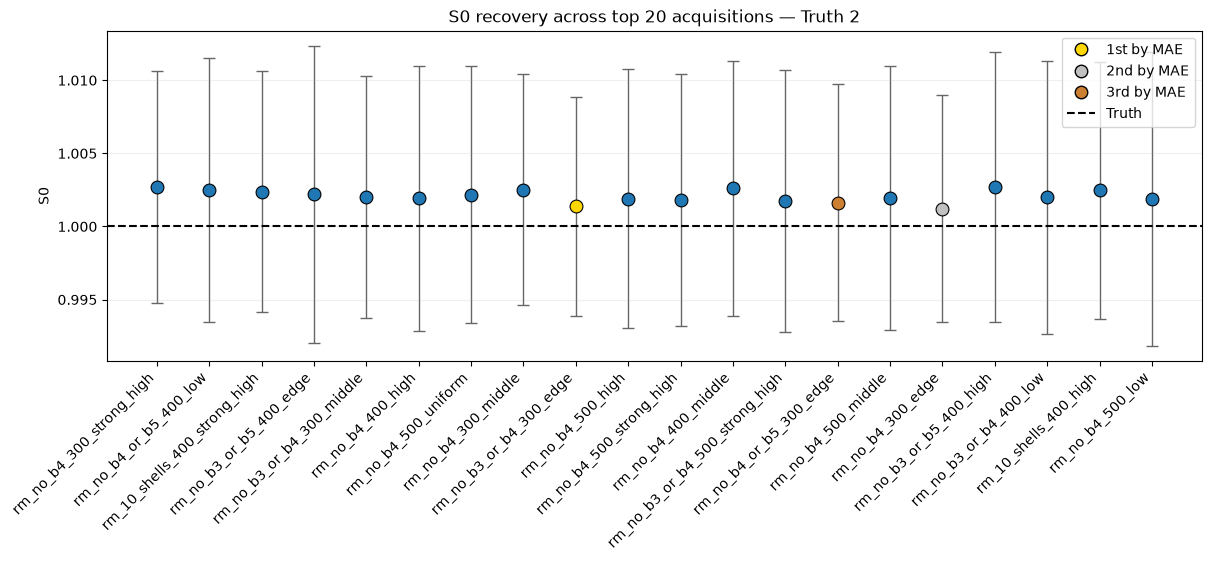

Saved: minimum_acquisition_tort2_plots/top20_truth2_S0_parameter_recovery.png


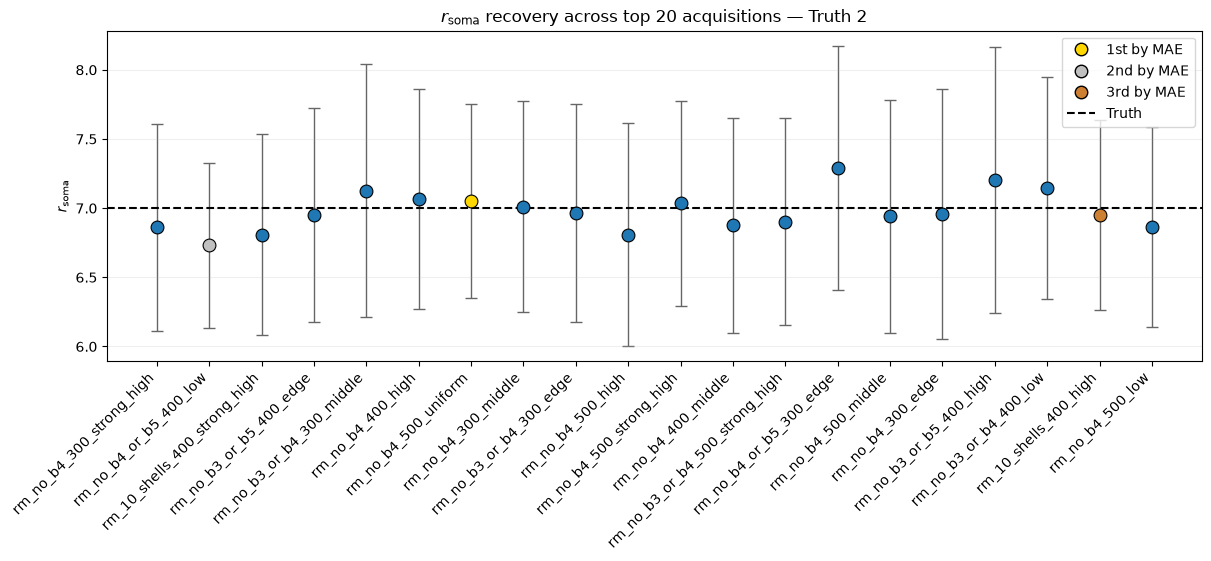

Saved: minimum_acquisition_tort2_plots/top20_truth2_r_soma_parameter_recovery.png


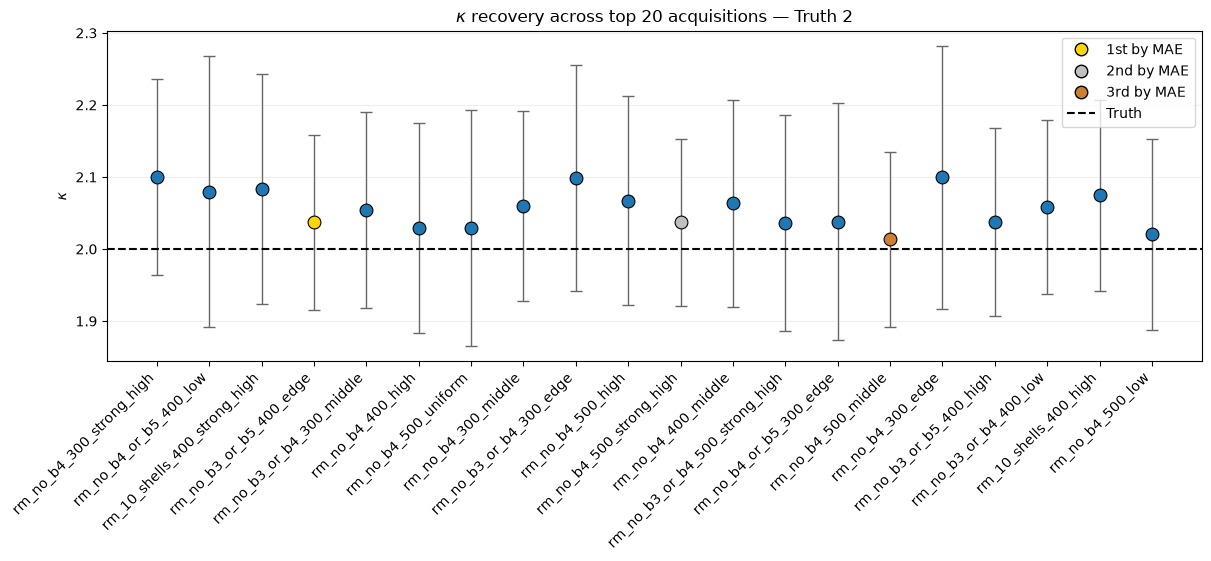

Saved: minimum_acquisition_tort2_plots/top20_truth2_kappa_parameter_recovery.png


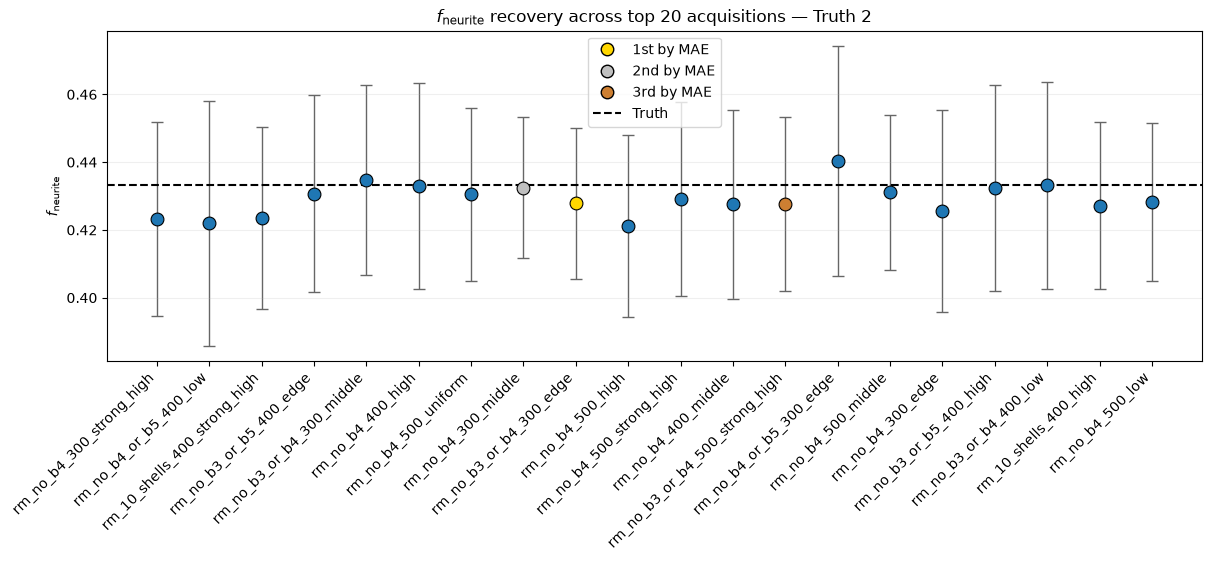

Saved: minimum_acquisition_tort2_plots/top20_truth2_neurite_fraction_parameter_recovery.png


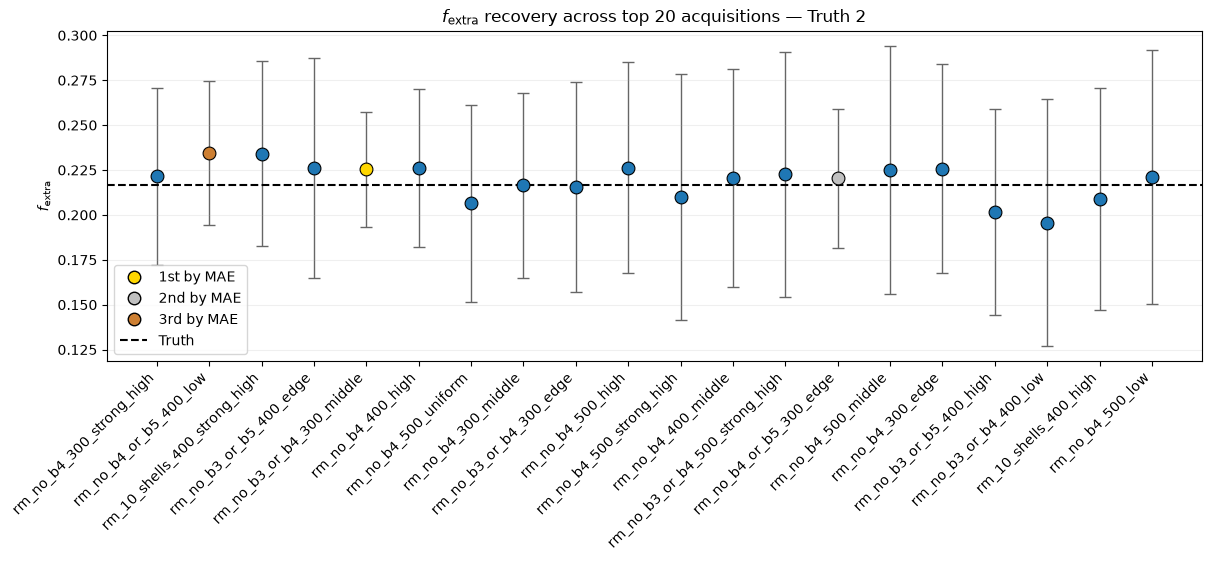

Saved: minimum_acquisition_tort2_plots/top20_truth2_extra_fraction_parameter_recovery.png


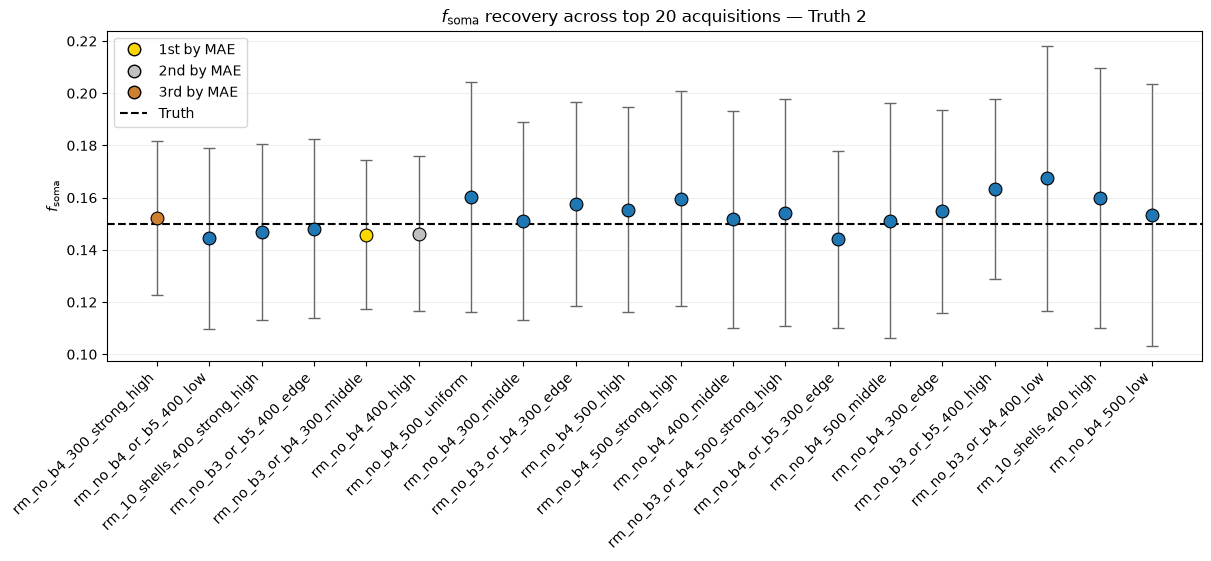

Saved: minimum_acquisition_tort2_plots/top20_truth2_soma_fraction_parameter_recovery.png


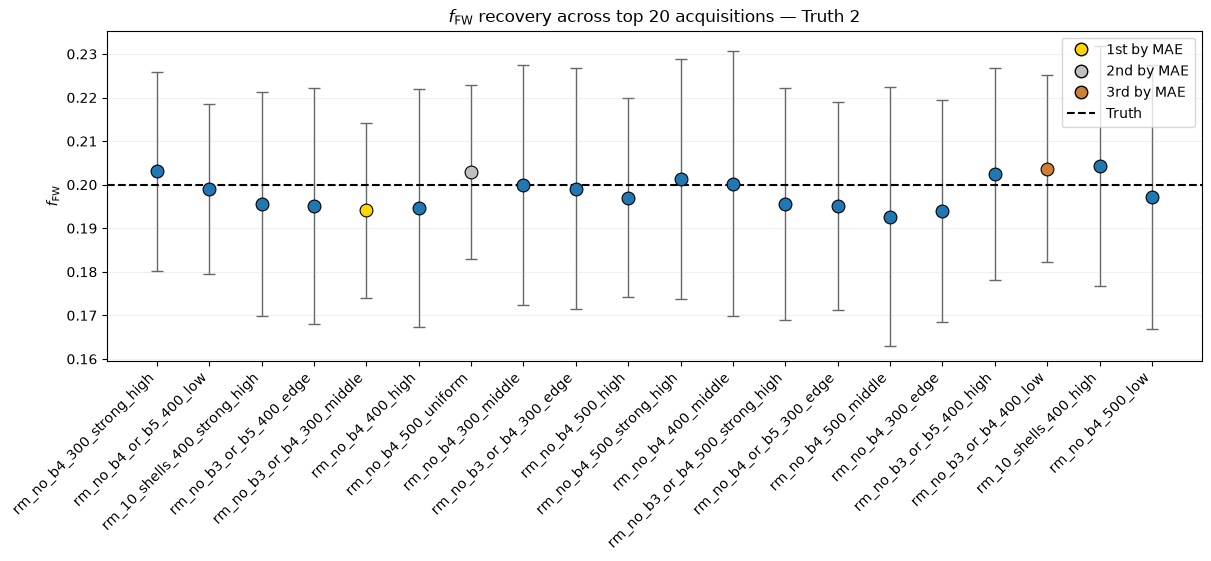

Saved: minimum_acquisition_tort2_plots/top20_truth2_csf_fraction_parameter_recovery.png


In [14]:
# =============================================================================
# PARAMETER RECOVERY ACROSS TOP 20 ACQUISITIONS — TRUTH 2 ONLY
# Gold / silver / bronze = best 3 acquisitions by MAE
# Error bars = SD across 30 noise repeats
# =============================================================================

PARAM_NAMES = [
    "S0",
    "r_soma",
    "kappa",
    "neurite_fraction",
    "extra_fraction",
    "soma_fraction",
    "csf_fraction",
]

PARAM_LABELS = {
    "S0": "S0",
    "r_soma": r"$r_{\mathrm{soma}}$",
    "kappa": r"$\kappa$",
    "neurite_fraction": r"$f_{\mathrm{neurite}}$",
    "extra_fraction": r"$f_{\mathrm{extra}}$",
    "soma_fraction": r"$f_{\mathrm{soma}}$",
    "csf_fraction": r"$f_{\mathrm{FW}}$",
}

TRUTH_COLUMNS = {
    "S0": "true_S0",
    "r_soma": "true_r_soma",
    "kappa": "true_kappa",
    "neurite_fraction": "true_neurite_fraction",
    "extra_fraction": "true_extra_fraction",
    "soma_fraction": "true_soma_fraction",
    "csf_fraction": "true_f_fw",
}

# -------------------------------------------------------------------------
# Top 20 acquisitions
# -------------------------------------------------------------------------

TOP20_ACQUISITIONS = (
    top20_acquisition_ranking
    .index
    .tolist()
)

# -------------------------------------------------------------------------
# TRUTH 2 ONLY
# -------------------------------------------------------------------------

truth2_df = results_df[
    (results_df["scenario"] == "truth_2")
    & (
        results_df["acquisition"].isin(
            TOP20_ACQUISITIONS
        )
    )
].copy()

print(
    f"Plotting {len(TOP20_ACQUISITIONS)} acquisitions "
    f"using truth_2 only."
)

# -------------------------------------------------------------------------
# Medal colours
# -------------------------------------------------------------------------

rank_colours = {
    1: "#FFD700",   # gold
    2: "#C0C0C0",   # silver
    3: "#CD7F32",   # bronze
}

# -------------------------------------------------------------------------
# Legend
# -------------------------------------------------------------------------

from matplotlib.lines import Line2D

legend_handles = [
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="#FFD700",
        markeredgecolor="black",
        markersize=9,
        label="1st by MAE",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="#C0C0C0",
        markeredgecolor="black",
        markersize=9,
        label="2nd by MAE",
    ),
    Line2D(
        [0],
        [0],
        marker="o",
        color="none",
        markerfacecolor="#CD7F32",
        markeredgecolor="black",
        markersize=9,
        label="3rd by MAE",
    ),
    Line2D(
        [0],
        [0],
        color="black",
        linestyle="--",
        linewidth=1.5,
        label="Truth",
    ),
]

# =============================================================================
# Plot each parameter
# =============================================================================

for pname in PARAM_NAMES:

    truth_column = TRUTH_COLUMNS[
        pname
    ]

    sub = truth2_df.copy()

    # ---------------------------------------------------------------------
    # Truth value
    # ---------------------------------------------------------------------

    truth_values = (
        sub[truth_column]
        .dropna()
        .unique()
    )

    if len(truth_values) != 1:
        raise ValueError(
            f"Expected one truth value for {pname} "
            f"in truth_2, found {truth_values}"
        )

    truth = float(
        truth_values[0]
    )

    # ---------------------------------------------------------------------
    # Error for every noise repeat
    # ---------------------------------------------------------------------

    sub["error"] = (
        sub[pname]
        - truth
    )

    # ---------------------------------------------------------------------
    # Mean, SD and MAE across the 30 repeats
    # ---------------------------------------------------------------------

    summary = (
        sub
        .groupby(
            "acquisition",
            as_index=False,
        )
        .agg(
            mean=(
                pname,
                "mean",
            ),
            sd=(
                pname,
                "std",
            ),
            mae=(
                "error",
                lambda x: np.mean(
                    np.abs(x)
                ),
            ),
        )
    )

    # ---------------------------------------------------------------------
    # Preserve overall top-20 ranking order on x-axis
    # ---------------------------------------------------------------------

    acquisition_order = {
        name: i
        for i, name in enumerate(
            TOP20_ACQUISITIONS
        )
    }

    summary["rank_order"] = (
        summary["acquisition"]
        .map(acquisition_order)
    )

    summary = (
        summary
        .sort_values("rank_order")
        .reset_index(drop=True)
    )

    # ---------------------------------------------------------------------
    # Rank specifically by Truth-2 MAE for this parameter
    # ---------------------------------------------------------------------

    summary["parameter_rank"] = (
        summary["mae"]
        .rank(
            method="dense",
            ascending=True,
        )
    )

    # ---------------------------------------------------------------------
    # Plot
    # ---------------------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(12, 5.5),
        constrained_layout=True,
    )

    x = np.arange(
        len(summary)
    )

    # SD across noise repeats
    ax.errorbar(
        x,
        summary["mean"],
        yerr=summary["sd"],
        fmt="none",
        ecolor="0.4",
        capsize=4,
        linewidth=1,
        zorder=1,
    )

    # Acquisition means
    for xi, row in zip(
        x,
        summary.itertuples(),
    ):

        rank = int(
            row.parameter_rank
        )

        colour = rank_colours.get(
            rank,
            "tab:blue",
        )

        ax.scatter(
            xi,
            row.mean,
            s=85,
            color=colour,
            edgecolor="black",
            linewidth=0.8,
            zorder=3,
        )

    # ---------------------------------------------------------------------
    # TRUTH LINE
    # ---------------------------------------------------------------------

    ax.axhline(
        truth,
        linestyle="--",
        linewidth=1.5,
        color="black",
        zorder=2,
    )

    # ---------------------------------------------------------------------
    # Labels
    # ---------------------------------------------------------------------

    ax.set_xticks(x)

    ax.set_xticklabels(
        summary["acquisition"],
        rotation=45,
        ha="right",
    )

    ax.set_ylabel(
        PARAM_LABELS[pname]
    )

    ax.set_title(
        f"{PARAM_LABELS[pname]} recovery across "
        f"top 20 acquisitions — Truth 2"
    )

    ax.grid(
        alpha=0.2,
        axis="y",
    )

    ax.legend(
        handles=legend_handles,
        loc="best",
        frameon=True,
    )

    # ---------------------------------------------------------------------
    # Save
    # ---------------------------------------------------------------------

    filename = (
        PLOT_DIR
        / f"top20_truth2_{pname}_parameter_recovery.png"
    )

    fig.savefig(
        filename,
        dpi=200,
        bbox_inches="tight",
    )

    plt.show()
    plt.close(fig)

    print(
        f"Saved: {filename}"
    )

In [15]:
# =============================================================================
# 10. PERFORMANCE ACROSS TRUTH SCENARIOS
# =============================================================================

TRUTH_LABELS = {
    "truth_1": "Truth 1: f_soma=0.10, r_soma=5, f_FW=0.15",
    "truth_2": "Truth 2: f_soma=0.15, r_soma=7, f_FW=0.20",
    "truth_3": "Truth 3: f_soma=0.20, r_soma=8, f_FW=0.25",
}

# -------------------------------------------------------------------------
# Absolute RMSE by acquisition × truth scenario × free parameter
# -------------------------------------------------------------------------

truth_rmse_table = (
    metrics_df[
        metrics_df["parameter"].isin(
            FREE_PARAMS.keys()
        )
    ]
    .pivot_table(
        index=["acquisition", "scenario"],
        columns="parameter",
        values="rmse",
    )
    .reindex(columns=list(FREE_PARAMS.keys()))
)

truth_rmse_table = truth_rmse_table.reset_index()

truth_rmse_table["scenario_label"] = (
    truth_rmse_table["scenario"].map(TRUTH_LABELS)
)

# Put scenario label near scenario name
truth_rmse_table = truth_rmse_table[
    [
        "acquisition",
        "scenario",
        "scenario_label",
        *FREE_PARAMS.keys(),
    ]
]

display(truth_rmse_table)

parameter,acquisition,scenario,scenario_label,S0,r_soma,kappa,neurite_fraction,extra_fraction,soma_fraction,csf_fraction
0,rm_10_shells_200_edge,truth_1,"Truth 1: f_soma=0.10, r_soma=5, f_FW=0.15",0.008125,3.251082,0.203334,0.058433,0.060211,0.046336,0.042096
1,rm_10_shells_200_edge,truth_2,"Truth 2: f_soma=0.15, r_soma=7, f_FW=0.20",0.008360,1.579315,0.186299,0.028779,0.069988,0.064392,0.044556
2,rm_10_shells_200_edge,truth_3,"Truth 3: f_soma=0.20, r_soma=8, f_FW=0.25",0.008446,1.338145,0.189756,0.019164,0.076081,0.078968,0.046924
3,rm_10_shells_200_high,truth_1,"Truth 1: f_soma=0.10, r_soma=5, f_FW=0.15",0.008350,2.400433,0.219391,0.056443,0.059242,0.037995,0.045339
4,rm_10_shells_200_high,truth_2,"Truth 2: f_soma=0.15, r_soma=7, f_FW=0.20",0.008432,1.338998,0.194609,0.031915,0.074174,0.063995,0.055692
...,...,...,...,...,...,...,...,...,...,...
406,rm_no_b5,truth_2,"Truth 2: f_soma=0.15, r_soma=7, f_FW=0.20",0.009281,1.861220,0.196186,0.037499,0.055009,0.049315,0.040601
407,rm_no_b5,truth_3,"Truth 3: f_soma=0.20, r_soma=8, f_FW=0.25",0.009408,1.631538,0.203820,0.027094,0.055140,0.058669,0.044794
408,rm_no_b5_200,truth_1,"Truth 1: f_soma=0.10, r_soma=5, f_FW=0.15",0.008980,1.432459,0.150804,0.049091,0.066742,0.041402,0.036248
409,rm_no_b5_200,truth_2,"Truth 2: f_soma=0.15, r_soma=7, f_FW=0.20",0.008892,1.548275,0.164110,0.027857,0.074592,0.058203,0.039265


In [16]:
# =============================================================================
# Absolute RMSE across truth scenarios
# =============================================================================

PRIMARY_PARAM_LABELS = {
    "r_soma": "r_soma",
    "soma_fraction": "f_soma",
    "csf_fraction": "f_FW",
}

PRIMARY_PARAM_UNITS = {
    "r_soma": "µm",
    "soma_fraction": "",
    "csf_fraction": "",
}

SCENARIO_ORDER = [
    "truth_1",
    "truth_2",
    "truth_3",
]

# -------------------------------------------------------------------------
# Unique colour + marker for every acquisition
# -------------------------------------------------------------------------

ACQUISITION_ORDER = sorted(
    metrics_df["acquisition"].dropna().unique()
)

cmap = plt.get_cmap(
    "turbo",
    len(ACQUISITION_ORDER),
)

MARKERS = [
    "o",
    "s",
    "^",
    "D",
    "v",
    "<",
    ">",
    "P",
    "X",
    "*",
    "h",
    "H",
    "p",
    "8",
    "d",
    "4",
]

ACQUISITION_COLOURS = {
    acquisition: cmap(i)
    for i, acquisition in enumerate(
        ACQUISITION_ORDER
    )
}

ACQUISITION_MARKERS = {
    acquisition: MARKERS[
        i % len(MARKERS)
    ]
    for i, acquisition in enumerate(
        ACQUISITION_ORDER
    )
}


for parameter in PRIMARY_PARAMS:

    plot_df = metrics_df[
        metrics_df["parameter"] == parameter
    ].copy()

    if plot_df.empty:
        continue

    plot_df["scenario"] = pd.Categorical(
        plot_df["scenario"],
        categories=SCENARIO_ORDER,
        ordered=True,
    )

    plot_df = plot_df.sort_values(
        ["scenario", "acquisition"]
    )

    fig, ax = plt.subplots(
        figsize=(11, 6)
    )

    for acquisition_name in ACQUISITION_ORDER:

        sub = plot_df[
            plot_df["acquisition"]
            == acquisition_name
        ].sort_values("scenario")

        if sub.empty:
            continue

        ax.plot(
            sub["scenario"],
            sub["rmse"],
            color=ACQUISITION_COLOURS[
                acquisition_name
            ],
            marker=ACQUISITION_MARKERS[
                acquisition_name
            ],
            markersize=7,
            linewidth=1.5,
            label=acquisition_name,
        )

    ax.set_xlabel(
        "Truth scenario"
    )

    units = PRIMARY_PARAM_UNITS[
        parameter
    ]

    ax.set_ylabel(
        f"Absolute RMSE ({units})"
        if units
        else "Absolute RMSE"
    )

    ax.set_title(
        f"{PRIMARY_PARAM_LABELS[parameter]} "
        f"recovery across truth scenarios"
    )

    ax.set_xticks(
        range(len(SCENARIO_ORDER))
    )

    ax.set_xticklabels([
        "Truth 1\nf_soma=0.10, r_soma=5, f_FW=0.15",
        "Truth 2\nf_soma=0.15, r_soma=7, f_FW=0.20",
        "Truth 3\nf_soma=0.20, r_soma=8, f_FW=0.25",
    ])

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        title="Acquisition",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=9,
    )

    fig.tight_layout()

    filename = (
        PLOT_DIR
        / f"{parameter}_rmse_across_truth_scenarios.png"
    )

    fig.savefig(
        filename,
        dpi=200,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(
        f"Saved: {filename}"
    )

/var/folders/j8/vf0ngfp954773cvv_9ry14nc0000gt/T/ipykernel_91779/3592810393.py:159: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


Saved: minimum_acquisition_tort2_plots/r_soma_rmse_across_truth_scenarios.png


/var/folders/j8/vf0ngfp954773cvv_9ry14nc0000gt/T/ipykernel_91779/3592810393.py:159: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


Saved: minimum_acquisition_tort2_plots/soma_fraction_rmse_across_truth_scenarios.png


/var/folders/j8/vf0ngfp954773cvv_9ry14nc0000gt/T/ipykernel_91779/3592810393.py:159: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


Saved: minimum_acquisition_tort2_plots/csf_fraction_rmse_across_truth_scenarios.png


In [17]:
# =============================================================================
# Absolute RMSE across truth scenarios — TOP 20 ACQUISITIONS ONLY
# =============================================================================

PRIMARY_PARAM_LABELS = {
    "r_soma": "r_soma",
    "soma_fraction": "f_soma",
    "csf_fraction": "f_FW",
}

PRIMARY_PARAM_UNITS = {
    "r_soma": "µm",
    "soma_fraction": "",
    "csf_fraction": "",
}

SCENARIO_ORDER = [
    "truth_1",
    "truth_2",
    "truth_3",
]

# -------------------------------------------------------------------------
# Top-20 acquisition list
# -------------------------------------------------------------------------

top20_ACQUISITION_ORDER = (
    top20_acquisition_ranking
    .index
    .tolist()
)

# -------------------------------------------------------------------------
# Restrict metrics_df to the top 20 acquisitions
# -------------------------------------------------------------------------

top20_metrics_df = metrics_df[
    metrics_df["acquisition"].isin(
        top20_ACQUISITION_ORDER
    )
].copy()

# -------------------------------------------------------------------------
# Unique colour + marker for the TOP 20 only
# -------------------------------------------------------------------------

cmap = plt.get_cmap(
    "turbo",
    len(top20_ACQUISITION_ORDER),
)

MARKERS = [
    "o",
    "s",
    "^",
    "D",
    "v",
    "<",
    ">",
    "P",
    "X",
    "*",
    "h",
    "H",
    "p",
    "8",
    "d",
    "4",
]

top20_ACQUISITION_COLOURS = {
    acquisition: cmap(i)
    for i, acquisition in enumerate(
        top20_ACQUISITION_ORDER
    )
}

top20_ACQUISITION_MARKERS = {
    acquisition: MARKERS[
        i % len(MARKERS)
    ]
    for i, acquisition in enumerate(
        top20_ACQUISITION_ORDER
    )
}

# -------------------------------------------------------------------------
# Make one plot per primary parameter
# -------------------------------------------------------------------------

for parameter in PRIMARY_PARAMS:

    plot_df = top20_metrics_df[
        top20_metrics_df["parameter"] == parameter
    ].copy()

    if plot_df.empty:
        continue

    plot_df["scenario"] = pd.Categorical(
        plot_df["scenario"],
        categories=SCENARIO_ORDER,
        ordered=True,
    )

    plot_df = plot_df.sort_values(
        ["scenario", "acquisition"]
    )

    fig, ax = plt.subplots(
        figsize=(12, 7)
    )

    for acquisition_name in top20_ACQUISITION_ORDER:

        sub = plot_df[
            plot_df["acquisition"]
            == acquisition_name
        ].sort_values("scenario")

        if sub.empty:
            continue

        ax.plot(
            sub["scenario"],
            sub["rmse"],
            color=top20_ACQUISITION_COLOURS[
                acquisition_name
            ],
            marker=top20_ACQUISITION_MARKERS[
                acquisition_name
            ],
            markersize=7,
            linewidth=1.5,
            label=acquisition_name,
        )

    ax.set_xlabel(
        "Truth scenario"
    )

    units = PRIMARY_PARAM_UNITS[
        parameter
    ]

    ax.set_ylabel(
        f"Absolute RMSE ({units})"
        if units
        else "Absolute RMSE"
    )

    ax.set_title(
        f"{PRIMARY_PARAM_LABELS[parameter]} "
        f"recovery across truth scenarios — Top 20 acquisitions"
    )

    ax.set_xticks(
        range(len(SCENARIO_ORDER))
    )

    ax.set_xticklabels([
        "Truth 1\nf_soma=0.10, r_soma=5, f_FW=0.15",
        "Truth 2\nf_soma=0.15, r_soma=7, f_FW=0.20",
        "Truth 3\nf_soma=0.20, r_soma=8, f_FW=0.25",
    ])

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        title="Top 30 acquisitions",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8,
    )

    fig.tight_layout()

    filename = (
        PLOT_DIR
        / f"{parameter}_rmse_across_truth_scenarios_top20.png"
    )

    fig.savefig(
        filename,
        dpi=200,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(
        f"Saved: {filename}"
    )

Saved: minimum_acquisition_tort2_plots/r_soma_rmse_across_truth_scenarios_top20.png
Saved: minimum_acquisition_tort2_plots/soma_fraction_rmse_across_truth_scenarios_top20.png
Saved: minimum_acquisition_tort2_plots/csf_fraction_rmse_across_truth_scenarios_top20.png


In [18]:
# =============================================================================
# Acquisition measurement counts — current + legacy acquisitions
# =============================================================================

N_MEASUREMENTS_MANUAL = {
    "rm_no_b4": 170,
    "rm_no_b5": 170,
    "rm_no_b4_or_b5": 140,
    "rm_no_b2_or_b4": 140,
    "rm_no_b0p5": 170,
    "rm_no_b3_or_b4": 140,
    "rm_no_b3_b4_or_b5": 110,
}

# Start with any counts available from the current acquisition summary
ACQUISITION_SIZE = (
    acquisition_summary
    .set_index("acquisition")["n_measurements"]
    .to_dict()
)

# Add/overwrite manual values, including acquisitions from previous runs
ACQUISITION_SIZE.update(
    N_MEASUREMENTS_MANUAL
)

print("Acquisition sizes:")
for acquisition_name in sorted(ACQUISITION_SIZE):
    print(
        f"  {acquisition_name}: "
        f"{ACQUISITION_SIZE[acquisition_name]}"
    )

Acquisition sizes:
  rm_10_shells_200_edge: 200
  rm_10_shells_200_high: 200
  rm_10_shells_200_low: 200
  rm_10_shells_200_middle: 200
  rm_10_shells_200_strong_high: 200
  rm_10_shells_200_uniform: 200
  rm_10_shells_300_edge: 300
  rm_10_shells_300_high: 300
  rm_10_shells_300_low: 300
  rm_10_shells_300_middle: 300
  rm_10_shells_300_strong_high: 300
  rm_10_shells_300_uniform: 300
  rm_10_shells_400_edge: 400
  rm_10_shells_400_high: 400
  rm_10_shells_400_low: 400
  rm_10_shells_400_middle: 400
  rm_10_shells_400_strong_high: 400
  rm_10_shells_400_uniform: 400
  rm_10_shells_500_edge: 500
  rm_10_shells_500_high: 500
  rm_10_shells_500_low: 500
  rm_10_shells_500_middle: 500
  rm_10_shells_500_strong_high: 500
  rm_10_shells_500_uniform: 500
  rm_no_b0p5: 170
  rm_no_b2_or_b4: 140
  rm_no_b3_b4_or_b5: 110
  rm_no_b3_or_b4: 140
  rm_no_b3_or_b4_200_edge: 200
  rm_no_b3_or_b4_200_high: 200
  rm_no_b3_or_b4_200_low: 200
  rm_no_b3_or_b4_200_middle: 200
  rm_no_b3_or_b4_200_strong_h

In [19]:
# =============================================================================
# Absolute RMSE vs acquisition size — one plot per free parameter
# Same acquisition colour + marker scheme as truth-scenario plots
# =============================================================================

FREE_PARAM_LABELS = {
    "S0": "S0",
    "r_soma": "r_soma",
    "kappa": "kappa",
    "neurite_fraction": "f_neurite",
    "extra_fraction": "f_extra",
    "soma_fraction": "f_soma",
    "csf_fraction": "f_FW",
}

FREE_PARAM_UNITS = {
    "S0": "",
    "r_soma": "µm",
    "kappa": "",
    "neurite_fraction": "",
    "extra_fraction": "",
    "soma_fraction": "",
    "csf_fraction": "",
}


for parameter in FREE_PARAMS:

    plot_df = (
        metrics_df[
            metrics_df["parameter"] == parameter
        ]
        .copy()
    )

    if plot_df.empty:
        continue

    # ---------------------------------------------------------------------
    # Average absolute RMSE across truth scenarios
    # ---------------------------------------------------------------------

    plot_df = (
        plot_df
        .groupby(
            "acquisition",
            as_index=False,
        )
        .agg(
            mean_rmse=("rmse", "mean"),
        )
    )

    # ---------------------------------------------------------------------
    # Add acquisition size
    # ---------------------------------------------------------------------

    plot_df["n_measurements"] = (
        plot_df["acquisition"]
        .map(ACQUISITION_SIZE)
    )

    # Remove acquisitions without size information
    plot_df = plot_df.dropna(
        subset=["n_measurements"]
    )

    plot_df = plot_df.sort_values(
        "n_measurements"
    )

    # ---------------------------------------------------------------------
    # Plot
    # ---------------------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    # One acquisition = one consistent colour + marker
    for _, row in plot_df.iterrows():

        acquisition_name = row[
            "acquisition"
        ]

        ax.scatter(
            row["n_measurements"],
            row["mean_rmse"],
            s=80,
            color=ACQUISITION_COLOURS[
                acquisition_name
            ],
            marker=ACQUISITION_MARKERS[
                acquisition_name
            ],
            label=acquisition_name,
            zorder=3,
        )

    # ---------------------------------------------------------------------
    # Optional connecting line
    #
    # This is deliberately neutral because it does not represent one
    # acquisition; it simply connects points by acquisition size.
    # ---------------------------------------------------------------------

    ax.plot(
        plot_df["n_measurements"],
        plot_df["mean_rmse"],
        linewidth=1,
        alpha=0.35,
        zorder=1,
    )

    # ---------------------------------------------------------------------
    # Labels
    # ---------------------------------------------------------------------

    ax.set_xlabel(
        "Total acquisition measurements"
    )

    units = FREE_PARAM_UNITS.get(
        parameter,
        ""
    )

    ylabel = (
        f"Absolute RMSE ({units})"
        if units
        else "Absolute RMSE"
    )

    ax.set_ylabel(
        ylabel
    )

    ax.set_title(
        f"{FREE_PARAM_LABELS.get(parameter, parameter)} "
        f"recovery vs acquisition size"
    )

    ax.grid(
        alpha=0.25
    )

    ax.legend(
        title="Acquisition",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=9,
    )

    fig.tight_layout()

    filename = (
        PLOT_DIR
        / f"{parameter}_absolute_rmse_vs_acquisition_size.png"
    )

    fig.savefig(
        filename,
        dpi=200,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(
        f"Saved: {filename}"
    )

/var/folders/j8/vf0ngfp954773cvv_9ry14nc0000gt/T/ipykernel_16593/915591697.py:155: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


Saved: minimum_acquisition_tort2_plots/S0_absolute_rmse_vs_acquisition_size.png


/var/folders/j8/vf0ngfp954773cvv_9ry14nc0000gt/T/ipykernel_16593/915591697.py:155: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


Saved: minimum_acquisition_tort2_plots/r_soma_absolute_rmse_vs_acquisition_size.png


/var/folders/j8/vf0ngfp954773cvv_9ry14nc0000gt/T/ipykernel_16593/915591697.py:155: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


...

Saved: minimum_acquisition_tort2_plots/extra_fraction_absolute_rmse_vs_acquisition_size.png


/var/folders/j8/vf0ngfp954773cvv_9ry14nc0000gt/T/ipykernel_16593/915591697.py:155: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


Saved: minimum_acquisition_tort2_plots/soma_fraction_absolute_rmse_vs_acquisition_size.png


/var/folders/j8/vf0ngfp954773cvv_9ry14nc0000gt/T/ipykernel_16593/915591697.py:155: UserWarning: Tight layout not applied. The bottom and top margins cannot be made large enough to accommodate all Axes decorations.
  fig.tight_layout()


Saved: minimum_acquisition_tort2_plots/csf_fraction_absolute_rmse_vs_acquisition_size.png


In [20]:
# =============================================================================
# Absolute RMSE vs acquisition size — TOP 30 ACQUISITIONS ONLY
# Jittered points, no connecting line
# =============================================================================

FREE_PARAM_LABELS = {
    "S0": "S0",
    "r_soma": "r_soma",
    "kappa": "kappa",
    "neurite_fraction": "f_neurite",
    "extra_fraction": "f_extra",
    "soma_fraction": "f_soma",
    "csf_fraction": "f_FW",
}

FREE_PARAM_UNITS = {
    "S0": "",
    "r_soma": "µm",
    "kappa": "",
    "neurite_fraction": "",
    "extra_fraction": "",
    "soma_fraction": "",
    "csf_fraction": "",
}

# -------------------------------------------------------------------------
# Top-30 acquisition list
# -------------------------------------------------------------------------

top20_ACQUISITION_ORDER = (
    top20_acquisition_ranking
    .index
    .tolist()
)

# -------------------------------------------------------------------------
# Restrict metrics to top 30
# -------------------------------------------------------------------------

top20_metrics_df = metrics_df[
    metrics_df["acquisition"].isin(
        top20_ACQUISITION_ORDER
    )
].copy()

# -------------------------------------------------------------------------
# Unique colour + marker scheme
# -------------------------------------------------------------------------

cmap = plt.get_cmap(
    "turbo",
    len(top20_ACQUISITION_ORDER),
)

MARKERS = [
    "o",
    "s",
    "^",
    "D",
    "v",
    "<",
    ">",
    "P",
    "X",
    "*",
    "h",
    "H",
    "p",
    "8",
    "d",
    "4",
]

top20_ACQUISITION_COLOURS = {
    acquisition: cmap(i)
    for i, acquisition in enumerate(
        top20_ACQUISITION_ORDER
    )
}

top20_ACQUISITION_MARKERS = {
    acquisition: MARKERS[
        i % len(MARKERS)
    ]
    for i, acquisition in enumerate(
        top20_ACQUISITION_ORDER
    )
}

# -------------------------------------------------------------------------
# Amount of horizontal jitter
# -------------------------------------------------------------------------

JITTER_WIDTH = 12.0

# -------------------------------------------------------------------------
# Plot one figure per free parameter
# -------------------------------------------------------------------------

for parameter in FREE_PARAMS:

    plot_df = (
        top20_metrics_df[
            top20_metrics_df["parameter"]
            == parameter
        ]
        .copy()
    )

    if plot_df.empty:
        continue

    # ---------------------------------------------------------------------
    # Average absolute RMSE across truth scenarios
    # ---------------------------------------------------------------------

    plot_df = (
        plot_df
        .groupby(
            "acquisition",
            as_index=False,
        )
        .agg(
            mean_rmse=("rmse", "mean"),
        )
    )

    # ---------------------------------------------------------------------
    # Add acquisition size
    # ---------------------------------------------------------------------

    plot_df["n_measurements"] = (
        plot_df["acquisition"]
        .map(ACQUISITION_SIZE)
    )

    plot_df = plot_df.dropna(
        subset=["n_measurements"]
    )

    # ---------------------------------------------------------------------
    # Add horizontal jitter
    #
    # Only acquisitions with the same number of measurements are jittered.
    # ---------------------------------------------------------------------

    plot_df["jitter"] = 0.0

    for n_measurements, group in plot_df.groupby(
        "n_measurements"
    ):

        # Keep jitter order consistent with top-30 ranking
        acquisitions = [
            acquisition
            for acquisition
            in top20_ACQUISITION_ORDER
            if acquisition
            in group["acquisition"].values
        ]

        n = len(acquisitions)

        if n <= 1:
            continue

        offsets = np.linspace(
            -JITTER_WIDTH / 2,
            JITTER_WIDTH / 2,
            n,
        )

        for acquisition_name, offset in zip(
            acquisitions,
            offsets,
        ):

            plot_df.loc[
                plot_df["acquisition"]
                == acquisition_name,
                "jitter",
            ] = offset

    plot_df["x_plot"] = (
        plot_df["n_measurements"]
        + plot_df["jitter"]
    )

    # ---------------------------------------------------------------------
    # Plot
    # ---------------------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(11, 7)
    )

    for _, row in plot_df.iterrows():

        acquisition_name = row[
            "acquisition"
        ]

        ax.scatter(
            row["x_plot"],
            row["mean_rmse"],
            s=85,
            color=top20_ACQUISITION_COLOURS[
                acquisition_name
            ],
            marker=top20_ACQUISITION_MARKERS[
                acquisition_name
            ],
            label=acquisition_name,
            zorder=3,
        )

    # ---------------------------------------------------------------------
    # Show true acquisition budgets on x-axis
    # ---------------------------------------------------------------------

    acquisition_sizes = sorted(
        plot_df[
            "n_measurements"
        ].unique()
    )

    ax.set_xticks(
        acquisition_sizes
    )

    ax.set_xlabel(
        "Total acquisition measurements"
    )

    # ---------------------------------------------------------------------
    # Y-axis
    # ---------------------------------------------------------------------

    units = FREE_PARAM_UNITS.get(
        parameter,
        ""
    )

    ylabel = (
        f"Absolute RMSE ({units})"
        if units
        else "Absolute RMSE"
    )

    ax.set_ylabel(
        ylabel
    )

    ax.set_title(
        f"{FREE_PARAM_LABELS.get(parameter, parameter)} "
        f"recovery vs acquisition size — Top 20 acquisitions"
    )

    ax.grid(
        alpha=0.25
    )

    # ---------------------------------------------------------------------
    # Legend
    # ---------------------------------------------------------------------

    ax.legend(
        title="Top 30 acquisitions",
        bbox_to_anchor=(1.02, 1),
        loc="upper left",
        fontsize=8,
    )

    fig.tight_layout()

    # ---------------------------------------------------------------------
    # Save
    # ---------------------------------------------------------------------

    filename = (
        PLOT_DIR
        / (
            f"{parameter}_absolute_rmse_"
            f"vs_acquisition_size_top20.png"
        )
    )

    fig.savefig(
        filename,
        dpi=200,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(
        f"Saved: {filename}"
    )

Saved: minimum_acquisition_tort2_plots/S0_absolute_rmse_vs_acquisition_size_top20.png
Saved: minimum_acquisition_tort2_plots/r_soma_absolute_rmse_vs_acquisition_size_top20.png
Saved: minimum_acquisition_tort2_plots/kappa_absolute_rmse_vs_acquisition_size_top20.png
Saved: minimum_acquisition_tort2_plots/neurite_fraction_absolute_rmse_vs_acquisition_size_top20.png
Saved: minimum_acquisition_tort2_plots/extra_fraction_absolute_rmse_vs_acquisition_size_top20.png
Saved: minimum_acquisition_tort2_plots/soma_fraction_absolute_rmse_vs_acquisition_size_top20.png
Saved: minimum_acquisition_tort2_plots/csf_fraction_absolute_rmse_vs_acquisition_size_top20.png



Best acquisition at each measurement budget:


,acquisition,n_measurements,mean_primary_relative_rmse,worst_scenario_primary_relative_rmse,success_rate
34,rm_no_b4_200_high,200.0,0.203391,0.255046,1.0
0,rm_no_b4_300_strong_high,300.0,0.151612,0.180983,1.0
1,rm_no_b4_or_b5_400_low,400.0,0.154883,0.206635,1.0
6,rm_no_b4_500_uniform,500.0,0.169739,0.200079,1.0


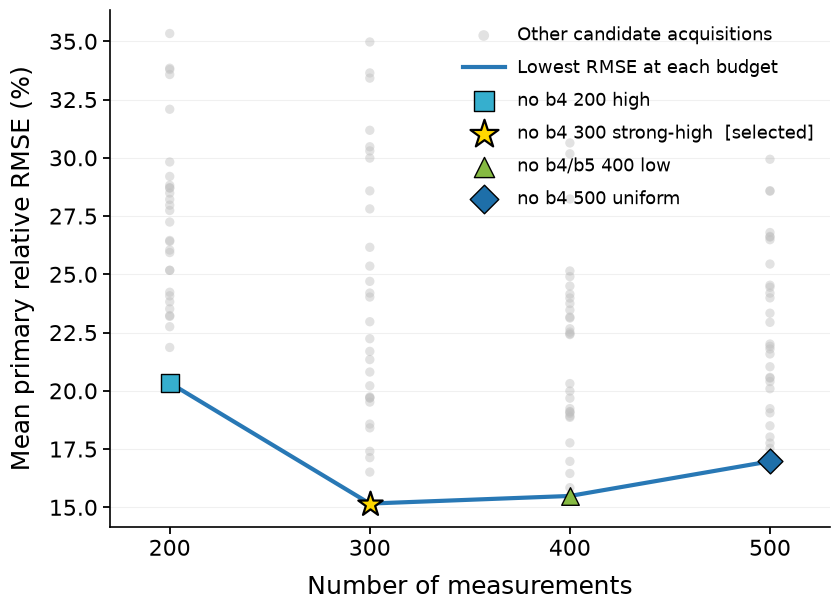


Saved: minimum_acquisition_tort2_plots/figure2B_acquisition_efficiency.png


In [31]:
# =============================================================================
# FIGURE 2B — Acquisition efficiency
#
# Grey points:
#   All candidate acquisitions
#
# Highlighted points:
#   Single lowest-RMSE acquisition at each measurement budget
#
# Blue line:
#   Connects lowest RMSE at each budget
#
# Gold star:
#   Selected acquisition
# =============================================================================

import matplotlib.pyplot as plt


# -----------------------------------------------------------------------------
# USER SETTINGS
# -----------------------------------------------------------------------------

SELECTED_ACQUISITION = "rm_no_b4_300_strong_high"

BUDGETS = [200, 300, 400, 500]


# =============================================================================
# 1. BUILD PLOTTING DATAFRAME
# =============================================================================

plot_df = (
    acquisition_ranking
    .reset_index()
    .copy()
)

if "acquisition" not in plot_df.columns:
    plot_df = plot_df.rename(
        columns={
            plot_df.columns[0]: "acquisition"
        }
    )

plot_df = plot_df[
    plot_df["n_measurements"].isin(BUDGETS)
].copy()

plot_df = plot_df.dropna(
    subset=[
        "n_measurements",
        "mean_primary_relative_rmse",
    ]
)

# Relative RMSE -> percentage
plot_df["rmse_percent"] = (
    100.0
    * plot_df["mean_primary_relative_rmse"]
)


# =============================================================================
# 2. FIND BEST ACQUISITION AT EACH BUDGET
# =============================================================================

best_by_budget = (
    plot_df
    .loc[
        plot_df
        .groupby("n_measurements")[
            "mean_primary_relative_rmse"
        ]
        .idxmin()
    ]
    .sort_values("n_measurements")
    .copy()
)

print("\nBest acquisition at each measurement budget:")

display(
    best_by_budget[
        [
            "acquisition",
            "n_measurements",
            "mean_primary_relative_rmse",
            "worst_scenario_primary_relative_rmse",
            "success_rate",
        ]
    ]
)


# =============================================================================
# 3. PRETTY ACQUISITION NAMES
# =============================================================================

def pretty_acquisition_name(name):

    label = name

    if label.startswith("rm_"):
        label = label[3:]

    # Longer replacements first
    replacements = [
        ("no_b4_or_b5", "no b4/b5"),
        ("no_b3_or_b4", "no b3/b4"),
        ("no_b3_or_b5", "no b3/b5"),
        ("no_b4", "no b4"),
        ("10_shells", "10-shell"),
        ("strong_high", "strong-high"),
    ]

    for old, new in replacements:
        label = label.replace(old, new)

    label = label.replace("_", " ")

    return label


# =============================================================================
# 4. VISUAL STYLE
# =============================================================================

# Bright categorical colours for the four budgets
BUDGET_COLOURS = {
    200: "#36AFCE",   # bright blue
    300: "#FFD700",   # gold
    400: "#86BA42",   # green
    500: "#1E6FA9",   # dark blue
}

# Marker shape for each budget
BUDGET_MARKERS = {
    200: "s",
    300: "*",
    400: "^",
    500: "D",
}


# =============================================================================
# 5. PLOT
# =============================================================================

fig, ax = plt.subplots(
    figsize=(8.5, 6.2)
)


# -----------------------------------------------------------------------------
# 5a. All candidate acquisitions
# -----------------------------------------------------------------------------

ax.scatter(
    plot_df["n_measurements"],
    plot_df["rmse_percent"],
    s=45,
    color="0.75",
    alpha=0.45,
    edgecolors="none",
    label="Other candidate acquisitions",
    zorder=1,
)


# -----------------------------------------------------------------------------
# 5b. Lowest-RMSE envelope
#
# No markers on this line.
# -----------------------------------------------------------------------------

ax.plot(
    best_by_budget["n_measurements"],
    best_by_budget["rmse_percent"],
    color="#2878B5",
    linewidth=3.0,
    zorder=2,
    label="Lowest RMSE at each budget",
)


# -----------------------------------------------------------------------------
# 5c. Highlight best acquisition at each budget
# -----------------------------------------------------------------------------

for _, row in best_by_budget.iterrows():

    budget = int(
        row["n_measurements"]
    )

    acquisition_name = row[
        "acquisition"
    ]

    is_selected = (
        acquisition_name
        == SELECTED_ACQUISITION
    )

    # Selected acquisition gets a larger star.
    # Other budgets use their assigned marker.
    marker = (
        "*"
        if is_selected
        else BUDGET_MARKERS[budget]
    )

    point_size = (
        340
        if is_selected
        else 160
    )

    edge_width = (
        1.6
        if is_selected
        else 1.0
    )

    legend_label = (
        pretty_acquisition_name(
            acquisition_name
        )
    )

    if is_selected:
        legend_label += "  [selected]"

    ax.scatter(
        budget,
        row["rmse_percent"],
        s=point_size,
        marker=marker,
        color=BUDGET_COLOURS[budget],
        edgecolor="black",
        linewidth=edge_width,
        zorder=6 if is_selected else 5,
        label=legend_label,
    )


# =============================================================================
# 6. AXES + LARGE TYPOGRAPHY
# =============================================================================

ax.set_xticks(
    BUDGETS
)

ax.set_xlim(
    min(BUDGETS) - 30,
    max(BUDGETS) + 30,
)

ax.set_xlabel(
    "Number of measurements",
    fontsize=18,
    labelpad=10,
)

ax.set_ylabel(
    "Mean primary relative RMSE (%)",
    fontsize=18,
    labelpad=10,
)

# Large tick labels
ax.tick_params(
    axis="both",
    which="major",
    labelsize=16,
    width=1.3,
    length=5,
)

# NO TITLE

# Horizontal grid only
ax.grid(
    axis="y",
    alpha=0.18,
    linewidth=0.8,
)

# Clean borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

ax.spines["left"].set_linewidth(1.2)
ax.spines["bottom"].set_linewidth(1.2)


# =============================================================================
# 7. LARGE LEGEND
# =============================================================================

ax.legend(
    frameon=False,
    fontsize=13,
    loc="upper right",
    labelspacing=0.8,
    markerscale=1.15,
    handletextpad=0.7,
    handlelength=2.3,
)


# =============================================================================
# 8. SAVE
# =============================================================================

fig.tight_layout()

filename = (
    PLOT_DIR
    / "figure2B_acquisition_efficiency.png"
)

fig.savefig(
    filename,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"\nSaved: {filename}"
)

In [48]:
# =============================================================================
# CONTINUOUS ONE-PARAMETER RECOVERY SWEEPS
#
# Purpose:
#   Evaluate recovery across the full range of:
#       1. soma fraction
#       2. soma radius
#       3. free-water fraction
#
# while holding the other primary parameters at a reference inflammatory state.
#
# Composition rules:
#
#   f_soma sweep:
#       Preserve reference NON-SOMA composition
#           q_i = f_i / (1 - f_soma)
#
#   r_soma sweep:
#       Keep all fractions unchanged
#
#   f_FW sweep:
#       Preserve relative neurite:extra-neurite tissue composition
#
# =============================================================================

from pathlib import Path
import time
import numpy as np
import pandas as pd


# =============================================================================
# 1. USER SETTINGS
# =============================================================================

SWEEP_ACQUISITION_NAME = "rm_no_b4_300_strong_high"

N_SWEEP_REPEATS = 30

F_SOMA_SWEEP = np.arange(
    0.05,
    0.3001,
    0.025,
)

R_SOMA_SWEEP = np.arange(
    2.0,
    10.01,
    0.5,
)

F_FW_SWEEP = np.arange(
    0.05,
    0.3501,
    0.025,
)

SWEEP_RESULTS_FILE = Path(
    "tort2_continuous_recovery_sweeps_SNR50.csv"
)
SNR = 50.0

# =============================================================================
# 2. REFERENCE TRUTH
#
# Use the middle inflammatory state as the reference.
#
# If your scenario is named differently, change "truth_2" here.
# =============================================================================

REFERENCE_TRUTH = (
    TRUTH_BY_SCENARIO[
        "truth_2"
    ]
    .copy()
)

print("Reference truth:")

for key, value in REFERENCE_TRUTH.items():
    print(
        f"  {key}: {value}"
    )


# =============================================================================
# 3. CHECK REFERENCE SIMPLEX
# =============================================================================

REFERENCE_FRACTION_SUM = (
    REFERENCE_TRUTH[
        "neurite_fraction"
    ]
    + REFERENCE_TRUTH[
        "extra_fraction"
    ]
    + REFERENCE_TRUTH[
        "soma_fraction"
    ]
    + REFERENCE_TRUTH[
        "csf_fraction"
    ]
)

print(
    "\nReference fraction sum:",
    REFERENCE_FRACTION_SUM,
)

assert np.isclose(
    REFERENCE_FRACTION_SUM,
    1.0,
), (
    "Reference fractions do not sum to 1."
)


# =============================================================================
# 4. REFERENCE COMPOSITIONS
# =============================================================================

f_n_ref = REFERENCE_TRUTH[
    "neurite_fraction"
]

f_ex_ref = REFERENCE_TRUTH[
    "extra_fraction"
]

f_s_ref = REFERENCE_TRUTH[
    "soma_fraction"
]

f_fw_ref = REFERENCE_TRUTH[
    "csf_fraction"
]


# -----------------------------------------------------------------------------
# Non-soma composition
#
# Used when sweeping f_soma.
#
# q_n + q_ex + q_fw = 1
# -----------------------------------------------------------------------------

non_soma_total_ref = (
    1.0
    - f_s_ref
)

q_n_ref = (
    f_n_ref
    / non_soma_total_ref
)

q_ex_ref = (
    f_ex_ref
    / non_soma_total_ref
)

q_fw_ref = (
    f_fw_ref
    / non_soma_total_ref
)

print(
    "\nReference non-soma composition:"
)

print(
    f"  q_n  = {q_n_ref:.4f}"
)

print(
    f"  q_ex = {q_ex_ref:.4f}"
)

print(
    f"  q_fw = {q_fw_ref:.4f}"
)

print(
    "  sum  = "
    f"{q_n_ref + q_ex_ref + q_fw_ref:.4f}"
)


# -----------------------------------------------------------------------------
# Relative neurite : extra-neurite composition
#
# Used when sweeping f_FW.
#
# Soma fraction remains fixed.
# Remaining neurite + extra-neurite pool is redistributed according to
# this fixed ratio.
# -----------------------------------------------------------------------------

tissue_ne_ref = (
    f_n_ref
    + f_ex_ref
)

p_n_ref = (
    f_n_ref
    / tissue_ne_ref
)

p_ex_ref = (
    f_ex_ref
    / tissue_ne_ref
)

print(
    "\nReference neurite/extra-neurite composition:"
)

print(
    f"  p_n  = {p_n_ref:.4f}"
)

print(
    f"  p_ex = {p_ex_ref:.4f}"
)

print(
    "  sum  = "
    f"{p_n_ref + p_ex_ref:.4f}"
)


# =============================================================================
# 5. TRUTH-CONSTRUCTION FUNCTION
# =============================================================================

def make_sweep_truth(
    sweep_parameter,
    sweep_value,
):
    """
    Construct a valid ground-truth parameter dictionary for a
    one-at-a-time parameter recovery sweep.

    Parameters
    ----------
    sweep_parameter : str
        One of:
            "soma_fraction"
            "r_soma"
            "csf_fraction"

    sweep_value : float
        Ground-truth value for the swept parameter.

    Returns
    -------
    truth : dict
        Full truth dictionary compatible with simulate_signal()
        and fit_tort2_ls().
    """

    truth = (
        REFERENCE_TRUTH
        .copy()
    )

    # ---------------------------------------------------------------------
    # A. SOMA FRACTION SWEEP
    #
    # Preserve the reference non-soma composition:
    #
    #   q_i = f_i / (1 - f_s)
    #
    # Therefore:
    #
    #   f_i = q_i * (1 - f_s)
    #
    # ---------------------------------------------------------------------

    if (
        sweep_parameter
        == "soma_fraction"
    ):

        f_s = float(
            sweep_value
        )

        remaining_non_soma = (
            1.0
            - f_s
        )

        truth[
            "soma_fraction"
        ] = f_s

        truth[
            "neurite_fraction"
        ] = (
            q_n_ref
            * remaining_non_soma
        )

        truth[
            "extra_fraction"
        ] = (
            q_ex_ref
            * remaining_non_soma
        )

        truth[
            "csf_fraction"
        ] = (
            q_fw_ref
            * remaining_non_soma
        )


    # ---------------------------------------------------------------------
    # B. SOMA RADIUS SWEEP
    #
    # Radius changes only.
    # All fractions remain exactly at the reference state.
    # ---------------------------------------------------------------------

    elif (
        sweep_parameter
        == "r_soma"
    ):

        truth[
            "r_soma"
        ] = float(
            sweep_value
        )


    # ---------------------------------------------------------------------
    # C. FREE-WATER FRACTION SWEEP
    #
    # Hold f_soma fixed.
    #
    # The remaining fraction available to neurite + extra-neurite is:
    #
    #   1 - f_soma - f_FW
    #
    # Preserve the reference relative neurite:extra-neurite composition.
    # ---------------------------------------------------------------------

    elif (
        sweep_parameter
        == "csf_fraction"
    ):

        f_fw = float(
            sweep_value
        )

        f_s = f_s_ref

        remaining_ne_ex = (
            1.0
            - f_s
            - f_fw
        )

        if remaining_ne_ex <= 0:

            raise ValueError(
                "Invalid f_FW sweep value: "
                "no remaining fraction for "
                "neurite + extra-neurite."
            )

        truth[
            "soma_fraction"
        ] = f_s

        truth[
            "csf_fraction"
        ] = f_fw

        truth[
            "neurite_fraction"
        ] = (
            p_n_ref
            * remaining_ne_ex
        )

        truth[
            "extra_fraction"
        ] = (
            p_ex_ref
            * remaining_ne_ex
        )


    else:

        raise ValueError(
            f"Unknown sweep parameter: "
            f"{sweep_parameter}"
        )


    # ---------------------------------------------------------------------
    # Validate fractions
    # ---------------------------------------------------------------------

    fraction_sum = (
        truth[
            "neurite_fraction"
        ]
        + truth[
            "extra_fraction"
        ]
        + truth[
            "soma_fraction"
        ]
        + truth[
            "csf_fraction"
        ]
    )

    if not np.isclose(
        fraction_sum,
        1.0,
        atol=1e-10,
    ):

        raise ValueError(
            "Sweep truth fractions do not "
            f"sum to 1: {fraction_sum}"
        )

    for fraction_name in [
        "neurite_fraction",
        "extra_fraction",
        "soma_fraction",
        "csf_fraction",
    ]:

        if not (
            0.0
            <= truth[fraction_name]
            <= 1.0
        ):

            raise ValueError(
                f"{fraction_name} invalid: "
                f"{truth[fraction_name]}"
            )

    return truth


# =============================================================================
# 6. DEFINE SWEEP EXPERIMENTS
# =============================================================================

SWEEPS = {
    "soma_fraction": (
        F_SOMA_SWEEP
    ),

    "r_soma": (
        R_SOMA_SWEEP
    ),

    "csf_fraction": (
        F_FW_SWEEP
    ),
}


# =============================================================================
# 7. SANITY-CHECK ALL TRUTH STATES BEFORE RUNNING FITS
# =============================================================================

truth_check_rows = []

for (
    sweep_parameter,
    sweep_values,
) in SWEEPS.items():

    for sweep_value in sweep_values:

        truth = make_sweep_truth(
            sweep_parameter,
            sweep_value,
        )

        truth_check_rows.append({
            "sweep_parameter":
                sweep_parameter,

            "sweep_value":
                sweep_value,

            "f_neurite":
                truth[
                    "neurite_fraction"
                ],

            "f_extra":
                truth[
                    "extra_fraction"
                ],

            "f_soma":
                truth[
                    "soma_fraction"
                ],

            "f_FW":
                truth[
                    "csf_fraction"
                ],

            "r_soma":
                truth[
                    "r_soma"
                ],

            "fraction_sum": (
                truth[
                    "neurite_fraction"
                ]
                + truth[
                    "extra_fraction"
                ]
                + truth[
                    "soma_fraction"
                ]
                + truth[
                    "csf_fraction"
                ]
            ),
        })


truth_check_df = pd.DataFrame(
    truth_check_rows
)

display(
    truth_check_df
)


# =============================================================================
# 8. GET SELECTED ACQUISITION
# =============================================================================

if (
    SWEEP_ACQUISITION_NAME
    not in ACQUISITIONS
):

    raise KeyError(
        f"{SWEEP_ACQUISITION_NAME} "
        "not found in ACQUISITIONS."
    )


sweep_acquisition = (
    ACQUISITIONS[
        SWEEP_ACQUISITION_NAME
    ]
)


# =============================================================================
# 9. LOAD CHECKPOINT IF IT EXISTS
# =============================================================================

if SWEEP_RESULTS_FILE.exists():

    sweep_results_df = pd.read_csv(
        SWEEP_RESULTS_FILE
    )

    sweep_results = (
        sweep_results_df
        .to_dict(
            orient="records"
        )
    )

    print(
        "\nLoaded existing sweep checkpoint: "
        f"{len(sweep_results)} fits."
    )

else:

    sweep_results = []

    sweep_results_df = (
        pd.DataFrame()
    )

    print(
        "\nNo sweep checkpoint found. "
        "Starting from scratch."
    )


# =============================================================================
# 10. IDENTIFY COMPLETED FITS
# =============================================================================

completed_sweeps = {
    (
        row[
            "sweep_parameter"
        ],
        round(
            float(
                row[
                    "sweep_value"
                ]
            ),
            8,
        ),
        int(
            row[
                "repeat"
            ]
        ),
    )

    for row in sweep_results
}


# =============================================================================
# 11. TOTAL WORK
# =============================================================================

total_sweep_fits = (
    sum(
        len(values)
        for values
        in SWEEPS.values()
    )
    * N_SWEEP_REPEATS
)

print(
    "\nTotal sweep fits required:",
    total_sweep_fits,
)

print(
    "Already completed:",
    len(
        completed_sweeps
    ),
)

print(
    "Remaining:",
    total_sweep_fits
    - len(
        completed_sweeps
    ),
)


# =============================================================================
# 12. RUN CONTINUOUS RECOVERY SWEEPS
# =============================================================================

for (
    sweep_parameter,
    sweep_values,
) in SWEEPS.items():

    print(
        "\n======================================"
    )

    print(
        f"SWEEP: {sweep_parameter}"
    )

    print(
        "======================================"
    )

    for sweep_index, sweep_value in enumerate(
        sweep_values,
        start=1,
    ):

        sweep_value = float(
            sweep_value
        )

        truth = make_sweep_truth(
            sweep_parameter,
            sweep_value,
        )

        # -----------------------------------------------------------------
        # Generate noise-free truth signal once for this truth state
        # -----------------------------------------------------------------

        truth_signal = simulate_signal(
            tort2_model(),
            sweep_acquisition,
            truth,
        )


        # -----------------------------------------------------------------
        # Fixed NODDI estimate once per truth if requested
        # -----------------------------------------------------------------

        fixed_noddi = None

        if (
            NODDI_ESTIMATE_MODE
            == "fixed_per_truth"
        ):

            # Deterministic seed unique to this sweep truth
            truth_seed_offset = int(
                round(
                    100000
                    * sweep_value
                )
            )

            fixed_noddi = (
                make_noddi_estimate(
                    truth,
                    SWEEP_ACQUISITION_NAME,
                    NODDI_SEED
                    + truth_seed_offset,
                )
            )


        # -----------------------------------------------------------------
        # Noise repeats
        # -----------------------------------------------------------------

        for rep in range(
            N_SWEEP_REPEATS
        ):

            key = (
                sweep_parameter,
                round(
                    sweep_value,
                    8,
                ),
                rep,
            )

            if key in completed_sweeps:
                continue


            # -------------------------------------------------------------
            # Noise seed
            #
            # Make this unique across both sweep value and repeat.
            # -------------------------------------------------------------

            parameter_offset = {
                "soma_fraction": 1000000,
                "r_soma": 2000000,
                "csf_fraction": 3000000,
            }[
                sweep_parameter
            ]

            value_offset = int(
                round(
                    sweep_value
                    * 10000
                )
            )

            seed = (
                BASE_SEED
                + parameter_offset
                + value_offset
                + rep
            )


            # -------------------------------------------------------------
            # Add Gaussian noise
            # -------------------------------------------------------------

            data = add_gaussian_noise(
                truth_signal,
                SNR,
                seed,
            )


            # -------------------------------------------------------------
            # NODDI estimate
            # -------------------------------------------------------------

            noddi = fixed_noddi

            if noddi is None:

                noddi = make_noddi_estimate(
                    truth,
                    SWEEP_ACQUISITION_NAME,
                    NODDI_SEED
                    + parameter_offset
                    + value_offset
                    + rep,
                )


            # -------------------------------------------------------------
            # Fit
            # -------------------------------------------------------------

            print(
                f"{sweep_parameter}: "
                f"{sweep_value:.4f} | "
                f"repeat "
                f"{rep + 1}/"
                f"{N_SWEEP_REPEATS}",
                flush=True,
            )

            t0 = time.time()

            try:

                fit = fit_tort2_ls(
                    data,
                    sweep_acquisition,
                    SWEEP_ACQUISITION_NAME,
                    truth,
                    noddi,
                    seed=seed,
                )


                row = {
                    "acquisition":
                        SWEEP_ACQUISITION_NAME,

                    "sweep_parameter":
                        sweep_parameter,

                    "sweep_value":
                        sweep_value,

                    "repeat":
                        rep,

                    "seed":
                        seed,

                    "success":
                        bool(
                            fit[
                                "success"
                            ]
                        ),

                    "signal_rmse":
                        fit[
                            "rmse"
                        ],

                    "n_evaluations":
                        fit[
                            "n_evaluations"
                        ],

                    "runtime_s":
                        time.time()
                        - t0,

                    # -----------------------------------------------------
                    # Truth values
                    # -----------------------------------------------------

                    "true_S0":
                        truth[
                            "S0"
                        ],

                    "true_r_soma":
                        truth[
                            "r_soma"
                        ],

                    "true_kappa":
                        truth[
                            "kappa"
                        ],

                    "true_neurite_fraction":
                        truth[
                            "neurite_fraction"
                        ],

                    "true_extra_fraction":
                        truth[
                            "extra_fraction"
                        ],

                    "true_soma_fraction":
                        truth[
                            "soma_fraction"
                        ],

                    "true_f_fw":
                        truth[
                            "csf_fraction"
                        ],
                }


                # ---------------------------------------------------------
                # Fitted parameters
                # ---------------------------------------------------------

                for parameter in [
                    "S0",
                    "r_soma",
                    "kappa",
                    "neurite_fraction",
                    "extra_fraction",
                    "soma_fraction",
                    "csf_fraction",
                    "d_in",
                    "d_soma",
                    "d_csf",
                ]:

                    if parameter in fit:

                        row[
                            parameter
                        ] = fit[
                            parameter
                        ]


                # ---------------------------------------------------------
                # Fraction sanity check
                # ---------------------------------------------------------

                row[
                    "fraction_sum"
                ] = (
                    row[
                        "neurite_fraction"
                    ]
                    + row[
                        "extra_fraction"
                    ]
                    + row[
                        "soma_fraction"
                    ]
                    + row[
                        "csf_fraction"
                    ]
                )


            except Exception as exc:

                row = {
                    "acquisition":
                        SWEEP_ACQUISITION_NAME,

                    "sweep_parameter":
                        sweep_parameter,

                    "sweep_value":
                        sweep_value,

                    "repeat":
                        rep,

                    "seed":
                        seed,

                    "success":
                        False,

                    "signal_rmse":
                        np.nan,

                    "n_evaluations":
                        np.nan,

                    "runtime_s":
                        time.time()
                        - t0,

                    "error":
                        repr(
                            exc
                        ),

                    "true_S0":
                        truth[
                            "S0"
                        ],

                    "true_r_soma":
                        truth[
                            "r_soma"
                        ],

                    "true_kappa":
                        truth[
                            "kappa"
                        ],

                    "true_neurite_fraction":
                        truth[
                            "neurite_fraction"
                        ],

                    "true_extra_fraction":
                        truth[
                            "extra_fraction"
                        ],

                    "true_soma_fraction":
                        truth[
                            "soma_fraction"
                        ],

                    "true_f_fw":
                        truth[
                            "csf_fraction"
                        ],
                }

                print(
                    f"FAILED: {exc}",
                    flush=True,
                )


            # -------------------------------------------------------------
            # Save result
            # -------------------------------------------------------------

            sweep_results.append(
                row
            )

            completed_sweeps.add(
                key
            )

            sweep_results_df = (
                pd.DataFrame(
                    sweep_results
                )
            )

            sweep_results_df.to_csv(
                SWEEP_RESULTS_FILE,
                index=False,
            )


# =============================================================================
# 13. FINAL DATAFRAME
# =============================================================================

sweep_results_df = pd.DataFrame(
    sweep_results
)

print(
    "\nFinished continuous sweeps."
)

print(
    "Rows:",
    len(
        sweep_results_df
    ),
)

display(
    sweep_results_df.head()
)

Reference truth:
  S0: 1.0
  d_in: 2.2
  d_soma: 3.0
  d_csf: 3.0
  kappa: 2.0
  theta: 1.0
  phi: 1.2
  r_soma: 7.0
  neurite_fraction: 0.4333333333333333
  extra_fraction: 0.21666666666666665
  soma_fraction: 0.15
  csf_fraction: 0.2

Reference fraction sum: 1.0

Reference non-soma composition:
  q_n  = 0.5098
  q_ex = 0.2549
  q_fw = 0.2353
  sum  = 1.0000

Reference neurite/extra-neurite composition:
  p_n  = 0.6667
  p_ex = 0.3333
  sum  = 1.0000


,sweep_parameter,sweep_value,f_neurite,f_extra,f_soma,f_FW,r_soma,fraction_sum
0,soma_fraction,0.050,0.484314,0.242157,0.050,0.223529,7.0,1.0
1,soma_fraction,0.075,0.471569,0.235784,0.075,0.217647,7.0,1.0
2,soma_fraction,0.100,0.458824,0.229412,0.100,0.211765,7.0,1.0
3,soma_fraction,0.125,0.446078,0.223039,0.125,0.205882,7.0,1.0
4,soma_fraction,0.150,0.433333,0.216667,0.150,0.200000,7.0,1.0
5,soma_fraction,0.175,0.420588,0.210294,0.175,0.194118,7.0,1.0
6,soma_fraction,0.200,0.407843,0.203922,0.200,0.188235,7.0,1.0
7,soma_fraction,0.225,0.395098,0.197549,0.225,0.182353,7.0,1.0
8,soma_fraction,0.250,0.382353,0.191176,0.250,0.176471,7.0,1.0
9,soma_fraction,0.275,0.369608,0.184804,0.275,0.170588,7.0,1.0



No sweep checkpoint found. Starting from scratch.

Total sweep fits required: 1230
Already completed: 0
Remaining: 1230

SWEEP: soma_fraction
soma_fraction: 0.0500 | repeat 1/30
soma_fraction: 0.0500 | repeat 2/30
soma_fraction: 0.0500 | repeat 3/30
soma_fraction: 0.0500 | repeat 4/30
soma_fraction: 0.0500 | repeat 5/30
soma_fraction: 0.0500 | repeat 6/30
soma_fraction: 0.0500 | repeat 7/30
soma_fraction: 0.0500 | repeat 8/30
soma_fraction: 0.0500 | repeat 9/30
soma_fraction: 0.0500 | repeat 10/30
soma_fraction: 0.0500 | repeat 11/30
soma_fraction: 0.0500 | repeat 12/30
soma_fraction: 0.0500 | repeat 13/30
soma_fraction: 0.0500 | repeat 14/30
soma_fraction: 0.0500 | repeat 15/30
soma_fraction: 0.0500 | repeat 16/30
soma_fraction: 0.0500 | repeat 17/30
soma_fraction: 0.0500 | repeat 18/30
soma_fraction: 0.0500 | repeat 19/30
soma_fraction: 0.0500 | repeat 20/30
soma_fraction: 0.0500 | repeat 21/30
soma_fraction: 0.0500 | repeat 22/30
soma_fraction: 0.0500 | repeat 23/30
soma_fraction: 

,acquisition,sweep_parameter,sweep_value,repeat,seed,success,signal_rmse,n_evaluations,runtime_s,true_S0,...,r_soma,kappa,neurite_fraction,extra_fraction,soma_fraction,csf_fraction,d_in,d_soma,d_csf,fraction_sum
0,rm_no_b4_300_strong_high,soma_fraction,0.05,0,1007500,True,0.020644,10,19.842591,1.0,...,6.831012,1.983272,0.485434,0.271447,0.042175,0.200944,2.2,3.0,3.0,1.0
1,rm_no_b4_300_strong_high,soma_fraction,0.05,1,1007501,True,0.019017,11,22.110775,1.0,...,6.960669,1.968748,0.490832,0.276725,0.021603,0.210840,2.2,3.0,3.0,1.0
2,rm_no_b4_300_strong_high,soma_fraction,0.05,2,1007502,True,0.019609,7,14.141924,1.0,...,5.859335,2.188495,0.446504,0.248344,0.077757,0.227395,2.2,3.0,3.0,1.0
3,rm_no_b4_300_strong_high,soma_fraction,0.05,3,1007503,True,0.019406,17,24.413017,1.0,...,7.705843,1.972422,0.490321,0.245600,0.060488,0.203590,2.2,3.0,3.0,1.0
4,rm_no_b4_300_strong_high,soma_fraction,0.05,4,1007504,True,0.020941,6,13.943580,1.0,...,7.022661,1.960279,0.473752,0.212784,0.071228,0.242236,2.2,3.0,3.0,1.0


In [49]:
# =============================================================================
# EXTEND CONTINUOUS RECOVERY SWEEPS
#
# Adds independent sweeps of:
#   1. neurite fraction, f_n
#   2. extra-neurite fraction, f_ex
#   3. ODI
#
# Existing sweep conditions are NOT rerun.
#
# Composition rules
# -----------------
# f_n sweep:
#   f_s and f_FW fixed at reference values
#   f_ex = 1 - f_s - f_FW - f_n
#
# f_ex sweep:
#   f_s and f_FW fixed at reference values
#   f_n = 1 - f_s - f_FW - f_ex
#
# ODI sweep:
#   all fractions and r_soma fixed
#   ODI converted to kappa using:
#
#       ODI = (2/pi) arctan(1/kappa)
#
#       kappa = 1 / tan(pi*ODI/2)
#
# =============================================================================

from pathlib import Path
import time
import numpy as np
import pandas as pd


# =============================================================================
# 1. SETTINGS
# =============================================================================

SWEEP_ACQUISITION_NAME = "rm_no_b4_300_strong_high"

N_SWEEP_REPEATS = 30

# -------------------------------------------------------------------------
# New independent sweep ranges
#
# With the reference f_s=0.15 and f_FW=0.20, the total available
# neurite + extra-neurite fraction is 0.65.
#
# These ranges deliberately avoid pushing either complementary fraction
# too close to zero.
# -------------------------------------------------------------------------

F_NEURITE_SWEEP = np.arange(
    0.15,
    0.5501,
    0.025,
)

F_EXTRA_SWEEP = np.arange(
    0.10,
    0.3501,
    0.025,
)

# ODI must remain strictly between 0 and 1 because ODI=0 corresponds
# to kappa -> infinity.
ODI_SWEEP = np.arange(
    0.10,
    0.7001,
    0.05,
)

# IMPORTANT:
# Use EXACTLY the same checkpoint as the previous sweeps.
SWEEP_RESULTS_FILE = Path(
    "tort2_continuous_recovery_sweeps_SNR50.csv"
)
SNR = 50.0

# =============================================================================
# 2. REFERENCE TRUTH
# =============================================================================

REFERENCE_TRUTH = (
    TRUTH_BY_SCENARIO[
        "truth_2"
    ]
    .copy()
)

f_n_ref = float(
    REFERENCE_TRUTH[
        "neurite_fraction"
    ]
)

f_ex_ref = float(
    REFERENCE_TRUTH[
        "extra_fraction"
    ]
)

f_s_ref = float(
    REFERENCE_TRUTH[
        "soma_fraction"
    ]
)

f_fw_ref = float(
    REFERENCE_TRUTH[
        "csf_fraction"
    ]
)

r_s_ref = float(
    REFERENCE_TRUTH[
        "r_soma"
    ]
)

kappa_ref = float(
    REFERENCE_TRUTH[
        "kappa"
    ]
)


# =============================================================================
# 3. ODI <-> KAPPA CONVERSIONS
# =============================================================================

def kappa_to_odi(kappa):
    """
    Convert Watson concentration kappa to ODI.
    """

    kappa = np.asarray(
        kappa,
        dtype=float,
    )

    return (
        2.0
        / np.pi
        * np.arctan(
            1.0 / kappa
        )
    )


def odi_to_kappa(odi):
    """
    Convert ODI to Watson concentration kappa.

    ODI must satisfy:
        0 < ODI < 1
    """

    odi = np.asarray(
        odi,
        dtype=float,
    )

    if np.any(
        (odi <= 0)
        | (odi >= 1)
    ):
        raise ValueError(
            "ODI must lie strictly between 0 and 1."
        )

    return (
        1.0
        / np.tan(
            np.pi
            * odi
            / 2.0
        )
    )


REFERENCE_ODI = float(
    kappa_to_odi(
        kappa_ref
    )
)

print(
    f"Reference kappa = {kappa_ref:.4f}"
)

print(
    f"Reference ODI   = {REFERENCE_ODI:.4f}"
)


# =============================================================================
# 4. CHECK AVAILABLE FRACTION FOR f_n / f_ex SWEEPS
# =============================================================================

available_ne_ex = (
    1.0
    - f_s_ref
    - f_fw_ref
)

print(
    "\nReference fractions:"
)

print(
    f"  f_n   = {f_n_ref:.4f}"
)

print(
    f"  f_ex  = {f_ex_ref:.4f}"
)

print(
    f"  f_s   = {f_s_ref:.4f}"
)

print(
    f"  f_FW  = {f_fw_ref:.4f}"
)

print(
    f"\nAvailable f_n + f_ex = "
    f"{available_ne_ex:.4f}"
)

assert np.isclose(
    f_n_ref + f_ex_ref,
    available_ne_ex,
), (
    "Reference neurite + extra-neurite "
    "fractions are inconsistent with the simplex."
)


# =============================================================================
# 5. BUILD TRUTH FOR NEW SWEEPS
# =============================================================================

def make_secondary_sweep_truth(
    sweep_parameter,
    sweep_value,
):
    """
    Construct valid ground truth for independent sweeps of:

        neurite_fraction
        extra_fraction
        ODI

    Fractions always obey:
        f_n + f_ex + f_s + f_FW = 1
    """

    truth = (
        REFERENCE_TRUTH
        .copy()
    )

    sweep_value = float(
        sweep_value
    )


    # ---------------------------------------------------------------------
    # A. NEURITE FRACTION SWEEP
    #
    # Hold:
    #   f_s
    #   f_FW
    #
    # fixed.
    #
    # Extra-neurite fraction compensates exactly.
    # ---------------------------------------------------------------------

    if (
        sweep_parameter
        == "neurite_fraction"
    ):

        f_n = sweep_value

        f_ex = (
            1.0
            - f_s_ref
            - f_fw_ref
            - f_n
        )

        if f_ex <= 0:

            raise ValueError(
                f"f_n={f_n:.4f} leaves invalid "
                f"f_ex={f_ex:.4f}"
            )

        truth[
            "neurite_fraction"
        ] = f_n

        truth[
            "extra_fraction"
        ] = f_ex

        truth[
            "soma_fraction"
        ] = f_s_ref

        truth[
            "csf_fraction"
        ] = f_fw_ref


    # ---------------------------------------------------------------------
    # B. EXTRA-NEURITE FRACTION SWEEP
    #
    # Hold:
    #   f_s
    #   f_FW
    #
    # fixed.
    #
    # Neurite fraction compensates exactly.
    # ---------------------------------------------------------------------

    elif (
        sweep_parameter
        == "extra_fraction"
    ):

        f_ex = sweep_value

        f_n = (
            1.0
            - f_s_ref
            - f_fw_ref
            - f_ex
        )

        if f_n <= 0:

            raise ValueError(
                f"f_ex={f_ex:.4f} leaves invalid "
                f"f_n={f_n:.4f}"
            )

        truth[
            "extra_fraction"
        ] = f_ex

        truth[
            "neurite_fraction"
        ] = f_n

        truth[
            "soma_fraction"
        ] = f_s_ref

        truth[
            "csf_fraction"
        ] = f_fw_ref


    # ---------------------------------------------------------------------
    # C. ODI SWEEP
    #
    # All fractions remain at reference values.
    # ODI is converted to kappa because kappa is the model parameter.
    # ---------------------------------------------------------------------

    elif (
        sweep_parameter
        == "ODI"
    ):

        odi = sweep_value

        kappa = float(
            odi_to_kappa(
                odi
            )
        )

        truth[
            "kappa"
        ] = kappa


    else:

        raise ValueError(
            f"Unknown secondary sweep parameter: "
            f"{sweep_parameter}"
        )


    # ---------------------------------------------------------------------
    # Validate simplex
    # ---------------------------------------------------------------------

    fraction_sum = (
        truth[
            "neurite_fraction"
        ]
        + truth[
            "extra_fraction"
        ]
        + truth[
            "soma_fraction"
        ]
        + truth[
            "csf_fraction"
        ]
    )

    if not np.isclose(
        fraction_sum,
        1.0,
        atol=1e-10,
    ):

        raise ValueError(
            "Fractions do not sum to 1: "
            f"{fraction_sum}"
        )


    # ---------------------------------------------------------------------
    # Validate individual fractions
    # ---------------------------------------------------------------------

    for fraction_name in [
        "neurite_fraction",
        "extra_fraction",
        "soma_fraction",
        "csf_fraction",
    ]:

        value = truth[
            fraction_name
        ]

        if not (
            0.0 <= value <= 1.0
        ):

            raise ValueError(
                f"{fraction_name} invalid: "
                f"{value}"
            )


    return truth


# =============================================================================
# 6. DEFINE ONLY THE NEW SWEEPS
# =============================================================================

NEW_SWEEPS = {
    "neurite_fraction":
        F_NEURITE_SWEEP,

    "extra_fraction":
        F_EXTRA_SWEEP,

    "ODI":
        ODI_SWEEP,
}


# =============================================================================
# 7. SANITY CHECK ALL NEW TRUTH STATES
# =============================================================================

truth_check_rows = []

for (
    sweep_parameter,
    sweep_values,
) in NEW_SWEEPS.items():

    for sweep_value in sweep_values:

        truth = (
            make_secondary_sweep_truth(
                sweep_parameter,
                sweep_value,
            )
        )

        truth_check_rows.append({
            "sweep_parameter":
                sweep_parameter,

            "sweep_value":
                float(
                    sweep_value
                ),

            "f_neurite":
                truth[
                    "neurite_fraction"
                ],

            "f_extra":
                truth[
                    "extra_fraction"
                ],

            "f_soma":
                truth[
                    "soma_fraction"
                ],

            "f_FW":
                truth[
                    "csf_fraction"
                ],

            "r_soma":
                truth[
                    "r_soma"
                ],

            "kappa":
                truth[
                    "kappa"
                ],

            "ODI":
                float(
                    kappa_to_odi(
                        truth[
                            "kappa"
                        ]
                    )
                ),

            "fraction_sum": (
                truth[
                    "neurite_fraction"
                ]
                + truth[
                    "extra_fraction"
                ]
                + truth[
                    "soma_fraction"
                ]
                + truth[
                    "csf_fraction"
                ]
            ),
        })


secondary_truth_check_df = (
    pd.DataFrame(
        truth_check_rows
    )
)

display(
    secondary_truth_check_df
)


# =============================================================================
# 8. GET ACQUISITION
# =============================================================================

if (
    SWEEP_ACQUISITION_NAME
    not in ACQUISITIONS
):

    raise KeyError(
        f"{SWEEP_ACQUISITION_NAME} "
        "not found in ACQUISITIONS."
    )


sweep_acquisition = (
    ACQUISITIONS[
        SWEEP_ACQUISITION_NAME
    ]
)


# =============================================================================
# 9. LOAD EXISTING CHECKPOINT
#
# CRITICAL:
# Existing f_soma, r_soma and f_FW sweep results are retained.
# =============================================================================

if SWEEP_RESULTS_FILE.exists():

    sweep_results_df = pd.read_csv(
        SWEEP_RESULTS_FILE
    )

    sweep_results = (
        sweep_results_df
        .to_dict(
            orient="records"
        )
    )

    print(
        "\nLoaded existing checkpoint:"
    )

    print(
        f"  {len(sweep_results)} "
        "existing fits"
    )

else:

    sweep_results = []

    sweep_results_df = (
        pd.DataFrame()
    )

    print(
        "\nNo existing checkpoint found."
    )


# =============================================================================
# 10. BUILD COMPLETED-CONDITION SET
#
# Key:
#   sweep parameter
#   sweep value
#   repeat
#
# Therefore already-completed conditions are NEVER rerun.
# =============================================================================

completed_sweeps = set()

for row in sweep_results:

    if (
        "sweep_parameter" not in row
        or "sweep_value" not in row
        or "repeat" not in row
    ):
        continue

    completed_sweeps.add(
        (
            str(
                row[
                    "sweep_parameter"
                ]
            ),

            round(
                float(
                    row[
                        "sweep_value"
                    ]
                ),
                8,
            ),

            int(
                row[
                    "repeat"
                ]
            ),
        )
    )


print(
    "\nExisting completed sweep fits:",
    len(
        completed_sweeps
    ),
)


# =============================================================================
# 11. COUNT NEW WORK ONLY
# =============================================================================

new_conditions = []

for (
    sweep_parameter,
    sweep_values,
) in NEW_SWEEPS.items():

    for sweep_value in sweep_values:

        for rep in range(
            N_SWEEP_REPEATS
        ):

            key = (
                sweep_parameter,
                round(
                    float(
                        sweep_value
                    ),
                    8,
                ),
                rep,
            )

            if (
                key
                not in completed_sweeps
            ):

                new_conditions.append(
                    key
                )


print(
    "\nNew fits required:",
    len(
        new_conditions
    ),
)

if len(new_conditions) == 0:

    print(
        "All requested secondary sweeps "
        "have already been completed."
    )


# =============================================================================
# 12. RUN ONLY MISSING CONDITIONS
# =============================================================================

PARAMETER_SEED_OFFSET = {
    "neurite_fraction": 4000000,
    "extra_fraction": 5000000,
    "ODI": 6000000,
}


for (
    sweep_parameter,
    sweep_values,
) in NEW_SWEEPS.items():

    print(
        "\n======================================"
    )

    print(
        f"SWEEP: {sweep_parameter}"
    )

    print(
        "======================================"
    )


    for sweep_value in sweep_values:

        sweep_value = float(
            sweep_value
        )

        # -------------------------------------------------------------
        # Check whether ALL repeats already exist before doing any
        # signal/prior work.
        # -------------------------------------------------------------

        missing_repeats = []

        for rep in range(
            N_SWEEP_REPEATS
        ):

            key = (
                sweep_parameter,
                round(
                    sweep_value,
                    8,
                ),
                rep,
            )

            if (
                key
                not in completed_sweeps
            ):

                missing_repeats.append(
                    rep
                )


        if len(
            missing_repeats
        ) == 0:

            print(
                f"SKIP {sweep_parameter} "
                f"{sweep_value:.4f}: "
                "all repeats already completed"
            )

            continue


        # -------------------------------------------------------------
        # Construct truth
        # -------------------------------------------------------------

        truth = (
            make_secondary_sweep_truth(
                sweep_parameter,
                sweep_value,
            )
        )


        # -------------------------------------------------------------
        # Noise-free truth signal
        # -------------------------------------------------------------

        truth_signal = simulate_signal(
            tort2_model(),
            sweep_acquisition,
            truth,
        )


        # -------------------------------------------------------------
        # Seed offsets
        # -------------------------------------------------------------

        parameter_offset = (
            PARAMETER_SEED_OFFSET[
                sweep_parameter
            ]
        )

        value_offset = int(
            round(
                sweep_value
                * 100000
            )
        )


        # -------------------------------------------------------------
        # Fixed NODDI estimate per truth if requested
        # -------------------------------------------------------------

        fixed_noddi = None

        if (
            NODDI_ESTIMATE_MODE
            == "fixed_per_truth"
        ):

            fixed_noddi = (
                make_noddi_estimate(
                    truth,
                    SWEEP_ACQUISITION_NAME,
                    NODDI_SEED
                    + parameter_offset
                    + value_offset,
                )
            )


        # -------------------------------------------------------------
        # Run ONLY missing repeats
        # -------------------------------------------------------------

        for rep in missing_repeats:

            key = (
                sweep_parameter,
                round(
                    sweep_value,
                    8,
                ),
                rep,
            )


            seed = (
                BASE_SEED
                + parameter_offset
                + value_offset
                + rep
            )


            # ---------------------------------------------------------
            # Add noise
            # ---------------------------------------------------------

            data = add_gaussian_noise(
                truth_signal,
                SNR,
                seed,
            )


            # ---------------------------------------------------------
            # NODDI estimate
            # ---------------------------------------------------------

            noddi = fixed_noddi

            if noddi is None:

                noddi = (
                    make_noddi_estimate(
                        truth,
                        SWEEP_ACQUISITION_NAME,
                        NODDI_SEED
                        + parameter_offset
                        + value_offset
                        + rep,
                    )
                )


            print(
                f"{sweep_parameter}: "
                f"{sweep_value:.4f} | "
                f"repeat "
                f"{rep + 1}/"
                f"{N_SWEEP_REPEATS}",
                flush=True,
            )


            t0 = time.time()


            try:

                fit = fit_tort2_ls(
                    data,
                    sweep_acquisition,
                    SWEEP_ACQUISITION_NAME,
                    truth,
                    noddi,
                    seed=seed,
                )


                row = {
                    "acquisition":
                        SWEEP_ACQUISITION_NAME,

                    "sweep_parameter":
                        sweep_parameter,

                    "sweep_value":
                        sweep_value,

                    "repeat":
                        rep,

                    "seed":
                        seed,

                    "success":
                        bool(
                            fit[
                                "success"
                            ]
                        ),

                    "signal_rmse":
                        fit[
                            "rmse"
                        ],

                    "n_evaluations":
                        fit[
                            "n_evaluations"
                        ],

                    "runtime_s":
                        time.time()
                        - t0,

                    # -------------------------------------------------
                    # Truth
                    # -------------------------------------------------

                    "true_S0":
                        truth[
                            "S0"
                        ],

                    "true_r_soma":
                        truth[
                            "r_soma"
                        ],

                    "true_kappa":
                        truth[
                            "kappa"
                        ],

                    "true_ODI":
                        float(
                            kappa_to_odi(
                                truth[
                                    "kappa"
                                ]
                            )
                        ),

                    "true_neurite_fraction":
                        truth[
                            "neurite_fraction"
                        ],

                    "true_extra_fraction":
                        truth[
                            "extra_fraction"
                        ],

                    "true_soma_fraction":
                        truth[
                            "soma_fraction"
                        ],

                    "true_f_fw":
                        truth[
                            "csf_fraction"
                        ],
                }


                # -----------------------------------------------------
                # Fitted parameters
                # -----------------------------------------------------

                for parameter in [
                    "S0",
                    "r_soma",
                    "kappa",
                    "neurite_fraction",
                    "extra_fraction",
                    "soma_fraction",
                    "csf_fraction",
                    "d_in",
                    "d_soma",
                    "d_csf",
                ]:

                    if parameter in fit:

                        row[
                            parameter
                        ] = fit[
                            parameter
                        ]


                # -----------------------------------------------------
                # Derived fitted ODI
                # -----------------------------------------------------

                if (
                    "kappa"
                    in row
                    and pd.notna(
                        row[
                            "kappa"
                        ]
                    )
                ):

                    row[
                        "ODI"
                    ] = float(
                        kappa_to_odi(
                            row[
                                "kappa"
                            ]
                        )
                    )


                # -----------------------------------------------------
                # Fraction sum
                # -----------------------------------------------------

                row[
                    "fraction_sum"
                ] = (
                    row[
                        "neurite_fraction"
                    ]
                    + row[
                        "extra_fraction"
                    ]
                    + row[
                        "soma_fraction"
                    ]
                    + row[
                        "csf_fraction"
                    ]
                )


            except Exception as exc:

                row = {
                    "acquisition":
                        SWEEP_ACQUISITION_NAME,

                    "sweep_parameter":
                        sweep_parameter,

                    "sweep_value":
                        sweep_value,

                    "repeat":
                        rep,

                    "seed":
                        seed,

                    "success":
                        False,

                    "signal_rmse":
                        np.nan,

                    "n_evaluations":
                        np.nan,

                    "runtime_s":
                        time.time()
                        - t0,

                    "error":
                        repr(
                            exc
                        ),

                    "true_S0":
                        truth[
                            "S0"
                        ],

                    "true_r_soma":
                        truth[
                            "r_soma"
                        ],

                    "true_kappa":
                        truth[
                            "kappa"
                        ],

                    "true_ODI":
                        float(
                            kappa_to_odi(
                                truth[
                                    "kappa"
                                ]
                            )
                        ),

                    "true_neurite_fraction":
                        truth[
                            "neurite_fraction"
                        ],

                    "true_extra_fraction":
                        truth[
                            "extra_fraction"
                        ],

                    "true_soma_fraction":
                        truth[
                            "soma_fraction"
                        ],

                    "true_f_fw":
                        truth[
                            "csf_fraction"
                        ],
                }


                print(
                    f"FAILED: {exc}",
                    flush=True,
                )


            # ---------------------------------------------------------
            # Append + checkpoint immediately
            # ---------------------------------------------------------

            sweep_results.append(
                row
            )

            completed_sweeps.add(
                key
            )

            sweep_results_df = (
                pd.DataFrame(
                    sweep_results
                )
            )

            sweep_results_df.to_csv(
                SWEEP_RESULTS_FILE,
                index=False,
            )


# =============================================================================
# 13. FINAL DATAFRAME
# =============================================================================

sweep_results_df = (
    pd.DataFrame(
        sweep_results
    )
)

print(
    "\nFinished secondary sweeps."
)

print(
    "Total checkpoint rows:",
    len(
        sweep_results_df
    ),
)

print(
    "\nSweep counts:"
)

display(
    sweep_results_df
    .groupby(
        "sweep_parameter"
    )
    .size()
    .rename(
        "n_fits"
    )
)

Reference kappa = 2.0000
Reference ODI   = 0.2952

Reference fractions:
  f_n   = 0.4333
  f_ex  = 0.2167
  f_s   = 0.1500
  f_FW  = 0.2000

Available f_n + f_ex = 0.6500


,sweep_parameter,sweep_value,f_neurite,f_extra,f_soma,f_FW,r_soma,kappa,ODI,fraction_sum
0,neurite_fraction,0.150,0.150000,0.500000,0.15,0.2,7.0,2.000000,0.295167,1.0
1,neurite_fraction,0.175,0.175000,0.475000,0.15,0.2,7.0,2.000000,0.295167,1.0
2,neurite_fraction,0.200,0.200000,0.450000,0.15,0.2,7.0,2.000000,0.295167,1.0
3,neurite_fraction,0.225,0.225000,0.425000,0.15,0.2,7.0,2.000000,0.295167,1.0
4,neurite_fraction,0.250,0.250000,0.400000,0.15,0.2,7.0,2.000000,0.295167,1.0
5,neurite_fraction,0.275,0.275000,0.375000,0.15,0.2,7.0,2.000000,0.295167,1.0
6,neurite_fraction,0.300,0.300000,0.350000,0.15,0.2,7.0,2.000000,0.295167,1.0
7,neurite_fraction,0.325,0.325000,0.325000,0.15,0.2,7.0,2.000000,0.295167,1.0
8,neurite_fraction,0.350,0.350000,0.300000,0.15,0.2,7.0,2.000000,0.295167,1.0
9,neurite_fraction,0.375,0.375000,0.275000,0.15,0.2,7.0,2.000000,0.295167,1.0



Loaded existing checkpoint:
  1230 existing fits

Existing completed sweep fits: 1230

New fits required: 1230

SWEEP: neurite_fraction
neurite_fraction: 0.1500 | repeat 1/30
neurite_fraction: 0.1500 | repeat 2/30
neurite_fraction: 0.1500 | repeat 3/30
neurite_fraction: 0.1500 | repeat 4/30
neurite_fraction: 0.1500 | repeat 5/30
neurite_fraction: 0.1500 | repeat 6/30
neurite_fraction: 0.1500 | repeat 7/30
neurite_fraction: 0.1500 | repeat 8/30
neurite_fraction: 0.1500 | repeat 9/30
neurite_fraction: 0.1500 | repeat 10/30
neurite_fraction: 0.1500 | repeat 11/30
neurite_fraction: 0.1500 | repeat 12/30
neurite_fraction: 0.1500 | repeat 13/30
neurite_fraction: 0.1500 | repeat 14/30
neurite_fraction: 0.1500 | repeat 15/30
neurite_fraction: 0.1500 | repeat 16/30
neurite_fraction: 0.1500 | repeat 17/30
neurite_fraction: 0.1500 | repeat 18/30
neurite_fraction: 0.1500 | repeat 19/30
neurite_fraction: 0.1500 | repeat 20/30
neurite_fraction: 0.1500 | repeat 21/30
neurite_fraction: 0.1500 | repea

sweep_parameter
ODI                 390
csf_fraction        390
extra_fraction      330
neurite_fraction    510
r_soma              510
soma_fraction       330
Name: n_fits, dtype: int64

Loaded 2460 fitted sweep results.

Available sweeps:
sweep_parameter
ODI                 390
csf_fraction        390
extra_fraction      330
neurite_fraction    510
r_soma              510
soma_fraction       330
Name: count, dtype: int64

Successful fits available for plotting: 2460


,parameter,truth,median,mean,lower_95,upper_95,bias,rmse,n
0,soma_fraction,0.050,0.056518,0.060806,0.026331,0.112331,0.010806,0.029410,30
1,soma_fraction,0.075,0.095781,0.099370,0.045707,0.192581,0.024370,0.046744,30
2,soma_fraction,0.100,0.110314,0.129498,0.088077,0.256244,0.029498,0.056380,30
3,soma_fraction,0.125,0.124312,0.134765,0.100558,0.188074,0.009765,0.028331,30
4,soma_fraction,0.150,0.150659,0.157430,0.112353,0.250755,0.007430,0.042679,30



Overall recovery statistics:


,parameter,slope,intercept,R_squared,RMSE,MAE,bias,n_fits
0,soma_fraction,0.943715,0.023016,0.772584,0.042797,0.028863,0.013166,330
1,r_soma,1.009052,-0.109497,0.904496,0.805348,0.523666,-0.055184,510
2,csf_fraction,0.974245,0.002406,0.952105,0.020764,0.015978,-0.002745,390
3,neurite_fraction,0.997188,-0.000552,0.977178,0.018731,0.014279,-0.001536,510
4,extra_fraction,0.992646,-0.004426,0.609270,0.063141,0.048357,-0.006081,330
5,ODI,0.994307,-0.001191,0.984852,0.023353,0.016136,-0.003469,390


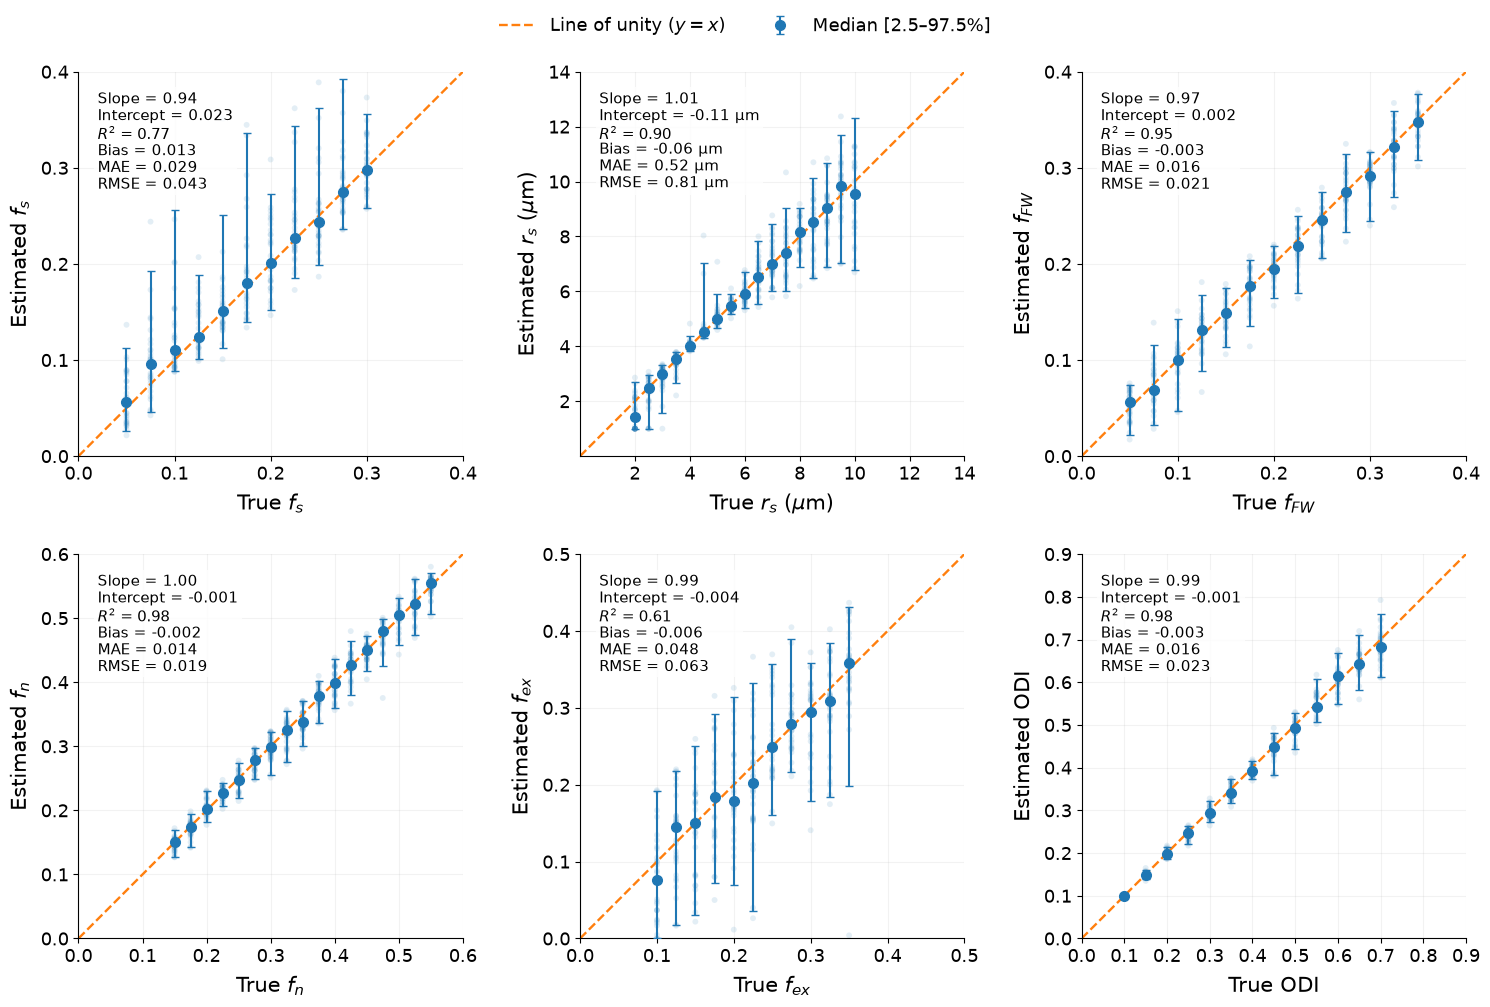


Saved: minimum_acquisition_tort2_plots/figure3_parameter_recovery_sweeps.png


In [51]:
# =============================================================================
# FIGURE 3A — CONTINUOUS PARAMETER RECOVERY
#
# Six independent one-parameter sweeps:
#
#   f_soma | r_soma | f_FW
#   f_n    | f_ex   | ODI
#
# Each panel:
#   - faint points = individual noisy fits
#   - large point  = median estimate across noise realisations
#   - error bars   = empirical 2.5–97.5 percentile interval
#   - dashed line  = perfect recovery (y = x)
#
# This cell ONLY reads existing results.
# It does NOT run any simulations or fitting.
# =============================================================================

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =============================================================================
# 1. LOAD EXISTING SWEEP RESULTS
# =============================================================================

SWEEP_RESULTS_FILE = Path(
    "tort2_continuous_recovery_sweeps_SNR50.csv"
)

if not SWEEP_RESULTS_FILE.exists():
    raise FileNotFoundError(
        f"Could not find {SWEEP_RESULTS_FILE}. "
        "Run/finish the sweep-fitting cells first."
    )

sweep_results_df = pd.read_csv(
    SWEEP_RESULTS_FILE
)

print(
    f"Loaded {len(sweep_results_df)} fitted sweep results."
)

print("\nAvailable sweeps:")
print(
    sweep_results_df[
        "sweep_parameter"
    ]
    .value_counts()
    .sort_index()
)


# =============================================================================
# 2. ENSURE ODI EXISTS
#
# Older primary-sweep rows may not contain ODI / true_ODI because ODI was
# added in the secondary sweep code.
#
# We can safely derive both from kappa without rerunning anything.
# =============================================================================

def kappa_to_odi(kappa):

    kappa = np.asarray(
        kappa,
        dtype=float,
    )

    return (
        2.0
        / np.pi
        * np.arctan(
            1.0 / kappa
        )
    )


# Fitted ODI
if "ODI" not in sweep_results_df.columns:
    sweep_results_df["ODI"] = np.nan

mask = (
    sweep_results_df["ODI"].isna()
    & sweep_results_df["kappa"].notna()
)

sweep_results_df.loc[
    mask,
    "ODI"
] = kappa_to_odi(
    sweep_results_df.loc[
        mask,
        "kappa"
    ].to_numpy()
)


# True ODI
if "true_ODI" not in sweep_results_df.columns:
    sweep_results_df["true_ODI"] = np.nan

mask = (
    sweep_results_df["true_ODI"].isna()
    & sweep_results_df["true_kappa"].notna()
)

sweep_results_df.loc[
    mask,
    "true_ODI"
] = kappa_to_odi(
    sweep_results_df.loc[
        mask,
        "true_kappa"
    ].to_numpy()
)


# =============================================================================
# 3. PARAMETER DEFINITIONS
# =============================================================================

PARAMETERS = {
    "soma_fraction": {
        "truth": "true_soma_fraction",
        "estimate": "soma_fraction",
        "label": r"$f_s$",
        "units": "",
    },

    "r_soma": {
        "truth": "true_r_soma",
        "estimate": "r_soma",
        "label": r"$r_s$",
        "units": r"$\mu$m",
    },

    "csf_fraction": {
        "truth": "true_f_fw",
        "estimate": "csf_fraction",
        "label": r"$f_{FW}$",
        "units": "",
    },

    "neurite_fraction": {
        "truth": "true_neurite_fraction",
        "estimate": "neurite_fraction",
        "label": r"$f_n$",
        "units": "",
    },

    "extra_fraction": {
        "truth": "true_extra_fraction",
        "estimate": "extra_fraction",
        "label": r"$f_{ex}$",
        "units": "",
    },

    "ODI": {
        "truth": "true_ODI",
        "estimate": "ODI",
        "label": "ODI",
        "units": "",
    },
}


# =============================================================================
# 4. KEEP SUCCESSFUL / NUMERIC FITS
# =============================================================================

analysis_df = sweep_results_df.copy()

if "success" in analysis_df.columns:

    # Handles bools or strings loaded from CSV
    success_mask = (
        analysis_df["success"]
        .astype(str)
        .str.lower()
        .isin(
            ["true", "1"]
        )
    )

    analysis_df = analysis_df[
        success_mask
    ].copy()

print(
    f"\nSuccessful fits available for plotting: "
    f"{len(analysis_df)}"
)


# =============================================================================
# 5. SUMMARISE EACH SWEEP VALUE
# =============================================================================

summary_rows = []

for sweep_parameter, info in PARAMETERS.items():

    sub = analysis_df[
        analysis_df["sweep_parameter"]
        == sweep_parameter
    ].copy()

    if sub.empty:
        print(
            f"WARNING: no results for {sweep_parameter}"
        )
        continue

    truth_col = info["truth"]
    estimate_col = info["estimate"]

    sub[truth_col] = pd.to_numeric(
        sub[truth_col],
        errors="coerce",
    )

    sub[estimate_col] = pd.to_numeric(
        sub[estimate_col],
        errors="coerce",
    )

    sub = sub.dropna(
        subset=[
            truth_col,
            estimate_col,
        ]
    )

    for truth_value, group in sub.groupby(
        truth_col
    ):

        estimates = (
            group[estimate_col]
            .to_numpy(dtype=float)
        )

        errors = (
            estimates
            - float(truth_value)
        )

        summary_rows.append({
            "parameter":
                sweep_parameter,

            "truth":
                float(truth_value),

            "median":
                float(
                    np.median(estimates)
                ),

            "mean":
                float(
                    np.mean(estimates)
                ),

            "lower_95":
                float(
                    np.percentile(
                        estimates,
                        2.5,
                    )
                ),

            "upper_95":
                float(
                    np.percentile(
                        estimates,
                        97.5,
                    )
                ),

            "bias":
                float(
                    np.mean(errors)
                ),

            "rmse":
                float(
                    np.sqrt(
                        np.mean(
                            errors ** 2
                        )
                    )
                ),

            "n":
                len(estimates),
        })


sweep_summary_df = pd.DataFrame(
    summary_rows
)

display(
    sweep_summary_df.head()
)


# =============================================================================
# 6. CALCULATE OVERALL RECOVERY STATISTICS
#
# Slope/intercept are calculated using ALL individual noisy fits.
#
# IMPORTANT:
# The regression is used only to calculate slope/intercept/R².
# The regression line is NOT plotted.
# =============================================================================

recovery_stats = []

for sweep_parameter, info in PARAMETERS.items():

    sub = analysis_df[
        analysis_df["sweep_parameter"]
        == sweep_parameter
    ].copy()

    if sub.empty:
        continue

    truth_col = info["truth"]
    estimate_col = info["estimate"]

    x = pd.to_numeric(
        sub[truth_col],
        errors="coerce",
    )

    y = pd.to_numeric(
        sub[estimate_col],
        errors="coerce",
    )

    valid = (
        x.notna()
        & y.notna()
    )

    x = x[valid].to_numpy(
        dtype=float
    )

    y = y[valid].to_numpy(
        dtype=float
    )

    if len(x) < 2:
        continue


    # -------------------------------------------------------------------------
    # Linear relationship
    # -------------------------------------------------------------------------

    slope, intercept = np.polyfit(
        x,
        y,
        1,
    )


    # -------------------------------------------------------------------------
    # Recovery errors relative to truth
    # -------------------------------------------------------------------------

    residual = (
        y - x
    )

    overall_rmse = np.sqrt(
        np.mean(
            residual ** 2
        )
    )

    overall_mae = np.mean(
        np.abs(
            residual
        )
    )

    overall_bias = np.mean(
        residual
    )


    # -------------------------------------------------------------------------
    # R²
    # -------------------------------------------------------------------------

    correlation = np.corrcoef(
        x,
        y,
    )[0, 1]

    r_squared = (
        correlation ** 2
    )


    # -------------------------------------------------------------------------
    # Save
    # -------------------------------------------------------------------------

    recovery_stats.append({

        "parameter":
            sweep_parameter,

        "slope":
            slope,

        "intercept":
            intercept,

        "R_squared":
            r_squared,

        "RMSE":
            overall_rmse,

        "MAE":
            overall_mae,

        "bias":
            overall_bias,

        "n_fits":
            len(x),
    })


recovery_stats_df = pd.DataFrame(
    recovery_stats
)


print(
    "\nOverall recovery statistics:"
)

display(
    recovery_stats_df
)


# =============================================================================
# 7. FIXED AXIS SETTINGS
#
# These determine the final visual scope of each panel.
#
# x and y use EXACTLY the same:
#   - limits
#   - ticks
#
# so the line of unity is visually meaningful.
# =============================================================================

AXIS_SETTINGS = {

    "soma_fraction": {
        "limits": (0.0, 0.4),
        "ticks": np.arange(
            0.0,
            0.41,
            0.1,
        ),
    },

    "r_soma": {
        "limits": (0.0, 14.0),
        "ticks": np.array([
            2,
            4,
            6,
            8,
            10,
            12,
            14,
        ]),
    },

    "csf_fraction": {
        "limits": (0.0, 0.40),
        "ticks": np.arange(
            0.0,
            0.41,
            0.1,
        ),
    },

    "neurite_fraction": {
        "limits": (0.0, 0.60),
        "ticks": np.arange(
            0.0,
            0.61,
            0.1,
        ),
    },

    "extra_fraction": {
        "limits": (0.0, 0.50),
        "ticks": np.arange(
            0.0,
            0.51,
            0.1,
        ),
    },

    "ODI": {
        "limits": (0.0, 0.90),
        "ticks": np.arange(
            0.0,
            0.91,
            0.1,
        ),
    },
}


# Round fraction ticks to avoid floating-point display issues
for parameter_name in AXIS_SETTINGS:

    AXIS_SETTINGS[
        parameter_name
    ]["ticks"] = np.round(
        AXIS_SETTINGS[
            parameter_name
        ]["ticks"],
        2,
    )


# =============================================================================
# 8. SIX-PANEL RECOVERY FIGURE
# =============================================================================

fig, axes = plt.subplots(
    2,
    3,
    figsize=(15, 10),
)

axes = axes.flatten()


for ax, (
    sweep_parameter,
    info,
) in zip(
    axes,
    PARAMETERS.items(),
):

    truth_col = info["truth"]
    estimate_col = info["estimate"]


    # =========================================================================
    # RAW INDIVIDUAL NOISE REALISATIONS
    # =========================================================================

    raw = analysis_df[
        analysis_df["sweep_parameter"]
        == sweep_parameter
    ].copy()

    raw[truth_col] = pd.to_numeric(
        raw[truth_col],
        errors="coerce",
    )

    raw[estimate_col] = pd.to_numeric(
        raw[estimate_col],
        errors="coerce",
    )

    raw = raw.dropna(
        subset=[
            truth_col,
            estimate_col,
        ]
    )


    # =========================================================================
    # SUMMARY VALUES
    # =========================================================================

    summary = (
        sweep_summary_df[
            sweep_summary_df["parameter"]
            == sweep_parameter
        ]
        .sort_values(
            "truth"
        )
        .copy()
    )


    if raw.empty or summary.empty:

        ax.set_visible(
            False
        )

        continue


    # =========================================================================
    # GET FIXED AXIS SETTINGS
    # =========================================================================

    axis_min, axis_max = (
        AXIS_SETTINGS[
            sweep_parameter
        ]["limits"]
    )

    common_ticks = (
        AXIS_SETTINGS[
            sweep_parameter
        ]["ticks"]
    )


    # =========================================================================
    # INDIVIDUAL NOISE REALISATIONS
    # =========================================================================

    ax.scatter(
        raw[truth_col],
        raw[estimate_col],
        s=18,
        alpha=0.12,
        edgecolors="none",
        zorder=1,
    )


    # =========================================================================
    # MEDIAN + EMPIRICAL 95% INTERVAL
    #
    # Error bars represent the 2.5th–97.5th percentile range across
    # independent noisy simulations.
    # =========================================================================

    lower_error = (
        summary["median"]
        - summary["lower_95"]
    )

    upper_error = (
        summary["upper_95"]
        - summary["median"]
    )

    yerr = np.vstack([
        lower_error,
        upper_error,
    ])


    ax.errorbar(
        summary["truth"],
        summary["median"],
        yerr=yerr,
        fmt="o",
        markersize=7,
        capsize=3,
        linewidth=1.5,
        zorder=3,
        label="Median [2.5–97.5%]",
    )


    # =========================================================================
    # LINE OF UNITY
    #
    # IMPORTANT:
    #
    # This is exactly:
    #
    #       y = x
    #
    # It is NOT a fitted regression line.
    # =========================================================================

    ax.plot(
        [
            axis_min,
            axis_max,
        ],
        [
            axis_min,
            axis_max,
        ],
        linestyle="--",
        linewidth=1.7,
        label=r"Line of unity ($y=x$)",
        zorder=2,
    )


    # =========================================================================
    # IDENTICAL X/Y LIMITS
    # =========================================================================

    ax.set_xlim(
        axis_min,
        axis_max,
    )

    ax.set_ylim(
        axis_min,
        axis_max,
    )


    # =========================================================================
    # IDENTICAL X/Y TICKS
    # =========================================================================

    ax.set_xticks(
        common_ticks
    )

    ax.set_yticks(
        common_ticks
    )


    # =========================================================================
    # EQUAL GEOMETRIC SCALING
    #
    # A unit along x occupies the same physical distance as a unit along y.
    #
    # Therefore y=x is displayed at exactly 45 degrees.
    # =========================================================================

    ax.set_aspect(
        "equal",
        adjustable="box",
    )


    # =========================================================================
    # AXIS LABELS
    # =========================================================================

    label = info[
        "label"
    ]

    units = info[
        "units"
    ]


    if units:

        xlabel = (
            f"True {label} ({units})"
        )

        ylabel = (
            f"Estimated {label} ({units})"
        )

    else:

        xlabel = (
            f"True {label}"
        )

        ylabel = (
            f"Estimated {label}"
        )


    ax.set_xlabel(
        xlabel,
        fontsize=15,
        labelpad=7,
    )

    ax.set_ylabel(
        ylabel,
        fontsize=15,
        labelpad=7,
    )


    ax.tick_params(
        axis="both",
        which="major",
        labelsize=13,
    )


    # =========================================================================
    # QUANTITATIVE RECOVERY STATISTICS
    # =========================================================================

    stat = recovery_stats_df[
        recovery_stats_df[
            "parameter"
        ]
        == sweep_parameter
    ]


    if not stat.empty:

        stat = stat.iloc[
            0
        ]


        # ---------------------------------------------------------------------
        # Radius:
        # error quantities carry µm units
        # ---------------------------------------------------------------------

        if sweep_parameter == "r_soma":

            stats_text = (
                f"Slope = {stat['slope']:.2f}\n"
                f"Intercept = {stat['intercept']:.2f} µm\n"
                f"$R^2$ = {stat['R_squared']:.2f}\n"
                f"Bias = {stat['bias']:.2f} µm\n"
                f"MAE = {stat['MAE']:.2f} µm\n"
                f"RMSE = {stat['RMSE']:.2f} µm"
            )


        # ---------------------------------------------------------------------
        # Fractions / ODI
        # ---------------------------------------------------------------------

        else:

            stats_text = (
                f"Slope = {stat['slope']:.2f}\n"
                f"Intercept = {stat['intercept']:.3f}\n"
                f"$R^2$ = {stat['R_squared']:.2f}\n"
                f"Bias = {stat['bias']:.3f}\n"
                f"MAE = {stat['MAE']:.3f}\n"
                f"RMSE = {stat['RMSE']:.3f}"
            )


        # ---------------------------------------------------------------------
        # Statistics box
        # ---------------------------------------------------------------------

        ax.text(
            0.05,
            0.95,
            stats_text,

            transform=ax.transAxes,

            ha="left",
            va="top",

            fontsize=10.5,

            linespacing=1.15,

            bbox=dict(
                facecolor="white",
                edgecolor="none",
                alpha=0.82,
                pad=2.5,
            ),

            zorder=10,
        )


    # =========================================================================
    # APPEARANCE
    # =========================================================================

    ax.grid(
        alpha=0.16,
    )

    ax.spines[
        "top"
    ].set_visible(
        False
    )

    ax.spines[
        "right"
    ].set_visible(
        False
    )


# =============================================================================
# 9. SHARED LEGEND
# =============================================================================

handles, labels = (
    axes[0]
    .get_legend_handles_labels()
)


# Convert to dictionary so we can explicitly control order
legend_dict = dict(
    zip(
        labels,
        handles,
    )
)


desired_order = [
    r"Line of unity ($y=x$)",
    "Median [2.5–97.5%]",
]


ordered_handles = [
    legend_dict[label]
    for label
    in desired_order
    if label
    in legend_dict
]


ordered_labels = [
    label
    for label
    in desired_order
    if label
    in legend_dict
]


fig.legend(
    ordered_handles,
    ordered_labels,

    loc="upper center",

    bbox_to_anchor=(
        0.5,
        1.01,
    ),

    ncol=2,

    frameon=False,

    fontsize=13,
)


# =============================================================================
# 10. LAYOUT
# =============================================================================

fig.tight_layout(
    rect=[
        0,
        0,
        1,
        0.96,
    ],

    w_pad=2.5,

    h_pad=2.5,
)


# =============================================================================
# 11. SAVE
# =============================================================================

PLOT_DIR.mkdir(
    parents=True,
    exist_ok=True,
)


filename = (
    PLOT_DIR
    / "figure3_parameter_recovery_sweeps.png"
)


fig.savefig(
    filename,
    dpi=300,
    bbox_inches="tight",
)


plt.show()


print(
    f"\nSaved: {filename}"
)

,parameter,truth,median,mean,lower,upper,sd,rmse,bias,n
0,soma_fraction,0.050,0.076772,0.079041,0.009792,0.149499,0.043191,0.051446,0.029041,30
1,soma_fraction,0.075,0.102270,0.109376,0.032815,0.228285,0.055014,0.064089,0.034376,30
2,soma_fraction,0.100,0.127478,0.144201,0.082999,0.281830,0.059838,0.073586,0.044201,30
3,soma_fraction,0.125,0.125267,0.139952,0.072235,0.240917,0.045271,0.046954,0.014952,30
4,soma_fraction,0.150,0.150672,0.166582,0.110343,0.288935,0.055473,0.057006,0.016582,30
5,soma_fraction,0.175,0.185341,0.196534,0.112714,0.356122,0.066482,0.068820,0.021534,30
6,soma_fraction,0.200,0.202053,0.210100,0.122701,0.305716,0.055919,0.055899,0.010100,30
7,soma_fraction,0.225,0.237292,0.245313,0.156765,0.355226,0.055817,0.058518,0.020313,30
8,soma_fraction,0.250,0.246689,0.252449,0.183013,0.372013,0.054368,0.053511,0.002449,30
9,soma_fraction,0.275,0.283509,0.293973,0.226560,0.419789,0.050810,0.053437,0.018973,30


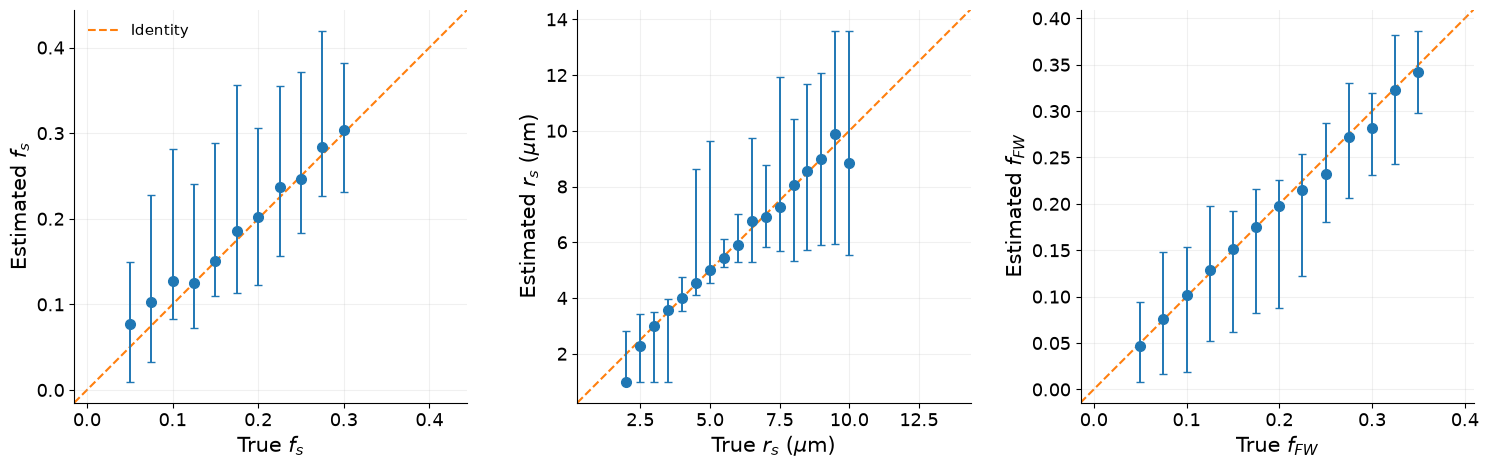

Saved: minimum_acquisition_tort2_plots/figure3A_continuous_parameter_recovery.png


In [ ]:
F_SOMA_SWEEP = np.linspace(0.05, 0.30, 11)
R_SOMA_SWEEP = np.linspace(2.0, 10.0, 0.5)
F_FW_SWEEP   = np.linspace(0.05, 0.35, 13)

REFERENCE_TRUTH = {
    "soma_fraction": 0.15,
    "r_soma": 7.0,
    "csf_fraction": 0.20,
}

# =============================================================================
# FIGURE 3A — PARAMETER RECOVERY ACROSS CONTINUOUS TRUTH SWEEPS
#
# Expected input dataframe:
#
# sweep_results_df
#
# Required columns:
#   sweep_parameter
#   repeat
#
#   soma_fraction
#   r_soma
#   csf_fraction
#
#   true_soma_fraction
#   true_r_soma
#   true_f_fw
#
# Each row should represent one fitted noisy realisation.
# =============================================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt


# =============================================================================
# 1. PARAMETER DEFINITIONS
# =============================================================================

PARAMETERS = {
    "soma_fraction": {
        "truth_column": "true_soma_fraction",
        "label": r"$f_s$",
        "units": "",
    },

    "r_soma": {
        "truth_column": "true_r_soma",
        "label": r"$r_s$",
        "units": r"$\mu$m",
    },

    "csf_fraction": {
        "truth_column": "true_f_fw",
        "label": r"$f_{FW}$",
        "units": "",
    },
}


# =============================================================================
# 2. SUMMARISE RECOVERY AT EACH TRUTH VALUE
#
# Median + 2.5/97.5 percentiles are shown.
#
# You could replace median with mean and CI with SD if preferred.
# =============================================================================

summary_rows = []

for parameter, info in PARAMETERS.items():

    truth_column = info[
        "truth_column"
    ]

    sub = sweep_results_df[
        sweep_results_df[
            "sweep_parameter"
        ] == parameter
    ].copy()

    if sub.empty:
        print(
            f"No sweep results found for "
            f"{parameter}"
        )
        continue

    # Ensure numeric
    sub[parameter] = pd.to_numeric(
        sub[parameter],
        errors="coerce",
    )

    sub[truth_column] = pd.to_numeric(
        sub[truth_column],
        errors="coerce",
    )

    sub = sub.dropna(
        subset=[
            parameter,
            truth_column,
        ]
    )

    for truth_value, group in sub.groupby(
        truth_column
    ):

        estimates = (
            group[parameter]
            .dropna()
            .to_numpy()
        )

        if len(estimates) == 0:
            continue

        summary_rows.append({
            "parameter": parameter,
            "truth": float(
                truth_value
            ),
            "median": float(
                np.median(estimates)
            ),
            "mean": float(
                np.mean(estimates)
            ),
            "lower": float(
                np.percentile(
                    estimates,
                    2.5,
                )
            ),
            "upper": float(
                np.percentile(
                    estimates,
                    97.5,
                )
            ),
            "sd": float(
                np.std(
                    estimates,
                    ddof=1,
                )
            ),
            "rmse": float(
                np.sqrt(
                    np.mean(
                        (
                            estimates
                            - truth_value
                        ) ** 2
                    )
                )
            ),
            "bias": float(
                np.mean(
                    estimates
                    - truth_value
                )
            ),
            "n": len(
                estimates
            ),
        })


sweep_summary_df = pd.DataFrame(
    summary_rows
)

display(
    sweep_summary_df
)


# =============================================================================
# 3. THREE-PANEL RECOVERY FIGURE
# =============================================================================

fig, axes = plt.subplots(
    1,
    3,
    figsize=(15, 5.3),
)


for ax, (
    parameter,
    info,
) in zip(
    axes,
    PARAMETERS.items(),
):

    sub = (
        sweep_summary_df[
            sweep_summary_df[
                "parameter"
            ] == parameter
        ]
        .sort_values(
            "truth"
        )
        .copy()
    )

    if sub.empty:
        ax.set_visible(
            False
        )
        continue

    # ---------------------------------------------------------------------
    # 95% empirical interval
    # ---------------------------------------------------------------------

    yerr = np.vstack([
        sub["median"]
        - sub["lower"],

        sub["upper"]
        - sub["median"],
    ])

    ax.errorbar(
        sub["truth"],
        sub["median"],
        yerr=yerr,
        fmt="o",
        markersize=7,
        capsize=3,
        linewidth=1.4,
        zorder=3,
    )

    # ---------------------------------------------------------------------
    # Identity line
    # ---------------------------------------------------------------------

    data_min = min(
        sub["truth"].min(),
        sub["lower"].min(),
    )

    data_max = max(
        sub["truth"].max(),
        sub["upper"].max(),
    )

    padding = (
        0.06
        * (
            data_max
            - data_min
        )
    )

    axis_min = (
        data_min
        - padding
    )

    axis_max = (
        data_max
        + padding
    )

    ax.plot(
        [
            axis_min,
            axis_max,
        ],
        [
            axis_min,
            axis_max,
        ],
        linestyle="--",
        linewidth=1.5,
        label="Identity",
        zorder=1,
    )

    # ---------------------------------------------------------------------
    # Equal x/y scaling is important for estimated-vs-true plots
    # ---------------------------------------------------------------------

    ax.set_xlim(
        axis_min,
        axis_max,
    )

    ax.set_ylim(
        axis_min,
        axis_max,
    )

    ax.set_aspect(
        "equal",
        adjustable="box",
    )

    # ---------------------------------------------------------------------
    # Labels
    # ---------------------------------------------------------------------

    label = info[
        "label"
    ]

    units = info[
        "units"
    ]

    if units:
        xlabel = (
            f"True {label} "
            f"({units})"
        )

        ylabel = (
            f"Estimated {label} "
            f"({units})"
        )

    else:
        xlabel = (
            f"True {label}"
        )

        ylabel = (
            f"Estimated {label}"
        )

    ax.set_xlabel(
        xlabel,
        fontsize=15,
    )

    ax.set_ylabel(
        ylabel,
        fontsize=15,
    )

    ax.tick_params(
        labelsize=13,
    )

    ax.grid(
        alpha=0.18,
    )

    ax.spines[
        "top"
    ].set_visible(False)

    ax.spines[
        "right"
    ].set_visible(False)


# =============================================================================
# 4. LEGEND
# =============================================================================

axes[0].legend(
    frameon=False,
    fontsize=11,
    loc="upper left",
)


# =============================================================================
# 5. LAYOUT
# =============================================================================

fig.tight_layout(
    w_pad=2.5
)


# =============================================================================
# 6. SAVE
# =============================================================================

filename = (
    PLOT_DIR
    / "figure3A_continuous_parameter_recovery.png"
)

fig.savefig(
    filename,
    dpi=300,
    bbox_inches="tight",
)

plt.show()

print(
    f"Saved: {filename}"
)

In [ ]:
# =============================================================================
# 10. "MINIMUM ACQUISITION" SELECTION
# =============================================================================

passing = acquisition_ranking[
    acquisition_ranking["passes_default_criterion"]
].copy()

if passing.empty:
    print("No acquisition meets the current default thresholds.")
    print("Use acquisition_ranking to choose the best trade-off, or relax the thresholds.")
else:
    minimum = passing.sort_values(
        ["n_measurements", "mean_primary_relative_rmse"]
    ).iloc[0]

    print("Minimum acquisition meeting the current thresholds:")
    print(minimum[[
        "n_measurements",
        "n_dw",
        "mean_primary_relative_rmse",
        "worst_scenario_primary_relative_rmse",
        "success_rate",
    ]])

# Plot performance vs acquisition size.
plot_df = acquisition_ranking.sort_values("n_measurements")

fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(
    plot_df["n_measurements"],
    plot_df["mean_primary_relative_rmse"],
    marker="o",
)
ax.axhline(
    MAX_MEAN_PRIMARY_REL_RMSE,
    linestyle="--",
    linewidth=1.2,
    label="Mean-RRMSE threshold",
)
ax.set_xlabel("Total acquisition measurements")
ax.set_ylabel("Mean primary relative RMSE")
ax.set_title("Acquisition size vs parameter-recovery performance")
ax.grid(alpha=0.25)
ax.legend()
fig.tight_layout()
filename = PLOT_DIR / "acquisition_size_vs_performance.png"
fig.savefig(filename, dpi=200, bbox_inches="tight")
plt.close(fig)
print(f"Saved: {filename}")


Minimum acquisition meeting the current thresholds:
n_measurements                             300.0
n_dw                                       280.0
mean_primary_relative_rmse              0.151612
worst_scenario_primary_relative_rmse    0.180983
success_rate                                 1.0
Name: rm_no_b4_300_strong_high, dtype: object
Saved: minimum_acquisition_tort2_plots/acquisition_size_vs_performance.png


## 11. Best 5 acquisitions for MCMC

MCMC is reserved for the three acquisitions with the lowest mean primary relative RMSE from the LS benchmark. The posterior is sampled for `truth_2` by default. This keeps the MCMC experiment focused while allowing comparison of posterior geometry across acquisitions.

In [ ]:
TOP5_ACQUISITIONS = (
    acquisition_ranking
    .sort_values("mean_primary_relative_rmse")
    .head(5)
    .index
    .tolist()
)

print("Top 5 acquisitions:")
for i, name in enumerate(TOP5_ACQUISITIONS, 1):
    print(f"{i}. {name}")

Top 5 acquisitions:
1. rm_no_b4_300_strong_high
2. rm_no_b4_or_b5_400_low
3. rm_10_shells_400_strong_high
4. rm_no_b3_or_b5_400_edge
5. rm_no_b3_or_b4_300_middle


In [ ]:
EXCLUDE_ACQUISITIONS = [
    "rm_no_b3_or_b4_300_middle",
]

TOP5_ACQUISITIONS = (
    acquisition_ranking
    .drop(
        index=EXCLUDE_ACQUISITIONS,
        errors="ignore",
    )
    .sort_values(
        "mean_primary_relative_rmse"
    )
    .head(5)
    .index
    .tolist()
)

print("Top 5 acquisitions:")
for i, name in enumerate(
    TOP5_ACQUISITIONS,
    1,
):
    print(f"{i}. {name}")

Top 5 acquisitions:
1. rm_no_b4_300_strong_high
2. rm_no_b4_or_b5_400_low
3. rm_10_shells_400_strong_high
4. rm_no_b3_or_b5_400_edge
5. rm_no_b4_400_high


In [22]:
# =============================================================================
# 12. MCMC TARGET
# =============================================================================
#
# MCMC state:
#
#   x = [
#       S0,
#       r_soma,
#       kappa,
#       f_soma,
#       q_neurite,
#       q_extra,
#   ]
#
# The third non-soma composition fraction is derived:
#
#   q_fw = 1 - q_neurite - q_extra
#
# The physical four-compartment fractions are then:
#
#   f_neurite = (1 - f_soma) * q_neurite
#   f_extra   = (1 - f_soma) * q_extra
#   f_fw      = (1 - f_soma) * q_fw
#
# Therefore:
#
#   f_neurite + f_extra + f_soma + f_fw = 1
#
# exactly.
#
# NODDI-informed Gaussian priors are applied to:
#   kappa
#   q_neurite
#   q_extra
#   q_fw
#
# There is deliberately no prior on f_soma.


def gaussian_logpdf(x, mu, sigma):
    return -0.5 * (
        ((x - mu) / sigma) ** 2
    ) - np.log(
        sigma * np.sqrt(2.0 * np.pi)
    )


def mcmc_log_posterior(
    x,
    data,
    acquisition,
    acquisition_name,
    truth,
    noddi,
    *,
    prior_seed=None,
    prior=None,
):
    # -------------------------------------------------------------------------
    # Unpack MCMC state
    # -------------------------------------------------------------------------

    S0 = float(x[0])
    r_soma = float(x[1])
    kappa = float(x[2])
    f_soma = float(x[3])
    q_neurite = float(x[4])
    q_extra = float(x[5])

    # -------------------------------------------------------------------------
    # Basic bounds
    # -------------------------------------------------------------------------

    if not (0.05 <= S0 <= 2.0):
        return -np.inf

    if not (1.0 <= r_soma <= 15.0):
        return -np.inf

    if not (0.0 <= kappa <= 64.0):
        return -np.inf

    if not (0.0 < f_soma < 1.0):
        return -np.inf

    # -------------------------------------------------------------------------
    # Enforce valid non-soma composition
    # -------------------------------------------------------------------------

    q_fw = 1.0 - q_neurite - q_extra

    if q_neurite <= 0.0:
        return -np.inf

    if q_extra <= 0.0:
        return -np.inf

    if q_fw <= 0.0:
        return -np.inf

    # -------------------------------------------------------------------------
    # Convert q composition + explicit f_soma into physical fractions
    # -------------------------------------------------------------------------

    remaining = 1.0 - f_soma

    fractions = {
        "neurite_fraction":
            remaining * q_neurite,

        "extra_fraction":
            remaining * q_extra,

        "soma_fraction":
            f_soma,

        "csf_fraction":
            remaining * q_fw,
    }

    # Numerical sanity check
    fraction_sum = (
        fractions["neurite_fraction"]
        + fractions["extra_fraction"]
        + fractions["soma_fraction"]
        + fractions["csf_fraction"]
    )

    if not np.isclose(
        fraction_sum,
        1.0,
        atol=1e-10,
    ):
        return -np.inf

    # -------------------------------------------------------------------------
    # Full physical parameter dictionary
    # -------------------------------------------------------------------------

    values = {
        "S0": S0,
        "r_soma": r_soma,
        "kappa": kappa,
        "theta": float(DTI_THETA),
        "phi": float(DTI_PHI),
        **fractions,
        "d_in": FIXED_MODEL_DIFFUSIVITIES["d_in"],
        "d_soma": FIXED_MODEL_DIFFUSIVITIES["d_soma"],
        "d_csf": FIXED_MODEL_DIFFUSIVITIES["d_csf"],
    }

    # -------------------------------------------------------------------------
    # Likelihood
    # -------------------------------------------------------------------------

    prediction = simulate_signal(
        tort2_model(),
        acquisition,
        values,
    )

    sigma_data = float(
        np.max(np.abs(data)) / SNR
    )

    log_like = -0.5 * np.sum(
        ((prediction - data) / sigma_data) ** 2
    )

    # -------------------------------------------------------------------------
    # NODDI-informed priors
    # -------------------------------------------------------------------------

    if prior is None:
        prior = make_q_prior(
            truth,
            acquisition_name,
            noddi,
            seed=prior_seed,
        )

    log_prior = (
        gaussian_logpdf(
            kappa,
            prior["kappa_mean"],
            prior["kappa_sd"],
        )
        + gaussian_logpdf(
            q_neurite,
            prior["q_neurite"],
            prior["q_neurite_sd"],
        )
        + gaussian_logpdf(
            q_extra,
            prior["q_extra"],
            prior["q_extra_sd"],
        )
        + gaussian_logpdf(
            q_fw,
            prior["q_fw"],
            prior["q_fw_sd"],
        )
    )

    return float(
        log_like + log_prior
    )


def run_random_walk_mcmc(
    initial,
    log_target,
    *,
    steps,
    burn,
    thin,
    seed,
    proposal_scales,
):
    rng = np.random.default_rng(seed)

    current = np.asarray(
        initial,
        dtype=float,
    ).copy()

    current_lp = log_target(
        current
    )

    if not np.isfinite(
        current_lp
    ):
        raise ValueError(
            "Initial MCMC state has non-finite posterior."
        )

    samples = []
    accepted = 0

    for step in range(steps):

        proposal = (
            current
            + rng.normal(
                0.0,
                proposal_scales,
            )
        )

        proposal_lp = log_target(
            proposal
        )

        if np.isfinite(
            proposal_lp
        ):
            if np.log(
                rng.random()
            ) < (
                proposal_lp
                - current_lp
            ):
                current = proposal
                current_lp = proposal_lp
                accepted += 1

        if (
            step >= burn
            and (
                (step - burn)
                % thin
                == 0
            )
        ):
            samples.append(
                current.copy()
            )

    return (
        np.asarray(samples),
        accepted / float(steps),
    )

In [ ]:
# To run only one acquisition for MCMC refinement

# TOP5_ACQUISITIONS = TOP5_ACQUISITIONS[:1]

# print("MCMC acquisition:")
# print(TOP5_ACQUISITIONS[0])

In [ ]:
MCMC_STEPS = 5000
MCMC_BURN = 1500
MCMC_THIN = 1
MCMC_WALKERS = 32

In [ ]:
# =============================================================================
# 13. RUN ENSEMBLE MCMC FOR TOP 6 ACQUISITIONS
# =============================================================================
#
# Uses the affine-invariant emcee ensemble sampler.
#
# MCMC state:
#   [S0, r_soma, kappa, f_soma, q_neurite, q_extra]
#
# The existing mcmc_log_posterior() is retained, including:
#   - exact likelihood
#   - physical fraction construction
#   - NODDI-informed priors
#
# The NODDI-informed prior is computed ONCE per acquisition and then reused
# throughout the MCMC run.
#
# No LS refit is performed.
# The stored LS result for MCMC_REPEAT is used to initialise the walkers.
# =============================================================================

import emcee

mcmc_outputs = {}

MCMC_REPEATS = [0, 14, 29]
MCMC_WALKERS = 32

# =============================================================================
# MCMC RUN SETTINGS
# =============================================================================

print("\n" + "=" * 70)
print("MCMC RUN CONFIGURATION")
print("=" * 70)

print(f"Truth scenario : {MCMC_TRUTH_SCENARIO}")
print(f"Noise repeats  : {MCMC_REPEATS}")
print(f"Walkers        : {MCMC_WALKERS}")
print(f"Steps          : {MCMC_STEPS}")
print(f"Burn-in        : {MCMC_BURN}")
print(f"Thin           : {MCMC_THIN}")
print(f"SNR            : {SNR}")
print(f"MCMC seed      : {MCMC_SEED}")
print(f"Base data seed : {BASE_SEED}")

print(
    "Proposal scales :",
    np.asarray(MCMC_PROPOSAL_SCALES),
)

print(
    f"\nAcquisitions ({len(TOP5_ACQUISITIONS)}):"
)

for i, name in enumerate(
    TOP5_ACQUISITIONS,
    start=1,
):
    print(f"  {i}. {name}")

print("\nExpected MCMC fits:")
print(
    f"  {len(TOP5_ACQUISITIONS)} acquisitions"
    f" × {len(MCMC_REPEATS)} noise repeats"
    f" = {len(TOP5_ACQUISITIONS) * len(MCMC_REPEATS)} fits"
)

print("=" * 70, flush=True)

for repeat in MCMC_REPEATS:

    print("=" * 70)
    print(
        f"STARTING MCMC REPEAT {repeat}"
    )
    print("=" * 70, flush=True)

    for i, acquisition_name in enumerate(
        TOP5_ACQUISITIONS
    ):

        acquisition_start = time.time()

        print(
            f"\n[Repeat {repeat}] "
            f"[{i + 1}/{len(TOP5_ACQUISITIONS)}] "
            f"{acquisition_name}",
            flush=True,
        )

        acquisition = ACQUISITIONS[
            acquisition_name
        ]

        truth = dict(
            TRUTH_BY_SCENARIO[
                MCMC_TRUTH_SCENARIO
            ]
        )

        # -------------------------------------------------------------
        # DATA
        # -------------------------------------------------------------

        data_seed = (
            BASE_SEED
            + repeat
        )

        truth_signal = simulate_signal(
            tort2_model(),
            acquisition,
            truth,
        )

        data = add_gaussian_noise(
            truth_signal,
            SNR,
            data_seed,
        )

        print(
            f"  Data ready "
            f"(seed={data_seed})",
            flush=True,
        )

        # -------------------------------------------------------------
        # NODDI
        # -------------------------------------------------------------

        noddi_seed = noddi_seed_for(
            acquisition_name,
            repeat,
        )

        noddi = make_noddi_estimate(
            truth,
            acquisition_name,
            noddi_seed,
        )

        # -------------------------------------------------------------
        # PRIOR
        # -------------------------------------------------------------

        ls_seed = (
            BASE_SEED
            + repeat
        )

        prior_seed = (
            ls_seed
            + 123456
        )

        prior = make_q_prior(
            truth,
            acquisition_name,
            noddi,
            seed=prior_seed,
        )

        # -------------------------------------------------------------
        # STORED LS RESULT FOR THIS EXACT REPEAT
        # -------------------------------------------------------------

        ls_rows = results_df[
            (results_df["acquisition"] == acquisition_name)
            & (
                results_df["scenario"]
                == MCMC_TRUTH_SCENARIO
            )
            & (
                results_df["repeat"]
                == repeat
            )
        ]

        if len(ls_rows) != 1:
            raise RuntimeError(
                f"Expected one LS result for "
                f"{acquisition_name}, "
                f"{MCMC_TRUTH_SCENARIO}, "
                f"repeat {repeat}; "
                f"found {len(ls_rows)}."
            )

        fit = ls_rows.iloc[0]

        # -------------------------------------------------------------
        # INITIAL STATE
        # -------------------------------------------------------------

        q_initial = fractions_to_q({
            "neurite_fraction":
                float(fit["neurite_fraction"]),
            "extra_fraction":
                float(fit["extra_fraction"]),
            "soma_fraction":
                float(fit["soma_fraction"]),
            "csf_fraction":
                float(fit["csf_fraction"]),
        })

        x0 = np.array([
            float(fit["S0"]),
            float(fit["r_soma"]),
            float(fit["kappa"]),
            float(fit["soma_fraction"]),
            q_initial["q_neurite"],
            q_initial["q_extra"],
        ])

        ndim = len(x0)

        # -------------------------------------------------------------
        # WALKERS
        # -------------------------------------------------------------

        rng = np.random.default_rng(
            MCMC_SEED
            + 10000 * repeat
            + 100 * i
        )

        initial_state = np.tile(
            x0,
            (MCMC_WALKERS, 1),
        )

        initial_state += rng.normal(
            0.0,
            np.asarray(
                MCMC_PROPOSAL_SCALES
            ),
            size=(
                MCMC_WALKERS,
                ndim,
            ),
        )

        for walker in range(
            MCMC_WALKERS
        ):

            for attempt in range(100):

                lp = mcmc_log_posterior(
                    initial_state[walker],
                    data,
                    acquisition,
                    acquisition_name,
                    truth,
                    noddi,
                    prior=prior,
                )

                if np.isfinite(lp):
                    break

                initial_state[walker] = (
                    x0
                    + rng.normal(
                        0.0,
                        np.asarray(
                            MCMC_PROPOSAL_SCALES
                        ),
                    )
                )

            else:
                raise RuntimeError(
                    f"{acquisition_name}, "
                    f"repeat {repeat}: "
                    f"could not create valid walker "
                    f"{walker}."
                )

        print(
            "  Initial walkers valid.",
            flush=True,
        )

        # -------------------------------------------------------------
        # POSTERIOR
        # -------------------------------------------------------------

        def log_probability(vector):
            return mcmc_log_posterior(
                vector,
                data,
                acquisition,
                acquisition_name,
                truth,
                noddi,
                prior=prior,
            )

        # -------------------------------------------------------------
        # RUN EMCEE
        # -------------------------------------------------------------

        sampler = emcee.EnsembleSampler(
            MCMC_WALKERS,
            ndim,
            log_probability,
        )

        print(
            "  Running ensemble sampler...",
            flush=True,
        )

        sampler.run_mcmc(
            initial_state,
            MCMC_STEPS,
            progress=True,
        )

        # -------------------------------------------------------------
        # DIAGNOSTICS
        # -------------------------------------------------------------

        try:
            tau = sampler.get_autocorr_time(
                tol=0,
                quiet=True,
            )
        except Exception:
            tau = None

        chain = sampler.get_chain(
            discard=MCMC_BURN,
            thin=MCMC_THIN,
        )

        log_prob = sampler.get_log_prob(
            discard=MCMC_BURN,
            thin=MCMC_THIN,
        )

        acceptance = np.asarray(
            sampler.acceptance_fraction
        )

        # -------------------------------------------------------------
        # PHYSICAL PARAMETERS
        # -------------------------------------------------------------

        samples = chain.reshape(
            -1,
            ndim,
        )

        physical = []

        for sample in samples:

            S0 = sample[0]
            r_soma = sample[1]
            kappa = sample[2]
            f_soma = sample[3]
            q_neurite = sample[4]
            q_extra = sample[5]

            q_fw = (
                1.0
                - q_neurite
                - q_extra
            )

            fractions = (
                physical_fractions_from_fsoma(
                    f_soma,
                    {
                        "q_neurite": q_neurite,
                        "q_extra": q_extra,
                        "q_fw": q_fw,
                    },
                )
            )

            physical.append({
                "S0": S0,
                "r_soma": r_soma,
                "kappa": kappa,
                "q_neurite": q_neurite,
                "q_extra": q_extra,
                "q_fw": q_fw,
                **fractions,
            })

        posterior_df = pd.DataFrame(
            physical
        )

        # -------------------------------------------------------------
        # SAVE
        # -------------------------------------------------------------

        posterior_file = (
            MCMC_RESULTS_DIR
            / f"{acquisition_name}_repeat_{repeat}_posterior.csv"
        )

        posterior_df.to_csv(
            posterior_file,
            index=False,
        )

        # -------------------------------------------------------------
        # STORE
        # -------------------------------------------------------------

        mcmc_outputs[
            (
                acquisition_name,
                repeat,
            )
        ] = {
            "posterior": posterior_df,
            "chains": [
                np.transpose(
                    chain,
                    (1, 0, 2),
                )[j]
                for j in range(
                    MCMC_WALKERS
                )
            ],
            "acceptance": acceptance,
            "ls_fit": fit,
            "noddi": noddi,
            "prior": prior,
            "data_seed": data_seed,
            "noddi_seed": noddi_seed,
            "prior_seed": prior_seed,
            "log_probability": log_prob,
            "sampler": sampler,
            "autocorr_time": tau,
            "repeat": repeat,
        }

        print(
            f"  Finished {acquisition_name}, "
            f"repeat {repeat}",
            flush=True,
        )

        print(
            f"    Mean acceptance: "
            f"{np.mean(acceptance):.3f}",
            flush=True,
        )

        print(
            f"    Posterior samples: "
            f"{len(posterior_df)}",
            flush=True,
        )

        print(
            f"    Time: "
            f"{time.time() - acquisition_start:.1f}s",
            flush=True,
        )

print("=" * 70)
print("ENSEMBLE MCMC COMPLETE")
print("=" * 70)


MCMC RUN CONFIGURATION
Truth scenario : truth_2
Noise repeats  : [0, 14, 29]
Walkers        : 32
Steps          : 5000
Burn-in        : 1500
Thin           : 1
SNR            : 20.0
MCMC seed      : 9100
Base data seed : 7000
Proposal scales : [0.01 0.12 0.08 0.01 0.02 0.02]

Acquisitions (5):
  1. rm_no_b4_300_strong_high
  2. rm_no_b4_or_b5_400_low
  3. rm_10_shells_400_strong_high
  4. rm_no_b3_or_b5_400_edge
  5. rm_no_b4_400_high

Expected MCMC fits:
  5 acquisitions × 3 noise repeats = 15 fits
STARTING MCMC REPEAT 0

[Repeat 0] [1/5] rm_no_b4_300_strong_high
  Data ready (seed=7000)
  Initial walkers valid.
  Running ensemble sampler...


100%|██████████| 5000/5000 [1:03:06<00:00,  1.32it/s]


  Finished rm_no_b4_300_strong_high, repeat 0
    Mean acceptance: 0.500
    Posterior samples: 112000
    Time: 3789.4s

[Repeat 0] [2/5] rm_no_b4_or_b5_400_low
  Data ready (seed=7000)
  Initial walkers valid.
  Running ensemble sampler...


100%|██████████| 5000/5000 [1:03:15<00:00,  1.32it/s]


  Finished rm_no_b4_or_b5_400_low, repeat 0
    Mean acceptance: 0.434
    Posterior samples: 112000
    Time: 3798.3s

[Repeat 0] [3/5] rm_10_shells_400_strong_high
  Data ready (seed=7000)
  Initial walkers valid.
  Running ensemble sampler...


...

  Finished rm_10_shells_400_strong_high, repeat 29
    Mean acceptance: 0.446
    Posterior samples: 112000
    Time: 5036.9s

[Repeat 29] [4/5] rm_no_b3_or_b5_400_edge
  Data ready (seed=7029)
  Initial walkers valid.
  Running ensemble sampler...


100%|██████████| 5000/5000 [3:36:42<00:00,  2.60s/it]     


  Finished rm_no_b3_or_b5_400_edge, repeat 29
    Mean acceptance: 0.441
    Posterior samples: 112000
    Time: 13004.7s

[Repeat 29] [5/5] rm_no_b4_400_high
  Data ready (seed=7029)
  Initial walkers valid.
  Running ensemble sampler...


100%|██████████| 5000/5000 [1:15:03<00:00,  1.11it/s]  


  Finished rm_no_b4_400_high, repeat 29
    Mean acceptance: 0.429
    Posterior samples: 112000
    Time: 4505.7s
ENSEMBLE MCMC COMPLETE


In [ ]:
PARAMS = [
    "S0",
    "r_soma",
    "kappa",
    "soma_fraction",
    "q_neurite",
    "q_extra",
]

for key, output in mcmc_outputs.items():

    acquisition_name, repeat = key
    sampler = output["sampler"]

    tau = sampler.get_autocorr_time(
        tol=0,
        quiet=True,
    )

    chain = sampler.get_chain(
        discard=MCMC_BURN,
        thin=MCMC_THIN,
    )

    n_steps_kept = chain.shape[0]
    n_walkers = chain.shape[1]

    ess = (
        n_steps_kept
        * n_walkers
        / tau
    )

    print(
        f"\n{acquisition_name} "
        f"(repeat {repeat})"
    )

    print("Autocorrelation time:")
    for parameter, value in zip(
        PARAMS,
        tau,
    ):
        print(
            f"  {parameter:16s} "
            f"tau={value:.1f}"
        )

    print("Approximate ESS:")
    for parameter, value in zip(
        PARAMS,
        ess,
    ):
        print(
            f"  {parameter:16s} "
            f"ESS={value:.0f}"
        )

    print("Chain length / autocorrelation time:")
    for parameter, value in zip(
        PARAMS,
        tau,
    ):
        ratio = n_steps_kept / value

        status = (
            "OK"
            if ratio >= 50
            else "CHECK"
        )

        print(
            f"  {parameter:16s} "
            f"ratio={ratio:.1f}  {status}"
        )


rm_no_b4_300_strong_high (repeat 0)
Autocorrelation time:
  S0               tau=58.6
  r_soma           tau=70.5
  kappa            tau=76.6
  soma_fraction    tau=66.9
  q_neurite        tau=65.4
  q_extra          tau=70.8
Approximate ESS:
  S0               ESS=1912
  r_soma           ESS=1590
  kappa            ESS=1461
  soma_fraction    ESS=1674
  q_neurite        ESS=1711
  q_extra          ESS=1582
Chain length / autocorrelation time:
  S0               ratio=59.7  OK
  r_soma           ratio=49.7  CHECK
  kappa            ratio=45.7  CHECK
  soma_fraction    ratio=52.3  OK
  q_neurite        ratio=53.5  OK
  q_extra          ratio=49.4  CHECK

rm_no_b4_or_b5_400_low (repeat 0)
Autocorrelation time:
  S0               tau=80.0
  r_soma           tau=188.3
  kappa            tau=126.2
  soma_fraction    tau=122.2
  q_neurite        tau=148.1
  q_extra          tau=91.2
Approximate ESS:
  S0               ESS=1401
  r_soma           ESS=595
  kappa            ESS=888
  soma_fra

In [ ]:
comparison_rows = []

for (acquisition_name, repeat), output in mcmc_outputs.items():

    ls = output["ls_fit"]
    post = output["posterior"]

    truth = TRUTH_BY_SCENARIO[
        MCMC_TRUTH_SCENARIO
    ]

    for parameter in [
        "S0",
        "r_soma",
        "kappa",
        "soma_fraction",
        "csf_fraction",
        "neurite_fraction",
        "extra_fraction",
    ]:

        true_value = truth[parameter]

        comparison_rows.append({
            "acquisition": acquisition_name,
            "repeat": repeat,
            "parameter": parameter,
            "truth": true_value,

            "LS": float(ls[parameter]),
            "LS_error": (
                float(ls[parameter])
                - true_value
            ),

            "MCMC_mean": post[parameter].mean(),
            "MCMC_error": (
                post[parameter].mean()
                - true_value
            ),

            "MCMC_sd": post[parameter].std(
                ddof=1
            ),

            "MCMC_q025": post[parameter].quantile(
                0.025
            ),

            "MCMC_q975": post[parameter].quantile(
                0.975
            ),
        })

ls_vs_mcmc = pd.DataFrame(
    comparison_rows
)

pd.set_option("display.max_rows", None)
pd.set_option("display.max_columns", None)
pd.set_option("display.width", None)

display(
    ls_vs_mcmc.sort_values(
        ["acquisition", "repeat", "parameter"]
    )
)

,acquisition,repeat,parameter,truth,LS,LS_error,MCMC_mean,MCMC_error,MCMC_sd,MCMC_q025,MCMC_q975
14,rm_10_shells_400_strong_high,0,S0,1.000000,0.996175,-0.003825,0.995904,-0.004096,0.011697,0.973391,1.019167
18,rm_10_shells_400_strong_high,0,csf_fraction,0.200000,0.177265,-0.022735,0.167880,-0.032120,0.031018,0.104162,0.226827
20,rm_10_shells_400_strong_high,0,extra_fraction,0.216667,0.245633,0.028966,0.240736,0.024070,0.049180,0.144517,0.338771
16,rm_10_shells_400_strong_high,0,kappa,2.000000,2.148205,0.148205,2.119077,0.119077,0.173969,1.803997,2.486907
19,rm_10_shells_400_strong_high,0,neurite_fraction,0.433333,0.417702,-0.015632,0.425723,-0.007610,0.029259,0.363154,0.477809
15,rm_10_shells_400_strong_high,0,r_soma,7.000000,6.853311,-0.146689,7.239686,0.239686,0.830773,5.963940,9.121347
17,rm_10_shells_400_strong_high,0,soma_fraction,0.150000,0.159401,0.009401,0.165660,0.015660,0.039721,0.090715,0.247582
49,rm_10_shells_400_strong_high,14,S0,1.000000,0.990069,-0.009931,0.989948,-0.010052,0.011617,0.967321,1.012915
53,rm_10_shells_400_strong_high,14,csf_fraction,0.200000,0.219344,0.019344,0.211669,0.011669,0.029927,0.151245,0.268332
55,rm_10_shells_400_strong_high,14,extra_fraction,0.216667,0.198487,-0.018179,0.187643,-0.029024,0.049457,0.093015,0.284085


In [ ]:
# =============================================================================
# 14. MCMC POSTERIOR SUMMARY + DEGENERACY CORRELATIONS
# =============================================================================

POSTERIOR_PARAMETERS = [
    "r_soma",
    "soma_fraction",
    "csf_fraction",
    "q_neurite",
    "q_extra",
    "q_fw",
    "kappa",
]

mcmc_summary_rows = []

for (acquisition_name, repeat), output in (
    mcmc_outputs.items()
):

    posterior = output["posterior"]

    for parameter in POSTERIOR_PARAMETERS:

        values = posterior[
            parameter
        ].to_numpy()

        q025, q50, q975 = np.quantile(
            values,
            [0.025, 0.50, 0.975],
        )

        mcmc_summary_rows.append({
            "acquisition": acquisition_name,
            "repeat": repeat,
            "parameter": parameter,
            "mean": values.mean(),
            "sd": values.std(ddof=1),
            "q025": q025,
            "median": q50,
            "q975": q975,
        })

mcmc_summary_df = pd.DataFrame(
    mcmc_summary_rows
)

display(
    mcmc_summary_df.sort_values(
        [
            "acquisition",
            "repeat",
            "parameter",
        ]
    )
)

,acquisition,repeat,parameter,mean,sd,q025,median,q975
16,rm_10_shells_400_strong_high,0,csf_fraction,0.167880,0.031018,0.104162,0.168575,0.226827
20,rm_10_shells_400_strong_high,0,kappa,2.119077,0.173969,1.803997,2.110125,2.486907
18,rm_10_shells_400_strong_high,0,q_extra,0.287082,0.050131,0.187344,0.287280,0.385991
19,rm_10_shells_400_strong_high,0,q_fw,0.202040,0.040305,0.121363,0.201976,0.280512
17,rm_10_shells_400_strong_high,0,q_neurite,0.510878,0.036111,0.440985,0.510419,0.585653
...,...,...,...,...,...,...,...,...
81,rm_no_b4_or_b5_400_low,29,q_extra,0.294705,0.055914,0.182927,0.296466,0.403421
82,rm_no_b4_or_b5_400_low,29,q_fw,0.221115,0.043637,0.136017,0.221596,0.305671
80,rm_no_b4_or_b5_400_low,29,q_neurite,0.484180,0.048742,0.395530,0.481939,0.580659
77,rm_no_b4_or_b5_400_low,29,r_soma,6.618818,1.521656,4.866609,6.219102,11.161890


In [ ]:
correlation_rows = []

for (acquisition_name, repeat), output in (
    mcmc_outputs.items()
):

    posterior = output["posterior"][
        POSTERIOR_PARAMETERS
    ]

    corr = posterior.corr()

    for i, parameter_1 in enumerate(
        POSTERIOR_PARAMETERS
    ):

        for j, parameter_2 in enumerate(
            POSTERIOR_PARAMETERS
        ):

            if j <= i:
                continue

            r = corr.loc[
                parameter_1,
                parameter_2,
            ]

            if abs(r) >= 0.5:

                correlation_rows.append({
                    "acquisition": acquisition_name,
                    "repeat": repeat,
                    "parameter_1": parameter_1,
                    "parameter_2": parameter_2,
                    "correlation": r,
                    "abs_correlation": abs(r),
                })

correlation_df = (
    pd.DataFrame(correlation_rows)
    .sort_values(
        [
            "acquisition",
            "repeat",
            "abs_correlation",
        ],
        ascending=[
            True,
            True,
            False,
        ],
    )
)

display(correlation_df)

,acquisition,repeat,parameter_1,parameter_2,correlation,abs_correlation
17,rm_10_shells_400_strong_high,0,csf_fraction,q_fw,0.971935,0.971935
14,rm_10_shells_400_strong_high,0,r_soma,q_neurite,0.836393,0.836393
19,rm_10_shells_400_strong_high,0,q_extra,q_fw,-0.701212,0.701212
15,rm_10_shells_400_strong_high,0,soma_fraction,q_extra,-0.609029,0.609029
18,rm_10_shells_400_strong_high,0,q_neurite,q_extra,-0.605598,0.605598
16,rm_10_shells_400_strong_high,0,csf_fraction,q_extra,-0.604069,0.604069
59,rm_10_shells_400_strong_high,14,csf_fraction,q_fw,0.958038,0.958038
53,rm_10_shells_400_strong_high,14,r_soma,q_neurite,0.900485,0.900485
62,rm_10_shells_400_strong_high,14,q_extra,q_fw,-0.654375,0.654375
60,rm_10_shells_400_strong_high,14,q_neurite,q_extra,-0.648567,0.648567


In [ ]:
# =============================================================================
# POSTERIOR CORRELATION HEATMAPS
# One heatmap per acquisition × noise repeat
# =============================================================================

HEATMAP_PARAMETERS = [
    "r_soma",
    "neurite_fraction",
    "extra_fraction",
    "soma_fraction",
    "csf_fraction",
    "kappa",
]

HEATMAP_LABELS = {
    "r_soma": r"$r_{\mathrm{soma}}$",
    "neurite_fraction": r"$f_{\mathrm{neurite}}$",
    "extra_fraction": r"$f_{\mathrm{extra}}$",
    "soma_fraction": r"$f_{\mathrm{soma}}$",
    "csf_fraction": r"$f_{\mathrm{FW}}$",
    "kappa": r"$\kappa$",
}


for (acquisition_name, repeat), output in (
    mcmc_outputs.items()
):

    posterior = output[
        "posterior"
    ][HEATMAP_PARAMETERS]

    corr = posterior.corr()

    # -------------------------------------------------------------------------
    # Plot
    # -------------------------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(8, 7),
        constrained_layout=True,
    )

    im = ax.imshow(
        corr,
        vmin=-1,
        vmax=1,
        cmap="coolwarm",
    )

    labels = [
        HEATMAP_LABELS[p]
        for p in HEATMAP_PARAMETERS
    ]

    ax.set_xticks(
        range(len(labels))
    )

    ax.set_yticks(
        range(len(labels))
    )

    ax.set_xticklabels(
        labels,
        rotation=45,
        ha="right",
    )

    ax.set_yticklabels(
        labels
    )

    # -------------------------------------------------------------------------
    # Correlation values
    # -------------------------------------------------------------------------

    for i in range(
        len(HEATMAP_PARAMETERS)
    ):

        for j in range(
            len(HEATMAP_PARAMETERS)
        ):

            value = corr.iloc[
                i,
                j,
            ]

            text_color = (
                "white"
                if abs(value) > 0.5
                else "black"
            )

            ax.text(
                j,
                i,
                f"{value:.2f}",
                ha="center",
                va="center",
                fontsize=9,
                color=text_color,
            )

    ax.set_title(
        f"Posterior correlation matrix\n"
        f"{acquisition_name} — repeat {repeat}"
    )

    fig.colorbar(
        im,
        ax=ax,
        label="Pearson correlation",
    )

    # -------------------------------------------------------------------------
    # Save
    # -------------------------------------------------------------------------

    filename = (
        MCMC_RESULTS_DIR
        / (
            f"{acquisition_name}"
            f"_repeat_{repeat}"
            f"_posterior_correlation_heatmap.png"
        )
    )

    fig.savefig(
        filename,
        dpi=200,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(
        f"Saved: {filename}"
    )

    # -------------------------------------------------------------------------
    # Strong correlations
    # -------------------------------------------------------------------------

    print(
        f"\n{acquisition_name} "
        f"— repeat {repeat}"
    )

    print(
        "Strong posterior correlations "
        "(|r| > 0.7):"
    )

    for i in range(
        len(HEATMAP_PARAMETERS)
    ):

        for j in range(
            i + 1,
            len(HEATMAP_PARAMETERS),
        ):

            value = corr.iloc[
                i,
                j,
            ]

            if abs(value) > 0.7:

                print(
                    f"  "
                    f"{HEATMAP_PARAMETERS[i]:18s} "
                    f"↔ "
                    f"{HEATMAP_PARAMETERS[j]:18s} "
                    f"{value:7.3f}"
                )

Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_300_strong_high_repeat_0_posterior_correlation_heatmap.png

rm_no_b4_300_strong_high — repeat 0
Strong posterior correlations (|r| > 0.7):
  extra_fraction     ↔ soma_fraction       -0.770
Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_or_b5_400_low_repeat_0_posterior_correlation_heatmap.png

rm_no_b4_or_b5_400_low — repeat 0
Strong posterior correlations (|r| > 0.7):
  neurite_fraction   ↔ kappa               -0.752
  extra_fraction     ↔ soma_fraction       -0.723
Saved: minimum_acquisition_tort2_mcmc/rm_10_shells_400_strong_high_repeat_0_posterior_correlation_heatmap.png

rm_10_shells_400_strong_high — repeat 0
Strong posterior correlations (|r| > 0.7):
  r_soma             ↔ neurite_fraction     0.716
  extra_fraction     ↔ soma_fraction       -0.740
Saved: minimum_acquisition_tort2_mcmc/rm_no_b3_or_b5_400_edge_repeat_0_posterior_correlation_heatmap.png

rm_no_b3_or_b5_400_edge — repeat 0
Strong posterior correlations (|r| > 0.7):
  ne

In [ ]:
# =============================================================================
# Pairwise posterior plots — r_soma, all physical fractions, ODI
# Dashed red lines indicate ground truth
# One plot per acquisition × noise repeat
# =============================================================================

PAIR_PARAMETERS = [
    "r_soma",
    "neurite_fraction",
    "extra_fraction",
    "soma_fraction",
    "csf_fraction",
    "odi",
]

PAIR_LABELS = {
    "r_soma": r"$r_{\mathrm{soma}}$",
    "neurite_fraction": r"$f_{\mathrm{neurite}}$",
    "extra_fraction": r"$f_{\mathrm{extra}}$",
    "soma_fraction": r"$f_{\mathrm{soma}}$",
    "csf_fraction": r"$f_{\mathrm{FW}}$",
    "odi": "ODI",
}

truth = TRUTH_BY_SCENARIO[
    MCMC_TRUTH_SCENARIO
]

TRUTH_VALUES = {
    "r_soma": truth["r_soma"],
    "neurite_fraction": truth["neurite_fraction"],
    "extra_fraction": truth["extra_fraction"],
    "soma_fraction": truth["soma_fraction"],
    "csf_fraction": truth["csf_fraction"],
    "odi": (
        2.0 / np.pi
    ) * np.arctan2(
        1.0,
        truth["kappa"],
    ),
}

for (acquisition_name, repeat), output in (
    mcmc_outputs.items()
):

    posterior = output["posterior"].copy()

    # -------------------------------------------------------------------------
    # Derive ODI from fitted kappa
    # -------------------------------------------------------------------------

    posterior["odi"] = (
        2.0 / np.pi
    ) * np.arctan2(
        1.0,
        posterior["kappa"],
    )

    # -------------------------------------------------------------------------
    # Pairwise posterior figure
    # -------------------------------------------------------------------------

    n_params = len(PAIR_PARAMETERS)

    fig, axes = plt.subplots(
        n_params,
        n_params,
        figsize=(16, 16),
        constrained_layout=True,
    )

    for i, p1 in enumerate(
        PAIR_PARAMETERS
    ):
        for j, p2 in enumerate(
            PAIR_PARAMETERS
        ):

            ax = axes[i, j]

            if i == j:

                ax.hist(
                    posterior[p1],
                    bins=35,
                )

                ax.axvline(
                    TRUTH_VALUES[p1],
                    color="red",
                    linestyle="--",
                    linewidth=1.5,
                )

            elif i > j:

                ax.scatter(
                    posterior[p2],
                    posterior[p1],
                    s=3,
                    alpha=0.15,
                )

                ax.axvline(
                    TRUTH_VALUES[p2],
                    color="red",
                    linestyle="--",
                    linewidth=1.2,
                )

                ax.axhline(
                    TRUTH_VALUES[p1],
                    color="red",
                    linestyle="--",
                    linewidth=1.2,
                )

            else:

                ax.axis("off")
                continue

            if i == n_params - 1:
                ax.set_xlabel(
                    PAIR_LABELS[p2]
                )

            if j == 0:
                ax.set_ylabel(
                    PAIR_LABELS[p1]
                )

            ax.grid(
                alpha=0.2
            )

    fig.suptitle(
        f"Posterior geometry: "
        f"{acquisition_name} — repeat {repeat}",
        y=1.02,
    )

    filename = (
        MCMC_RESULTS_DIR
        / (
            f"{acquisition_name}"
            f"_repeat_{repeat}"
            f"_posterior_physical_parameters.png"
        )
    )

    fig.savefig(
        filename,
        dpi=200,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(
        f"Saved: {filename}"
    )

Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_300_strong_high_repeat_0_posterior_physical_parameters.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_or_b5_400_low_repeat_0_posterior_physical_parameters.png
Saved: minimum_acquisition_tort2_mcmc/rm_10_shells_400_strong_high_repeat_0_posterior_physical_parameters.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b3_or_b5_400_edge_repeat_0_posterior_physical_parameters.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_400_high_repeat_0_posterior_physical_parameters.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_300_strong_high_repeat_14_posterior_physical_parameters.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_or_b5_400_low_repeat_14_posterior_physical_parameters.png
Saved: minimum_acquisition_tort2_mcmc/rm_10_shells_400_strong_high_repeat_14_posterior_physical_parameters.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b3_or_b5_400_edge_repeat_14_posterior_physical_parameters.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_

In [ ]:
# =============================================================================
# MCMC TRACE PLOTS — PHYSICAL PARAMETERS / CHECK WALKER MIXING
# =============================================================================

TRACE_PARAMETERS = [
    "r_soma",
    "neurite_fraction",
    "extra_fraction",
    "soma_fraction",
    "csf_fraction",
    "odi",
]

TRACE_LABELS = {
    "r_soma": r"$r_{\mathrm{soma}}$",
    "neurite_fraction": r"$f_{\mathrm{neurite}}$",
    "extra_fraction": r"$f_{\mathrm{extra}}$",
    "soma_fraction": r"$f_{\mathrm{soma}}$",
    "csf_fraction": r"$f_{\mathrm{FW}}$",
    "odi": "ODI",
}

for (acquisition_name, repeat), output in (
    mcmc_outputs.items()
):

    chains = output["chains"]

    chain_physical = []

    # -------------------------------------------------------------------------
    # Convert each emcee walker to physical parameters
    # -------------------------------------------------------------------------

    for chain in chains:

        chain = np.asarray(chain)

        r_soma = chain[:, 1]
        kappa = chain[:, 2]
        f_soma = chain[:, 3]

        q_neurite = chain[:, 4]
        q_extra = chain[:, 5]

        q_fw = (
            1.0
            - q_neurite
            - q_extra
        )

        # Physical fractions
        non_soma = 1.0 - f_soma

        f_neurite = (
            non_soma
            * q_neurite
        )

        f_extra = (
            non_soma
            * q_extra
        )

        f_fw = (
            non_soma
            * q_fw
        )

        # kappa -> ODI
        odi = (
            2.0 / np.pi
        ) * np.arctan2(
            1.0,
            kappa,
        )

        chain_physical.append({
            "r_soma": r_soma,
            "neurite_fraction": f_neurite,
            "extra_fraction": f_extra,
            "soma_fraction": f_soma,
            "csf_fraction": f_fw,
            "odi": odi,
        })

    # -------------------------------------------------------------------------
    # Trace plots
    # -------------------------------------------------------------------------

    fig, axes = plt.subplots(
        len(TRACE_PARAMETERS),
        1,
        figsize=(
            11,
            2.2 * len(TRACE_PARAMETERS),
        ),
        sharex=True,
        constrained_layout=True,
    )

    for ax, parameter in zip(
        axes,
        TRACE_PARAMETERS,
    ):

        for walker_id, physical in enumerate(
            chain_physical,
            start=1,
        ):

            ax.plot(
                physical[parameter],
                linewidth=0.5,
                alpha=0.35,
            )

        ax.set_ylabel(
            TRACE_LABELS[parameter]
        )

        ax.grid(
            alpha=0.2
        )

    axes[-1].set_xlabel(
        "Post-burn-in MCMC iteration"
    )

    fig.suptitle(
        f"MCMC trace plots: "
        f"{acquisition_name} — repeat {repeat}",
        y=1.02,
    )

    filename = (
        MCMC_RESULTS_DIR
        / (
            f"{acquisition_name}"
            f"_repeat_{repeat}"
            f"_trace_plots.png"
        )
    )

    fig.savefig(
        filename,
        dpi=200,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(
        f"Saved: {filename}"
    )

Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_300_strong_high_repeat_0_trace_plots.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_or_b5_400_low_repeat_0_trace_plots.png
Saved: minimum_acquisition_tort2_mcmc/rm_10_shells_400_strong_high_repeat_0_trace_plots.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b3_or_b5_400_edge_repeat_0_trace_plots.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_400_high_repeat_0_trace_plots.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_300_strong_high_repeat_14_trace_plots.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_or_b5_400_low_repeat_14_trace_plots.png
Saved: minimum_acquisition_tort2_mcmc/rm_10_shells_400_strong_high_repeat_14_trace_plots.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b3_or_b5_400_edge_repeat_14_trace_plots.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_400_high_repeat_14_trace_plots.png
Saved: minimum_acquisition_tort2_mcmc/rm_no_b4_300_strong_high_repeat_29_trace_plots.png
Saved: minimum_acquisition_tort2_mcmc/

In [ ]:
# =============================================================================
# MCMC POSTERIOR RECOVERY PLOTS — TOP ACQUISITIONS, MULTIPLE REPEATS
# =============================================================================

MCMC_PLOT_PARAMETERS = [
    "r_soma",
    "neurite_fraction",
    "extra_fraction",
    "soma_fraction",
    "csf_fraction",
    "odi",
]

MCMC_PLOT_LABELS = {
    "r_soma": r"$r_{\mathrm{soma}}$",
    "neurite_fraction": r"$f_{\mathrm{neurite}}$",
    "extra_fraction": r"$f_{\mathrm{extra}}$",
    "soma_fraction": r"$f_{\mathrm{soma}}$",
    "csf_fraction": r"$f_{\mathrm{FW}}$",
    "odi": "ODI",
}

MCMC_PLOT_UNITS = {
    "r_soma": "µm",
    "neurite_fraction": "",
    "extra_fraction": "",
    "soma_fraction": "",
    "csf_fraction": "",
    "odi": "",
}

truth = TRUTH_BY_SCENARIO[
    MCMC_TRUTH_SCENARIO
]

TRUE_VALUES = {
    "r_soma": truth["r_soma"],
    "neurite_fraction": truth["neurite_fraction"],
    "extra_fraction": truth["extra_fraction"],
    "soma_fraction": truth["soma_fraction"],
    "csf_fraction": truth["csf_fraction"],
    "odi": (
        2.0 / np.pi
    ) * np.arctan2(
        1.0,
        truth["kappa"],
    ),
}

# Use whichever finalist list you are currently using
MCMC_ACQUISITIONS = TOP5_ACQUISITIONS

for parameter in MCMC_PLOT_PARAMETERS:

    repeat_means = {}
    repeat_sds = {}

    # ---------------------------------------------------------------------
    # Collect each noise repeat
    # ---------------------------------------------------------------------

    for acquisition_name in MCMC_ACQUISITIONS:

        repeat_values = []
        repeat_sds_for_parameter = []

        for repeat in MCMC_REPEATS:

            output = mcmc_outputs[
                (acquisition_name, repeat)
            ]

            posterior = output[
                "posterior"
            ].copy()

            posterior["odi"] = (
                2.0 / np.pi
            ) * np.arctan2(
                1.0,
                posterior["kappa"],
            )

            repeat_values.append(
                posterior[parameter].mean()
            )

            repeat_sds_for_parameter.append(
                posterior[parameter].std(
                    ddof=1
                )
            )

        repeat_means[
            acquisition_name
        ] = np.asarray(
            repeat_values
        )

        repeat_sds[
            acquisition_name
        ] = np.asarray(
            repeat_sds_for_parameter
        )

    # ---------------------------------------------------------------------
    # Plot
    # ---------------------------------------------------------------------

    fig, ax = plt.subplots(
        figsize=(10, 6)
    )

    x = np.arange(
        len(MCMC_ACQUISITIONS)
    )

    for i, acquisition_name in enumerate(
        MCMC_ACQUISITIONS
    ):

        values = repeat_means[
            acquisition_name
        ]

        sds = repeat_sds[
            acquisition_name
        ]

        # Individual noise repeats
        ax.scatter(
            np.full(
                len(values),
                x[i],
            ),
            values,
            s=35,
            alpha=0.35,
        )

        # Mean across repeats
        ax.errorbar(
            x[i],
            values.mean(),
            yerr=values.std(
                ddof=1
            ),
            fmt="o",
            capsize=5,
            linewidth=1.5,
            markersize=7,
        )

    # ---------------------------------------------------------------------
    # Truth
    # ---------------------------------------------------------------------

    ax.axhline(
        TRUE_VALUES[parameter],
        linestyle="--",
        linewidth=1.5,
    )

    ax.set_xticks(x)

    ax.set_xticklabels(
        MCMC_ACQUISITIONS,
        rotation=35,
        ha="right",
    )

    units = MCMC_PLOT_UNITS[
        parameter
    ]

    if units:
        ax.set_ylabel(
            f"{MCMC_PLOT_LABELS[parameter]} ({units})"
        )
    else:
        ax.set_ylabel(
            MCMC_PLOT_LABELS[parameter]
        )

    ax.set_title(
        f"MCMC posterior recovery of "
        f"{MCMC_PLOT_LABELS[parameter]}"
        f" across noise repeats"
    )

    ax.grid(
        alpha=0.25
    )

    fig.tight_layout()

    filename = (
        MCMC_RESULTS_DIR
        / f"mcmc_recovery_{parameter}_multi_repeat.png"
    )

    fig.savefig(
        filename,
        dpi=200,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(
        f"Saved: {filename}"
    )

Saved: minimum_acquisition_tort2_mcmc/mcmc_recovery_r_soma_multi_repeat.png
Saved: minimum_acquisition_tort2_mcmc/mcmc_recovery_neurite_fraction_multi_repeat.png
Saved: minimum_acquisition_tort2_mcmc/mcmc_recovery_extra_fraction_multi_repeat.png
Saved: minimum_acquisition_tort2_mcmc/mcmc_recovery_soma_fraction_multi_repeat.png
Saved: minimum_acquisition_tort2_mcmc/mcmc_recovery_csf_fraction_multi_repeat.png
Saved: minimum_acquisition_tort2_mcmc/mcmc_recovery_odi_multi_repeat.png


## 15. Fixed-diffusivity robustness

The fit remains fixed to the nominal values:

- `d_in = 2.2`
- `d_soma = 3.0`
- `d_fw/d_csf = 3.0`

while the **synthetic truth** is deliberately moved away from the fixed value. This asks:

> How much bias do we introduce into the parameters of interest if the assumed fixed diffusivity is wrong?

The default mode changes one true diffusivity at a time. `full_grid` is available but is substantially more expensive.

In [ ]:
# =============================================================================
# 16. ROBUSTNESS BENCHMARK ON BEST ACQUISITION
# =============================================================================

if ROBUSTNESS_MODE == "one_at_a_time":
    robustness_scenarios = []
    for parameter, factors in MISFIX_FACTORS.items():
        for factor in factors:
            robustness_scenarios.append({
                "misfixed_parameter": parameter,
                "factor": float(factor),
                "d_in": TRUE_BASE["d_in"],
                "d_soma": TRUE_BASE["d_soma"],
                "d_csf": TRUE_BASE["d_csf"],
            })
            robustness_scenarios[-1][parameter] *= factor
else:
    robustness_scenarios = []
    for fi, fs, fc in itertools.product(
        MISFIX_FACTORS["d_in"],
        MISFIX_FACTORS["d_soma"],
        MISFIX_FACTORS["d_csf"],
    ):
        robustness_scenarios.append({
            "misfixed_parameter": "joint",
            "factor_d_in": float(fi),
            "factor_d_soma": float(fs),
            "factor_d_csf": float(fc),
            "d_in": TRUE_BASE["d_in"] * fi,
            "d_soma": TRUE_BASE["d_soma"] * fs,
            "d_csf": TRUE_BASE["d_csf"] * fc,
        })

robust_results = []

for acquisition_name in TOP5_ACQUISITIONS:
    acquisition = ACQUISITIONS[acquisition_name]

    for scenario_name in TRUTH_SCENARIOS_TO_RUN:
        baseline_truth = TRUTH_BY_SCENARIO[scenario_name]

        for misfix_id, misfix in enumerate(robustness_scenarios):
            truth = dict(baseline_truth)
            truth.update({
                "d_in": misfix["d_in"],
                "d_soma": misfix["d_soma"],
                "d_csf": misfix["d_csf"],
            })

            truth_signal = simulate_signal(
                tort2_model(),
                acquisition,
                truth,
            )

            for rep in range(ROBUSTNESS_REPEATS):
                seed = 30000 + 1000 * misfix_id + rep
                data = add_gaussian_noise(
                    truth_signal,
                    SNR,
                    seed,
                )

                noddi = make_noddi_estimate(
                    truth,
                    acquisition_name,
                    NODDI_SEED + seed,
                )

                try:
                    fit = fit_tort2_ls(
                        data,
                        acquisition,
                        acquisition_name,
                        truth,
                        noddi,
                        seed=seed,
                        fixed_diffusivities=FIXED_MODEL_DIFFUSIVITIES,
                    )

                    row = {
                        "acquisition": acquisition_name,
                        "scenario": scenario_name,
                        "misfixed_parameter": misfix["misfixed_parameter"],
                        "factor": misfix.get("factor", np.nan),
                        "factor_d_in": misfix.get("factor_d_in", np.nan),
                        "factor_d_soma": misfix.get("factor_d_soma", np.nan),
                        "factor_d_csf": misfix.get("factor_d_csf", np.nan),
                        "true_d_in": truth["d_in"],
                        "true_d_soma": truth["d_soma"],
                        "true_d_csf": truth["d_csf"],
                        "repeat": rep,
                        "success": fit["success"],
                        "rmse": fit["rmse"],
                        "r_soma": fit["r_soma"],
                        "soma_fraction": fit["soma_fraction"],
                        "csf_fraction": fit["csf_fraction"],
                        "true_r_soma": truth["r_soma"],
                        "true_soma_fraction": truth["soma_fraction"],
                        "true_f_fw": truth["csf_fraction"],
                    }
                except Exception as exc:
                    row = {
                        "acquisition": acquisition_name,
                        "scenario": scenario_name,
                        "misfixed_parameter": misfix["misfixed_parameter"],
                        "factor": misfix.get("factor", np.nan),
                        "factor_d_in": misfix.get("factor_d_in", np.nan),
                        "factor_d_soma": misfix.get("factor_d_soma", np.nan),
                        "factor_d_csf": misfix.get("factor_d_csf", np.nan),
                        "true_d_in": truth["d_in"],
                        "true_d_soma": truth["d_soma"],
                        "true_d_csf": truth["d_csf"],
                        "repeat": rep,
                        "success": False,
                        "rmse": np.nan,
                        "error": repr(exc),
                        "true_r_soma": truth["r_soma"],
                        "true_soma_fraction": truth["soma_fraction"],
                        "true_f_fw": truth["csf_fraction"],
                    }

                robust_results.append(row)
                pd.DataFrame(robust_results).to_csv(
                    ROBUSTNESS_RESULTS_FILE,
                    index=False,
                )

robustness_df = pd.DataFrame(robust_results)
print("Rows:", len(robustness_df))
display(robustness_df.head())


Rows: 3600


,acquisition,scenario,misfixed_parameter,factor,factor_d_in,factor_d_soma,factor_d_csf,true_d_in,true_d_soma,true_d_csf,repeat,success,rmse,r_soma,soma_fraction,csf_fraction,true_r_soma,true_soma_fraction,true_f_fw
0,rm_no_b4_300_strong_high,truth_1,d_in,0.6,NaN,NaN,NaN,1.32,3.0,3.0,0,True,0.049995,4.657651,0.278716,0.093981,5.0,0.1,0.15
1,rm_no_b4_300_strong_high,truth_1,d_in,0.6,NaN,NaN,NaN,1.32,3.0,3.0,1,True,0.051671,4.799066,0.247473,0.083586,5.0,0.1,0.15
2,rm_no_b4_300_strong_high,truth_1,d_in,0.6,NaN,NaN,NaN,1.32,3.0,3.0,2,True,0.051190,4.954910,0.309108,0.127220,5.0,0.1,0.15
3,rm_no_b4_300_strong_high,truth_1,d_in,0.6,NaN,NaN,NaN,1.32,3.0,3.0,3,True,0.051187,4.852567,0.288145,0.103612,5.0,0.1,0.15
4,rm_no_b4_300_strong_high,truth_1,d_in,0.6,NaN,NaN,NaN,1.32,3.0,3.0,4,True,0.047420,4.985631,0.286185,0.098316,5.0,0.1,0.15


In [ ]:
# =============================================================================
# 17. ROBUSTNESS SUMMARY
# =============================================================================

robust_metric_rows = []

for keys, sub in robustness_df.groupby([
    "acquisition",
    "scenario",
    "misfixed_parameter",
    "factor",
]):
    acquisition_name, scenario_name, misfixed_parameter, factor = keys

    truth_r = float(sub["true_r_soma"].iloc[0])
    truth_s = float(sub["true_soma_fraction"].iloc[0])
    truth_fw = float(sub["true_f_fw"].iloc[0])

    for parameter, truth_value in [
        ("r_soma", truth_r),
        ("soma_fraction", truth_s),
        ("csf_fraction", truth_fw),
    ]:
        values = pd.to_numeric(sub[parameter], errors="coerce")
        valid = values.notna()
        if valid.sum() == 0:
            continue
        errors = values[valid] - truth_value
        robust_metric_rows.append({
            "acquisition": acquisition_name,
            "scenario": scenario_name,
            "misfixed_parameter": misfixed_parameter,
            "factor": factor,
            "parameter": parameter,
            "bias": errors.mean(),
            "mae": errors.abs().mean(),
            "rmse": np.sqrt(np.mean(errors ** 2)),
            "relative_rmse": (
                np.sqrt(np.mean(errors ** 2)) / abs(truth_value)
                if truth_value != 0 else np.nan
            ),
            "n_valid": int(valid.sum()),
        })

robust_metrics = pd.DataFrame(robust_metric_rows)
display(robust_metrics.sort_values([
    "acquisition",
    "misfixed_parameter",
    "factor",
    "parameter",
]))


,acquisition,scenario,misfixed_parameter,factor,parameter,bias,mae,rmse,relative_rmse,n_valid
2,rm_10_shells_400_strong_high,truth_1,d_csf,0.6,csf_fraction,-0.035130,0.038394,0.045043,0.300285,20
38,rm_10_shells_400_strong_high,truth_2,d_csf,0.6,csf_fraction,-0.051664,0.052216,0.058332,0.291658,20
74,rm_10_shells_400_strong_high,truth_3,d_csf,0.6,csf_fraction,-0.069460,0.069460,0.074218,0.296873,20
0,rm_10_shells_400_strong_high,truth_1,d_csf,0.6,r_soma,0.538765,0.738118,1.053377,0.210675,20
36,rm_10_shells_400_strong_high,truth_2,d_csf,0.6,r_soma,0.542492,0.626615,0.793515,0.113359,20
72,rm_10_shells_400_strong_high,truth_3,d_csf,0.6,r_soma,0.293616,0.408247,0.521005,0.065126,20
1,rm_10_shells_400_strong_high,truth_1,d_csf,0.6,soma_fraction,0.025168,0.039841,0.046612,0.466119,20
37,rm_10_shells_400_strong_high,truth_2,d_csf,0.6,soma_fraction,0.075068,0.077137,0.087750,0.584998,20
73,rm_10_shells_400_strong_high,truth_3,d_csf,0.6,soma_fraction,0.101309,0.101309,0.111946,0.559732,20
5,rm_10_shells_400_strong_high,truth_1,d_csf,0.8,csf_fraction,-0.020436,0.025711,0.033254,0.221693,20


In [ ]:
# Plot absolute bias in the primary biological parameters as each fixed diffusivity
# is deliberately misspecified.

for acquisition_name in TOP5_ACQUISITIONS:
    for misfixed_parameter in ["d_in", "d_soma", "d_csf"]:

        plot_data = robust_metrics[
            (robust_metrics["acquisition"] == acquisition_name)
            & (robust_metrics["misfixed_parameter"] == misfixed_parameter)
            & (robust_metrics["parameter"].isin(["r_soma", "soma_fraction", "csf_fraction"]))
        ].copy()

        if plot_data.empty:
            continue

        fig, axes = plt.subplots(
            1,
            3,
            figsize=(15, 4.5),
            constrained_layout=True,
        )

        for ax, parameter in zip(
            axes,
            ["r_soma", "soma_fraction", "csf_fraction"],
        ):
            sub = plot_data[plot_data["parameter"] == parameter]
            if sub.empty:
                ax.axis("off")
                continue

            x = sub["factor"]
            y = sub["bias"]
            ax.plot(x, y, marker="o")
            ax.axhline(0.0, linestyle="--", linewidth=1.0)
            ax.set_xlabel(f"True / fixed {misfixed_parameter}")
            ax.set_ylabel(f"Bias in {parameter}")
            ax.set_title(parameter)
            ax.grid(alpha=0.25)

        fig.suptitle(
            f"Fixed-diffusivity robustness: {acquisition_name} — {misfixed_parameter}",
            y=1.02,
        )

        filename = (
            PLOT_DIR
            / f"robustness_{acquisition_name}_{misfixed_parameter}.png"
        )
        fig.savefig(
            filename,
            dpi=180,
            bbox_inches="tight",
        )
        plt.close(fig)
        print(f"Saved: {filename}")


Saved: minimum_acquisition_tort2_plots/robustness_rm_no_b4_300_strong_high_d_in.png
Saved: minimum_acquisition_tort2_plots/robustness_rm_no_b4_300_strong_high_d_soma.png
Saved: minimum_acquisition_tort2_plots/robustness_rm_no_b4_300_strong_high_d_csf.png
Saved: minimum_acquisition_tort2_plots/robustness_rm_no_b4_or_b5_400_low_d_in.png
Saved: minimum_acquisition_tort2_plots/robustness_rm_no_b4_or_b5_400_low_d_soma.png
Saved: minimum_acquisition_tort2_plots/robustness_rm_no_b4_or_b5_400_low_d_csf.png
Saved: minimum_acquisition_tort2_plots/robustness_rm_10_shells_400_strong_high_d_in.png
Saved: minimum_acquisition_tort2_plots/robustness_rm_10_shells_400_strong_high_d_soma.png
Saved: minimum_acquisition_tort2_plots/robustness_rm_10_shells_400_strong_high_d_csf.png
Saved: minimum_acquisition_tort2_plots/robustness_rm_no_b3_or_b5_400_edge_d_in.png
Saved: minimum_acquisition_tort2_plots/robustness_rm_no_b3_or_b5_400_edge_d_soma.png
Saved: minimum_acquisition_tort2_plots/robustness_rm_no_b3_or

In [ ]:
# Reload completed robustness results from disk

robustness_df = pd.read_csv(
    ROBUSTNESS_RESULTS_FILE
)

print(
    "Loaded robustness rows:",
    len(robustness_df)
)

display(
    robustness_df.head()
)

Loaded robustness rows: 3600


,acquisition,scenario,misfixed_parameter,factor,factor_d_in,factor_d_soma,factor_d_csf,true_d_in,true_d_soma,true_d_csf,repeat,success,rmse,r_soma,soma_fraction,csf_fraction,true_r_soma,true_soma_fraction,true_f_fw
0,rm_no_b4_300_strong_high,truth_1,d_in,0.6,NaN,NaN,NaN,1.32,3.0,3.0,0,True,0.049995,4.657651,0.278716,0.093981,5.0,0.1,0.15
1,rm_no_b4_300_strong_high,truth_1,d_in,0.6,NaN,NaN,NaN,1.32,3.0,3.0,1,True,0.051671,4.799066,0.247473,0.083586,5.0,0.1,0.15
2,rm_no_b4_300_strong_high,truth_1,d_in,0.6,NaN,NaN,NaN,1.32,3.0,3.0,2,True,0.051190,4.954910,0.309108,0.127220,5.0,0.1,0.15
3,rm_no_b4_300_strong_high,truth_1,d_in,0.6,NaN,NaN,NaN,1.32,3.0,3.0,3,True,0.051187,4.852567,0.288145,0.103612,5.0,0.1,0.15
4,rm_no_b4_300_strong_high,truth_1,d_in,0.6,NaN,NaN,NaN,1.32,3.0,3.0,4,True,0.047420,4.985631,0.286185,0.098316,5.0,0.1,0.15


In [ ]:
# =============================================================================
# ROBUSTNESS TO FIXED-DIFFUSIVITY MIS-SPECIFICATION
# No connecting lines
# x-axis = actual true diffusivity used in simulation
# =============================================================================

PARAMETERS = {
    "r_soma": {
        "truth": "true_r_soma",
        "label": r"$r_{\mathrm{soma}}$ error ($\mu$m)",
    },
    "soma_fraction": {
        "truth": "true_soma_fraction",
        "label": r"$f_{\mathrm{soma}}$ error",
    },
    "csf_fraction": {
        "truth": "true_f_fw",
        "label": r"$f_{\mathrm{FW}}$ error",
    },
}

DIFFUSIVITY_COLUMNS = {
    "d_in": "true_d_in",
    "d_soma": "true_d_soma",
    "d_csf": "true_d_csf",
}

DIFFUSIVITY_LABELS = {
    "d_in": r"True $d_{\mathrm{in}}$",
    "d_soma": r"True $d_{\mathrm{soma}}$",
    "d_csf": r"True $d_{\mathrm{CSF}}$",
}


for parameter, info in PARAMETERS.items():

    fig, axes = plt.subplots(
        1,
        3,
        figsize=(15, 4.5),
        constrained_layout=True,
    )

    for ax, misfixed_parameter in zip(
        axes,
        [
            "d_in",
            "d_soma",
            "d_csf",
        ],
    ):

        sub = robustness_df[
            robustness_df["misfixed_parameter"]
            == misfixed_parameter
        ].copy()

        # -------------------------------------------------------------
        # Calculate recovery error
        # -------------------------------------------------------------

        sub["error"] = (
            sub[parameter]
            - sub[info["truth"]]
        )

        x_column = DIFFUSIVITY_COLUMNS[
            misfixed_parameter
        ]

        # -------------------------------------------------------------
        # Individual noise repeats
        # -------------------------------------------------------------

        ax.scatter(
            sub[x_column],
            sub["error"],
            s=18,
            alpha=0.18,
        )

        # -------------------------------------------------------------
        # Mean ± SD across repeats / truth scenarios
        # -------------------------------------------------------------

        summary = (
            sub
            .groupby(
                [
                    "acquisition",
                    x_column,
                ],
                as_index=False,
            )
            .agg(
                mean_error=(
                    "error",
                    "mean",
                ),
                sd_error=(
                    "error",
                    "std",
                ),
            )
            .sort_values(
                x_column
            )
        )

        ax.errorbar(
            summary[x_column],
            summary["mean_error"],
            yerr=summary["sd_error"],
            fmt="o",
            markersize=7,
            capsize=4,
            linewidth=1.5,
        )

        # -------------------------------------------------------------
        # Perfect recovery
        # -------------------------------------------------------------

        ax.axhline(
            0,
            color="black",
            linestyle="--",
            linewidth=1,
            alpha=0.7,
        )

        # -------------------------------------------------------------
        # Diffusivity assumed by fitted model
        # -------------------------------------------------------------

        assumed_value = (
            FIXED_MODEL_DIFFUSIVITIES[
                misfixed_parameter
            ]
        )

        ax.axvline(
            assumed_value,
            color="black",
            linestyle=":",
            linewidth=1.5,
        )

        # -------------------------------------------------------------
        # Labels
        # -------------------------------------------------------------

        ax.set_xlabel(
            DIFFUSIVITY_LABELS[
                misfixed_parameter
            ]
        )

        ax.set_title(
            f"Mis-fixed "
            f"{misfixed_parameter}"
        )

        ax.grid(
            alpha=0.2
        )

    axes[0].set_ylabel(
        info["label"]
    )

    fig.suptitle(
        f"Robustness of {parameter} recovery "
        f"to fixed-diffusivity assumptions"
    )

    filename = (
        PLOT_DIR
        / f"robustness_{parameter}_absolute_diffusivity.png"
    )

    fig.savefig(
        filename,
        dpi=200,
        bbox_inches="tight",
    )

    plt.close(fig)

    print(
        f"Saved: {filename}"
    )

Saved: minimum_acquisition_tort2_plots/robustness_r_soma_absolute_diffusivity.png
Saved: minimum_acquisition_tort2_plots/robustness_soma_fraction_absolute_diffusivity.png
Saved: minimum_acquisition_tort2_plots/robustness_csf_fraction_absolute_diffusivity.png


## Interpretation guide

### Minimum acquisition

Prefer an acquisition that maintains good recovery of **`r_soma` and `f_soma`** across all three truth scenarios rather than simply minimizing signal RMSE. Use the worst-scenario metric so one weak inflammatory scenario cannot be hidden by averaging.

### NODDI-informed composition

NODDI is not treated as giving absolute four-compartment fractions. Its three fractions are normalized to define the **non-soma composition** `q_neurite`, `q_extra`, and `q_fw`. The Tort2+soma model then estimates the four physical fractions on an exact simplex, with Gaussian priors constraining the non-soma composition but not `f_soma`.

### MCMC

The important questions are:

- Is `r_soma` reasonably narrow?
- Is `f_soma` reasonably narrow?
- Are there strong posterior correlations between `r_soma`, `f_soma`, `q_fw`, and `kappa`?
- Does one candidate acquisition give noticeably better posterior concentration or weaker degeneracy?

### Fixed-diffusivity robustness

A useful acquisition/model combination should tolerate plausible misspecification of `d_in`, `d_soma`, and `d_csf` without large bias in `r_soma` and `f_soma`.


# validate the tortuosity approximation

In [23]:
# =============================================================================
# 18. TORTUOSITY EXPONENT GRID SEARCH
# =============================================================================
#
# Candidate model:
#
#   S = 1 - f_soma / (1 - f_neurite - f_fw)
#   N = 1 - f_neurite / (1 - f_soma - f_fw)
#
#   d_ex_parallel = d_in * S**alpha_s
#   d_ex_perp     = d_ex_parallel * N**alpha_n
#
# alpha_s controls soma-related obstruction.
# alpha_n controls the additional transverse neurite obstruction.
#
# IMPORTANT:
# The existing notebook's truth signals are generated using the original
# Tort2 model. We keep those truth signals unchanged. The alpha model below
# is used ONLY for fitting those signals.
# =============================================================================


@dataclass
class ExponentTortuosityExtraNeurite:
    """Extra-neurite Zeppelin with soma and neurite tortuosity exponents."""

    parallel_diffusivity: str
    orientation: str

    alpha_s: float
    alpha_n: float

    neurite_fraction: str = "neurite_fraction"
    soma_fraction: str = "soma_fraction"
    csf_fraction: str | None = "csf_fraction"

    def signal(self, acquisition, parameters):

        if acquisition.gradients is None:
            raise ValueError(
                "A tensor requires acquisition gradient directions."
            )

        d_in = _nonnegative_parameter(
            parameters,
            self.parallel_diffusivity,
        )

        f_neurite = float(
            parameters[self.neurite_fraction]
        )

        f_soma = float(
            parameters[self.soma_fraction]
        )

        if self.csf_fraction is None:
            f_fw = 0.0
        else:
            f_fw = float(
                parameters[self.csf_fraction]
            )

        # ------------------------------------------------------------
        # Physical validity
        # ------------------------------------------------------------

        if (
            f_neurite < 0
            or f_soma < 0
            or f_fw < 0
        ):
            raise ValueError(
                "Fractions must be non-negative."
            )

        f_extra = (
            1.0
            - f_neurite
            - f_soma
            - f_fw
        )

        if f_extra <= 0:
            raise ValueError(
                "No positive extracellular fraction remains."
            )

        # ------------------------------------------------------------
        # Obstruction factors
        # ------------------------------------------------------------

        soma_denominator = (
            1.0
            - f_neurite
            - f_fw
        )

        neurite_denominator = (
            1.0
            - f_soma
            - f_fw
        )

        if (
            soma_denominator <= 0
            or neurite_denominator <= 0
        ):
            raise ValueError(
                "Invalid tortuosity denominator."
            )

        S = (
            1.0
            - f_soma / soma_denominator
        )

        N = (
            1.0
            - f_neurite / neurite_denominator
        )

        if S <= 0 or N <= 0:
            raise ValueError(
                "Tortuosity factors must be positive."
            )

        # ------------------------------------------------------------
        # Candidate tortuosity approximation
        # ------------------------------------------------------------

        d_parallel = (
            d_in
            * S ** self.alpha_s
        )

        d_perpendicular = (
            d_parallel
            * N ** self.alpha_n
        )

        # ------------------------------------------------------------
        # Zeppelin signal
        # ------------------------------------------------------------

        orientation = np.asarray(
            parameters[self.orientation],
            dtype=float,
        ).reshape(-1)

        norm = np.linalg.norm(orientation)

        if np.isclose(norm, 0.0):
            raise ValueError(
                "Orientation must be non-zero."
            )

        orientation = orientation / norm

        projection = (
            acquisition.gradients
            @ orientation
        )

        beta = (
            np.ones(
                acquisition.n_measurements
            )
            if acquisition.b_tensor_shape is None
            else acquisition.b_tensor_shape
        )

        directional_factor = (
            beta
            * (
                projection ** 2
                - 1.0 / 3.0
            )
            + 1.0 / 3.0
        )

        adc_term = (
            (
                d_parallel
                - d_perpendicular
            )
            * directional_factor
            + d_perpendicular
        )

        return np.exp(
            -acquisition.b_values
            * adc_term
        )

In [24]:
def tort2_alpha_model(
    alpha_s,
    alpha_n,
):
    """
    Construct Tort2 using fixed candidate values of
    alpha_s and alpha_n.
    """

    theta = DTI_THETA
    phi = DTI_PHI

    fod = WatsonFOD(
        kappa="kappa",
        theta="theta",
        phi="phi",
        n_theta=20,
        n_phi=40,
    )

    model = Model([

        Component(
            "neurite",
            compartment=FODConvolved(
                response=Stick(
                    diffusivity="d_in",
                    orientation="axis",
                ),
                fod=fod,
                orientation_parameter="axis",
            ),
        ),

        Component(
            "extra",
            compartment=FODConvolved(
                response=ExponentTortuosityExtraNeurite(
                    parallel_diffusivity="d_in",
                    orientation="axis",

                    alpha_s=float(alpha_s),
                    alpha_n=float(alpha_n),

                    neurite_fraction="neurite_fraction",
                    soma_fraction="soma_fraction",
                    csf_fraction="csf_fraction",
                ),
                fod=fod,
                orientation_parameter="axis",
            ),
        ),

        Component(
            "soma",
            compartment=Sphere(
                radius="r_soma",
                diffusivity="d_soma",
            ),
        ),

        Component(
            "csf",
            compartment=Ball(
                diffusivity="d_csf",
            ),
        ),
    ])

    parameters = ParameterSpace([

        Parameter(
            "S0",
            1.0,
            (0.05, 2.0),
        ),

        Parameter(
            "d_in",
            FIXED_MODEL_DIFFUSIVITIES["d_in"],
            (0.5, 3.0),
            vary=False,
        ),

        Parameter(
            "d_soma",
            FIXED_MODEL_DIFFUSIVITIES["d_soma"],
            (0.5, 3.5),
            vary=False,
        ),

        Parameter(
            "d_csf",
            FIXED_MODEL_DIFFUSIVITIES["d_csf"],
            (0.5, 3.5),
            vary=False,
        ),

        Parameter(
            "r_soma",
            6.0,
            (1.0, 15.0),
            vary=True,
        ),

        Parameter(
            "kappa",
            2.0,
            (0.0, 64.0),
            vary=True,
        ),

        Parameter(
            "theta",
            theta,
            (0.0, np.pi),
            vary=False,
        ),

        Parameter(
            "phi",
            phi,
            (-np.pi, np.pi),
            vary=False,
        ),

    ], simplexes=[

        Simplex(
            (
                "neurite_fraction",
                "extra_fraction",
                "soma_fraction",
                "csf_fraction",
            ),
            (
                0.50,
                0.25,
                0.10,
                0.15,
            ),
        )

    ])

    return ModelPreset(
        model=model,
        parameters=parameters,
    )

In [25]:
def fit_tort2_alpha_ls(
    data,
    acquisition,
    acquisition_name,
    truth,
    noddi,
    alpha_s,
    alpha_n,
    *,
    seed=0,
):

    rng = np.random.default_rng(seed)

    preset = tort2_alpha_model(
        alpha_s=alpha_s,
        alpha_n=alpha_n,
    )

    fixed = dict(
        FIXED_MODEL_DIFFUSIVITIES
    )

    prior = make_q_prior(
        truth,
        acquisition_name,
        noddi,
        seed=seed + 123456,
    )

    sigma_data = float(
        np.max(np.abs(data))
        / SNR
    )

    # ------------------------------------------------------------
    # Initial fractions
    # ------------------------------------------------------------

    f_soma0 = 0.10
    non_soma0 = 1.0 - f_soma0

    initial = {
        "neurite_fraction":
            non_soma0 * prior["q_neurite"],

        "extra_fraction":
            non_soma0 * prior["q_extra"],

        "soma_fraction":
            f_soma0,

        "csf_fraction":
            non_soma0 * prior["q_fw"],
    }

    x0 = np.array([
        1.0,
        7.0,
        prior["kappa_mean"],
        *fractions_to_stick_breaking(
            initial["neurite_fraction"],
            initial["extra_fraction"],
            initial["soma_fraction"],
            initial["csf_fraction"],
        ),
    ], dtype=float)

    lower = np.array([
        0.05,
        1.0,
        0.0,
        -20.0,
        -20.0,
        -20.0,
    ])

    upper = np.array([
        2.0,
        15.0,
        64.0,
        20.0,
        20.0,
        20.0,
    ])

    def unpack(x):

        fractions = (
            stick_breaking_to_fractions(
                x[3:6]
            )
        )

        return {
            "S0": float(x[0]),
            "r_soma": float(x[1]),
            "kappa": float(x[2]),

            "theta": DTI_THETA,
            "phi": DTI_PHI,

            **fractions,

            "d_in": float(
                fixed["d_in"]
            ),

            "d_soma": float(
                fixed["d_soma"]
            ),

            "d_csf": float(
                fixed["d_csf"]
            ),
        }

    def residual(x):

        values = unpack(x)

        try:

            prediction = simulate_signal(
                preset,
                acquisition,
                values,
            )

        except ValueError:

            # Invalid candidate point:
            # return a large residual rather
            # than crashing least_squares.
            return np.full(
                acquisition.n_measurements + 4,
                1e6,
                dtype=float,
            )

        q = fractions_to_q(
            values
        )

        residuals = list(
            (prediction - data)
            / sigma_data
        )

        residuals.extend([

            (
                values["kappa"]
                - prior["kappa_mean"]
            )
            / prior["kappa_sd"],

            (
                q["q_neurite"]
                - prior["q_neurite"]
            )
            / prior["q_neurite_sd"],

            (
                q["q_extra"]
                - prior["q_extra"]
            )
            / prior["q_extra_sd"],

            (
                q["q_fw"]
                - prior["q_fw"]
            )
            / prior["q_fw_sd"],
        ])

        return np.asarray(
            residuals,
            dtype=float,
        )

    # ------------------------------------------------------------
    # Multistart
    # ------------------------------------------------------------

    starts = [
        np.asarray(
            x0,
            dtype=float,
        )
    ]

    for _ in range(
        max(0, N_STARTS - 1)
    ):

        start = x0.copy()

        start[0] += rng.normal(
            0.0,
            0.03,
        )

        start[1] += rng.normal(
            0.0,
            1.0,
        )

        start[2] = max(
            0.0,
            start[2]
            + rng.normal(
                0.0,
                1.0,
            ),
        )

        start[3:6] += rng.normal(
            0.0,
            0.25,
            size=3,
        )

        starts.append(
            np.clip(
                start,
                lower,
                upper,
            )
        )

    candidates = []

    for start in starts:

        try:

            result = least_squares(
                residual,
                start,
                bounds=(
                    lower,
                    upper,
                ),
                max_nfev=MAX_NFEV,
            )

            candidates.append(
                result
            )

        except ValueError:
            continue

    if not candidates:

        raise RuntimeError(
            "All LS starts failed."
        )

    best = min(
        candidates,
        key=lambda result:
            result.cost,
    )

    fitted = unpack(
        best.x
    )

    prediction = simulate_signal(
        preset,
        acquisition,
        fitted,
    )

    q = fractions_to_q(
        fitted
    )

    return {
        **fitted,
        **q,

        "alpha_s":
            float(alpha_s),

        "alpha_n":
            float(alpha_n),

        "success":
            bool(best.success),

        "n_evaluations":
            int(best.nfev),

        "signal_rmse":
            float(
                np.sqrt(
                    np.mean(
                        (
                            prediction
                            - data
                        ) ** 2
                    )
                )
            ),

        # Includes prior penalties.
        "objective":
            float(
                2.0 * best.cost
            ),
    }

In [26]:
# =============================================================================
# GRID SEARCH CONFIGURATION
# =============================================================================

ALPHA_S_GRID = np.array([
    0.25,
    0.375,
    0.50,
    0.625,
    0.666,
    0.75,
    0.875,
    1.00,
])

ALPHA_N_GRID = np.array([
    0.25,
    0.375,
    0.50,
    0.625,
    0.666,
    0.75,
    0.875,
    1.00,
])


# ------------------------------------------------------------
# Acquisition(s)
# ------------------------------------------------------------
#
# Start with the best acquisition from your previous benchmark.
# If TOP5_ACQUISITIONS exists, this uses the first one.
# Otherwise choose one manually.
# ------------------------------------------------------------

try:
    ALPHA_ACQUISITIONS = [
        TOP5_ACQUISITIONS[0]
    ]

except NameError:

    # Replace if necessary.
    ALPHA_ACQUISITIONS = [
        "rm_no_b4_300_strong_high"
    ]


ALPHA_TRUTH_SCENARIOS = [
    "truth_1",
    "truth_2",
    "truth_3",
]


# Start modestly.
ALPHA_N_REPEATS = 10


ALPHA_RESULTS_FILE = Path(
    "tort2_alpha_grid_checkpoint.csv"
)


print(
    "Exponent combinations:",
    len(ALPHA_S_GRID)
    * len(ALPHA_N_GRID),
)

print(
    "Total fits:",
    len(ALPHA_S_GRID)
    * len(ALPHA_N_GRID)
    * len(ALPHA_ACQUISITIONS)
    * len(ALPHA_TRUTH_SCENARIOS)
    * ALPHA_N_REPEATS,
)

print(
    "Acquisitions:",
    ALPHA_ACQUISITIONS,
)

Exponent combinations: 64
Total fits: 1920
Acquisitions: ['rm_no_b4_300_strong_high']


In [27]:
# =============================================================================
# RUN ALPHA GRID SEARCH
# =============================================================================

if ALPHA_RESULTS_FILE.exists():

    alpha_results_df = pd.read_csv(
        ALPHA_RESULTS_FILE
    )

    alpha_results = (
        alpha_results_df
        .to_dict(
            orient="records"
        )
    )

    print(
        "Loaded",
        len(alpha_results),
        "existing fits."
    )

else:

    alpha_results = []


completed_alpha = {

    (
        row["acquisition"],
        row["scenario"],
        int(row["repeat"]),
        float(row["alpha_s"]),
        float(row["alpha_n"]),
    )

    for row in alpha_results
}


for acquisition_name in (
    ALPHA_ACQUISITIONS
):

    acquisition = (
        ACQUISITIONS[
            acquisition_name
        ]
    )

    print(
        "\n",
        "=" * 70
    )

    print(
        acquisition_name
    )

    print(
        "=" * 70
    )

    for scenario_name in (
        ALPHA_TRUTH_SCENARIOS
    ):

        truth = dict(
            TRUTH_BY_SCENARIO[
                scenario_name
            ]
        )

        # --------------------------------------------------------
        # IMPORTANT:
        # Generate the reference truth signal ONCE using the
        # existing notebook model.
        # --------------------------------------------------------

        truth_signal = (
            simulate_signal(
                tort2_model(),
                acquisition,
                truth,
            )
        )

        for rep in range(
            ALPHA_N_REPEATS
        ):

            seed = (
                BASE_SEED
                + rep
            )

            # Same noisy data for every alpha pair.
            data = add_gaussian_noise(
                truth_signal,
                SNR,
                seed,
            )

            noddi = (
                make_noddi_estimate(
                    truth,
                    acquisition_name,
                    noddi_seed_for(
                        acquisition_name,
                        rep,
                    ),
                )
            )

            for alpha_s in (
                ALPHA_S_GRID
            ):

                for alpha_n in (
                    ALPHA_N_GRID
                ):

                    key = (
                        acquisition_name,
                        scenario_name,
                        rep,
                        float(alpha_s),
                        float(alpha_n),
                    )

                    if key in completed_alpha:
                        continue

                    print(
                        f"{scenario_name} "
                        f"rep={rep:02d} "
                        f"alpha_s={alpha_s:.3f} "
                        f"alpha_n={alpha_n:.3f}",
                        flush=True,
                    )

                    t0 = time.time()

                    try:

                        fit = (
                            fit_tort2_alpha_ls(
                                data,
                                acquisition,
                                acquisition_name,
                                truth,
                                noddi,
                                alpha_s,
                                alpha_n,
                                seed=seed,
                            )
                        )

                        row = {

                            "acquisition":
                                acquisition_name,

                            "scenario":
                                scenario_name,

                            "repeat":
                                rep,

                            "seed":
                                seed,

                            "alpha_s":
                                float(alpha_s),

                            "alpha_n":
                                float(alpha_n),

                            "success":
                                bool(
                                    fit["success"]
                                ),

                            "signal_rmse":
                                fit[
                                    "signal_rmse"
                                ],

                            "objective":
                                fit[
                                    "objective"
                                ],

                            "runtime_s":
                                time.time()
                                - t0,

                            # -------------------------------
                            # Ground truth
                            # -------------------------------

                            "true_r_soma":
                                truth[
                                    "r_soma"
                                ],

                            "true_kappa":
                                truth[
                                    "kappa"
                                ],

                            "true_neurite_fraction":
                                truth[
                                    "neurite_fraction"
                                ],

                            "true_extra_fraction":
                                truth[
                                    "extra_fraction"
                                ],

                            "true_soma_fraction":
                                truth[
                                    "soma_fraction"
                                ],

                            "true_f_fw":
                                truth[
                                    "csf_fraction"
                                ],
                        }

                        # -------------------------------
                        # Fitted values
                        # -------------------------------

                        for parameter in [
                            "S0",
                            "r_soma",
                            "kappa",
                            "neurite_fraction",
                            "extra_fraction",
                            "soma_fraction",
                            "csf_fraction",
                        ]:

                            row[parameter] = (
                                fit[parameter]
                            )

                    except Exception as exc:

                        row = {

                            "acquisition":
                                acquisition_name,

                            "scenario":
                                scenario_name,

                            "repeat":
                                rep,

                            "seed":
                                seed,

                            "alpha_s":
                                float(alpha_s),

                            "alpha_n":
                                float(alpha_n),

                            "success":
                                False,

                            "signal_rmse":
                                np.nan,

                            "objective":
                                np.nan,

                            "runtime_s":
                                time.time()
                                - t0,

                            "error":
                                repr(exc),

                            "true_r_soma":
                                truth[
                                    "r_soma"
                                ],

                            "true_kappa":
                                truth[
                                    "kappa"
                                ],

                            "true_neurite_fraction":
                                truth[
                                    "neurite_fraction"
                                ],

                            "true_extra_fraction":
                                truth[
                                    "extra_fraction"
                                ],

                            "true_soma_fraction":
                                truth[
                                    "soma_fraction"
                                ],

                            "true_f_fw":
                                truth[
                                    "csf_fraction"
                                ],
                        }

                    alpha_results.append(
                        row
                    )

                    completed_alpha.add(
                        key
                    )

                    pd.DataFrame(
                        alpha_results
                    ).to_csv(
                        ALPHA_RESULTS_FILE,
                        index=False,
                    )


alpha_results_df = pd.DataFrame(
    alpha_results
)

print(
    "\nCompleted rows:",
    len(alpha_results_df),
)

display(
    alpha_results_df.head()
)

Loaded 8 existing fits.

rm_no_b4_300_strong_high
truth_1 rep=00 alpha_s=0.250 alpha_n=0.666
truth_1 rep=00 alpha_s=0.375 alpha_n=0.375
truth_1 rep=00 alpha_s=0.375 alpha_n=0.500
truth_1 rep=00 alpha_s=0.375 alpha_n=0.625
truth_1 rep=00 alpha_s=0.375 alpha_n=0.666
truth_1 rep=00 alpha_s=0.375 alpha_n=0.750
truth_1 rep=00 alpha_s=0.375 alpha_n=0.875
truth_1 rep=00 alpha_s=0.375 alpha_n=1.000
truth_1 rep=00 alpha_s=0.500 alpha_n=0.250
truth_1 rep=00 alpha_s=0.500 alpha_n=0.375
truth_1 rep=00 alpha_s=0.500 alpha_n=0.500
truth_1 rep=00 alpha_s=0.500 alpha_n=0.625
truth_1 rep=00 alpha_s=0.500 alpha_n=0.666
truth_1 rep=00 alpha_s=0.500 alpha_n=0.750
truth_1 rep=00 alpha_s=0.500 alpha_n=0.875
truth_1 rep=00 alpha_s=0.500 alpha_n=1.000
truth_1 rep=00 alpha_s=0.625 alpha_n=0.250
truth_1 rep=00 alpha_s=0.625 alpha_n=0.375
truth_1 rep=00 alpha_s=0.625 alpha_n=0.500
truth_1 rep=00 alpha_s=0.625 alpha_n=0.625
truth_1 rep=00 alpha_s=0.625 alpha_n=0.666
truth_1 rep=00 alpha_s=0.625 alpha_n=0.750
trut

,acquisition,scenario,repeat,seed,alpha_s,alpha_n,success,signal_rmse,objective,runtime_s,...,true_extra_fraction,true_soma_fraction,true_f_fw,S0,r_soma,kappa,neurite_fraction,extra_fraction,soma_fraction,csf_fraction
0,rm_no_b4_300_strong_high,truth_1,0,7000,0.25,0.250,True,0.050398,260.232844,10.792972,...,0.25,0.1,0.15,1.007205,5.886937,2.241197,0.501461,0.149793,0.173197,0.175549
1,rm_no_b4_300_strong_high,truth_1,0,7000,0.25,0.375,True,0.050325,258.638518,11.024388,...,0.25,0.1,0.15,1.006746,5.791049,2.223464,0.501754,0.159893,0.160273,0.178080
2,rm_no_b4_300_strong_high,truth_1,0,7000,0.25,0.500,True,0.050265,257.275928,11.457615,...,0.25,0.1,0.15,1.006402,5.697568,2.203543,0.501918,0.170156,0.147623,0.180303
3,rm_no_b4_300_strong_high,truth_1,0,7000,0.25,0.625,True,0.050220,256.141498,11.738585,...,0.25,0.1,0.15,1.006153,5.607118,2.182071,0.501833,0.180482,0.135453,0.182233
4,rm_no_b4_300_strong_high,truth_1,0,7000,0.25,0.750,True,0.050188,255.221561,12.423898,...,0.25,0.1,0.15,1.005980,5.520878,2.159522,0.501441,0.190733,0.123907,0.183918


In [28]:
# =============================================================================
# RECOVERY ERRORS
# =============================================================================

df = alpha_results_df.copy()

df = df[
    df["success"] == True
].copy()


RECOVERY_PARAMETERS = {

    "r_soma":
        "true_r_soma",

    "soma_fraction":
        "true_soma_fraction",

    "neurite_fraction":
        "true_neurite_fraction",

    "extra_fraction":
        "true_extra_fraction",

    "csf_fraction":
        "true_f_fw",

    "kappa":
        "true_kappa",
}


for parameter, truth_column in (
    RECOVERY_PARAMETERS.items()
):

    error = (
        df[parameter]
        - df[truth_column]
    )

    df[
        f"{parameter}_error"
    ] = error

    df[
        f"{parameter}_abs_error"
    ] = np.abs(
        error
    )

    df[
        f"{parameter}_sq_error"
    ] = error ** 2

    df[
        f"{parameter}_relative_abs_error"
    ] = (
        np.abs(error)
        / np.maximum(
            np.abs(
                df[truth_column]
            ),
            1e-12,
        )
    )


print(
    "Successful fits:",
    len(df),
)

Successful fits: 1920


In [33]:
# =============================================================================
# SUMMARISE EACH ALPHA PAIR
# =============================================================================

summary_rows = []

for (
    alpha_s,
    alpha_n
), sub in df.groupby(
    [
        "alpha_s",
        "alpha_n",
    ]
):

    row = {

        "alpha_s":
            alpha_s,

        "alpha_n":
            alpha_n,

        "n_fits":
            len(sub),

        "mean_signal_rmse":
            sub[
                "signal_rmse"
            ].mean(),

        "median_signal_rmse":
            sub[
                "signal_rmse"
            ].median(),

        "mean_objective":
            sub[
                "objective"
            ].mean(),
    }

    for parameter in (
        RECOVERY_PARAMETERS
    ):

        row[
            f"{parameter}_rmse"
        ] = np.sqrt(
            sub[
                f"{parameter}_sq_error"
            ].mean()
        )

        row[
            f"{parameter}_mae"
        ] = sub[
            f"{parameter}_abs_error"
        ].mean()

        row[
            f"{parameter}_mean_relative_error"
        ] = sub[
            f"{parameter}_relative_abs_error"
        ].mean()

    summary_rows.append(
        row
    )


alpha_summary = pd.DataFrame(
    summary_rows
)


alpha_summary_sorted = (
    alpha_summary
    .sort_values("mean_signal_rmse")
    .reset_index(drop=True)
)

alpha_summary_sorted.insert(
    0,
    "signal_rmse_rank",
    np.arange(1, len(alpha_summary_sorted) + 1)
)

with pd.option_context(
    "display.max_rows", None,
    "display.max_columns", None,
    "display.width", None,
):
    display(alpha_summary_sorted)

,signal_rmse_rank,alpha_s,alpha_n,n_fits,mean_signal_rmse,median_signal_rmse,mean_objective,r_soma_rmse,r_soma_mae,r_soma_mean_relative_error,soma_fraction_rmse,soma_fraction_mae,soma_fraction_mean_relative_error,neurite_fraction_rmse,neurite_fraction_mae,neurite_fraction_mean_relative_error,extra_fraction_rmse,extra_fraction_mae,extra_fraction_mean_relative_error,csf_fraction_rmse,csf_fraction_mae,csf_fraction_mean_relative_error,kappa_rmse,kappa_mae,kappa_mean_relative_error
0,1,0.250,1.000,30,0.049885,0.049508,245.318706,0.786717,0.553359,0.083996,0.040042,0.030863,0.208814,0.028909,0.019968,0.044874,0.053376,0.039545,0.187769,0.029228,0.023869,0.126408,0.125011,0.100665,0.050332
1,2,0.375,1.000,30,0.049891,0.049511,245.387520,0.911818,0.657512,0.098710,0.044425,0.035143,0.236798,0.029119,0.020763,0.046815,0.052744,0.040094,0.190780,0.030800,0.025770,0.136293,0.124090,0.097572,0.048786
2,3,0.500,1.000,30,0.049898,0.049514,245.477120,1.078443,0.794536,0.117561,0.050014,0.040476,0.271367,0.029714,0.021908,0.049658,0.052028,0.040368,0.192442,0.032398,0.027193,0.143926,0.124317,0.096199,0.048099
3,4,0.250,0.875,30,0.049899,0.049548,245.485764,0.680172,0.471810,0.071394,0.036321,0.027617,0.185991,0.028825,0.019436,0.043610,0.053769,0.038547,0.182264,0.028350,0.022147,0.116876,0.130850,0.111419,0.055710
4,5,0.750,1.000,30,0.049902,0.049521,245.703670,1.472839,1.090690,0.159327,0.056727,0.045836,0.310699,0.031323,0.024979,0.057217,0.057173,0.042809,0.206236,0.034745,0.029919,0.157587,0.129413,0.101225,0.050613
5,6,0.875,1.000,30,0.049903,0.049525,245.827023,1.755123,1.280930,0.186557,0.060181,0.050613,0.342359,0.032410,0.026214,0.060219,0.057437,0.043856,0.211732,0.035134,0.030271,0.159650,0.133651,0.106360,0.053180
6,7,0.625,1.000,30,0.049904,0.049517,245.594036,1.256385,0.931055,0.136308,0.056334,0.045317,0.303273,0.030931,0.024172,0.055356,0.051291,0.040246,0.192125,0.034023,0.029266,0.154094,0.125900,0.096162,0.048081
7,8,1.000,1.000,30,0.049904,0.049529,246.182109,1.910197,1.398739,0.202897,0.053975,0.048776,0.337999,0.032899,0.026921,0.061877,0.046797,0.036825,0.175003,0.035841,0.031053,0.164251,0.137244,0.111664,0.055832
8,9,0.375,0.875,30,0.049905,0.049548,245.530589,0.769225,0.539769,0.080540,0.039468,0.030384,0.203407,0.028889,0.019976,0.044877,0.052878,0.038898,0.184344,0.029881,0.024471,0.128799,0.127676,0.105686,0.052843
9,10,0.666,1.000,30,0.049906,0.049519,245.640381,1.309639,0.972677,0.142065,0.058476,0.046593,0.312047,0.031473,0.024920,0.057243,0.051150,0.040139,0.191710,0.034519,0.030004,0.157595,0.126787,0.097575,0.048788


In [30]:
def plot_alpha_heatmap(
    summary,
    value_column,
    title=None,
):

    pivot = (
        summary.pivot(
            index="alpha_s",
            columns="alpha_n",
            values=value_column,
        )
        .sort_index(
            ascending=True
        )
    )

    fig, ax = plt.subplots(
        figsize=(7, 6)
    )

    im = ax.imshow(
        pivot.values,
        origin="lower",
        aspect="auto",
        extent=[
            pivot.columns.min(),
            pivot.columns.max(),
            pivot.index.min(),
            pivot.index.max(),
        ],
    )

    ax.set_xlabel(
        r"$\alpha_n$"
    )

    ax.set_ylabel(
        r"$\alpha_s$"
    )

    if title is None:
        title = value_column

    ax.set_title(
        title
    )

    cbar = fig.colorbar(
        im,
        ax=ax,
    )

    cbar.set_label(
        value_column
    )

    # Mark minimum.
    values = pivot.values

    if np.isfinite(values).any():

        i, j = np.unravel_index(
            np.nanargmin(values),
            values.shape,
        )

        best_alpha_s = (
            pivot.index[i]
        )

        best_alpha_n = (
            pivot.columns[j]
        )

        ax.scatter(
            best_alpha_n,
            best_alpha_s,
            marker="x",
            s=100,
            linewidths=2,
        )

        print(
            f"{value_column}: "
            f"minimum at "
            f"alpha_s={best_alpha_s:.3f}, "
            f"alpha_n={best_alpha_n:.3f}"
        )

    plt.show()

mean_signal_rmse: minimum at alpha_s=0.250, alpha_n=1.000


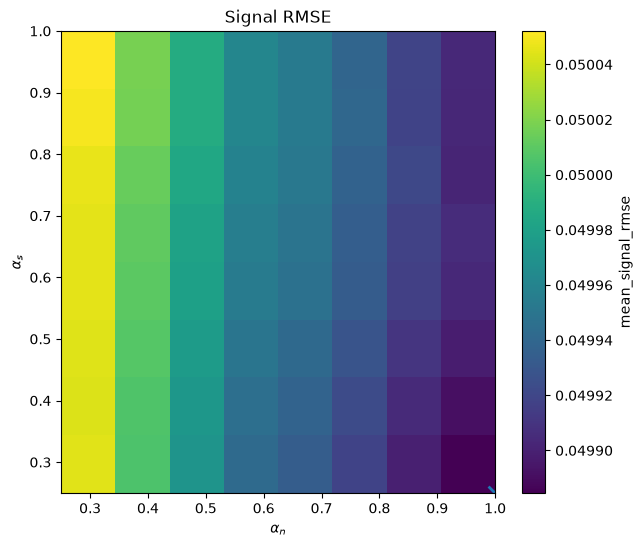

soma_fraction_rmse: minimum at alpha_s=0.375, alpha_n=0.625


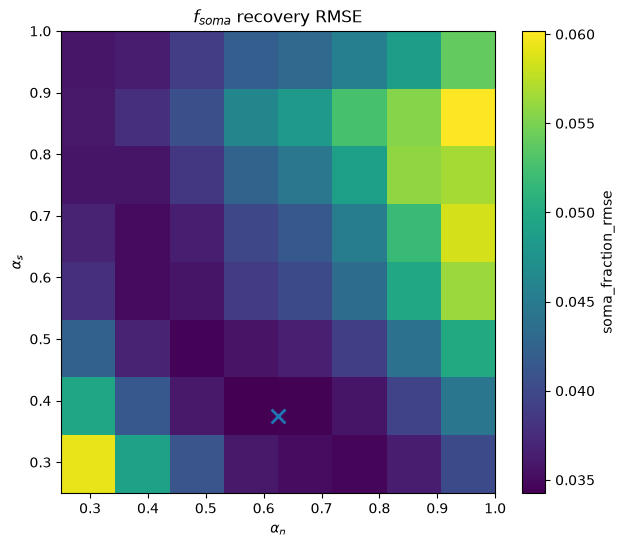

neurite_fraction_rmse: minimum at alpha_s=0.750, alpha_n=0.250


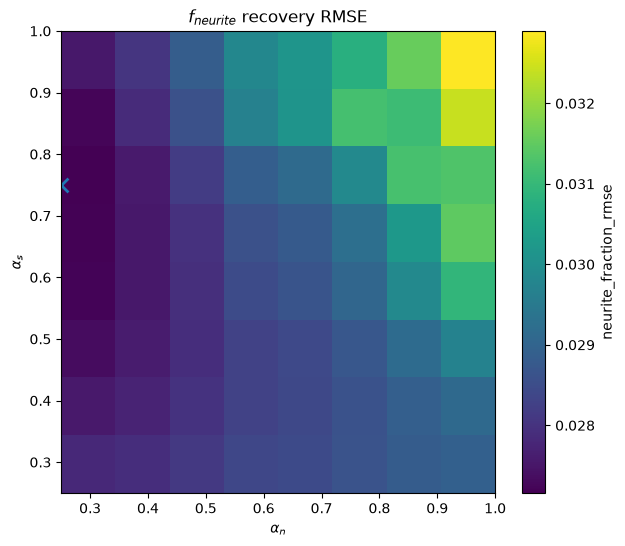

extra_fraction_rmse: minimum at alpha_s=1.000, alpha_n=0.750


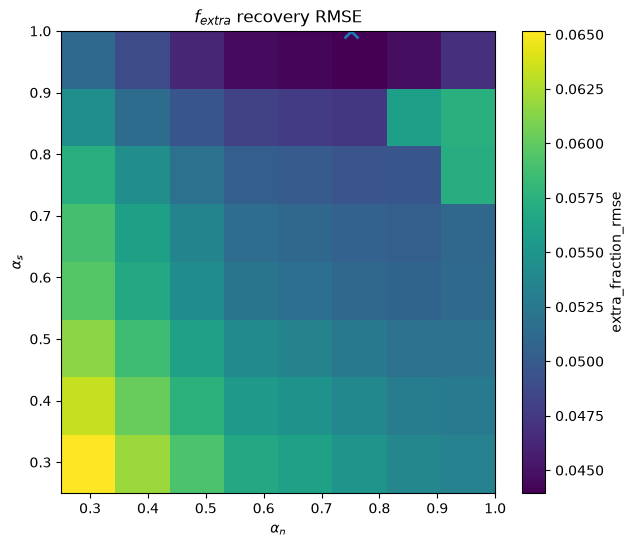

csf_fraction_rmse: minimum at alpha_s=0.250, alpha_n=0.625


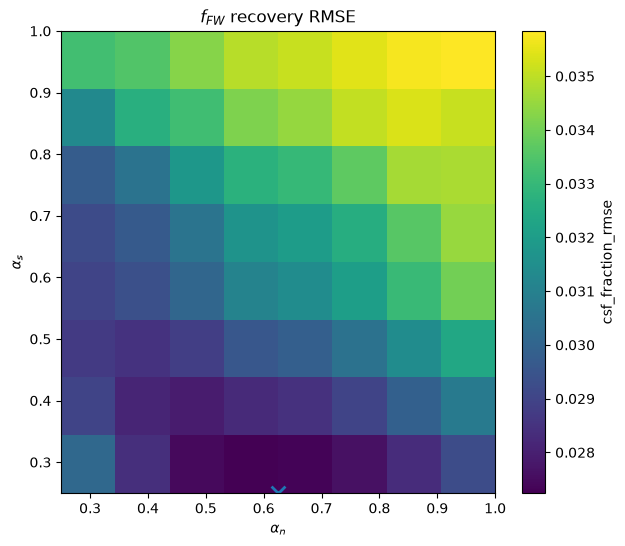

r_soma_rmse: minimum at alpha_s=0.250, alpha_n=0.375


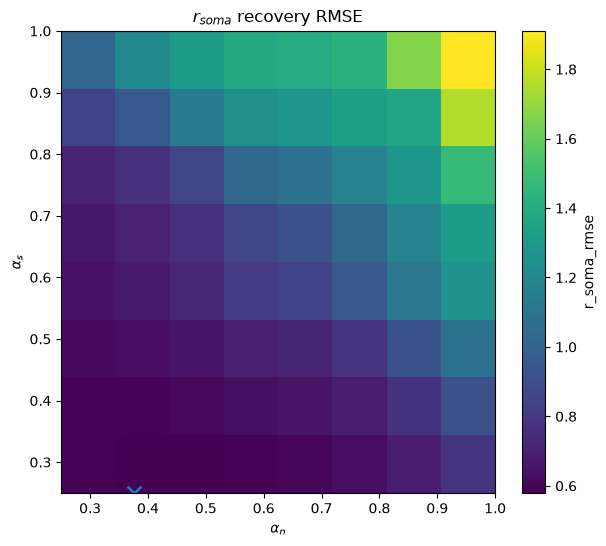

In [31]:
plot_alpha_heatmap(
    alpha_summary,
    "mean_signal_rmse",
    "Signal RMSE",
)

plot_alpha_heatmap(
    alpha_summary,
    "soma_fraction_rmse",
    r"$f_{soma}$ recovery RMSE",
)

plot_alpha_heatmap(
    alpha_summary,
    "neurite_fraction_rmse",
    r"$f_{neurite}$ recovery RMSE",
)

plot_alpha_heatmap(
    alpha_summary,
    "extra_fraction_rmse",
    r"$f_{extra}$ recovery RMSE",
)

plot_alpha_heatmap(
    alpha_summary,
    "csf_fraction_rmse",
    r"$f_{FW}$ recovery RMSE",
)

plot_alpha_heatmap(
    alpha_summary,
    "r_soma_rmse",
    r"$r_{soma}$ recovery RMSE",
)

In [32]:
# =============================================================================
# SPECIFIC HYPOTHESES
# =============================================================================
# This lets you directly compare your linear model, the literature-inspired powers, and the best grid candidates.

def nearest_alpha_pair(
    summary,
    target_s,
    target_n,
):

    distance = (
        (
            summary["alpha_s"]
            - target_s
        ) ** 2
        +
        (
            summary["alpha_n"]
            - target_n
        ) ** 2
    )

    return summary.loc[
        distance.idxmin()
    ]


hypotheses = {

    "Linear (1, 1)":
        (1.0, 1.0),

    "Literature-inspired (1/2, 2/3)":
        (0.5, 2.0 / 3.0),
}


hypothesis_rows = []

for name, (
    alpha_s,
    alpha_n
) in hypotheses.items():

    row = nearest_alpha_pair(
        alpha_summary,
        alpha_s,
        alpha_n,
    ).copy()

    row["hypothesis"] = name

    hypothesis_rows.append(
        row
    )


hypothesis_df = pd.DataFrame(
    hypothesis_rows
)


columns_to_show = [

    "hypothesis",

    "alpha_s",
    "alpha_n",

    "mean_signal_rmse",

    "soma_fraction_rmse",
    "neurite_fraction_rmse",
    "extra_fraction_rmse",
    "csf_fraction_rmse",

    "r_soma_rmse",
]


display(
    hypothesis_df[
        columns_to_show
    ]
)

,hypothesis,alpha_s,alpha_n,mean_signal_rmse,soma_fraction_rmse,neurite_fraction_rmse,extra_fraction_rmse,csf_fraction_rmse,r_soma_rmse
63,"Linear (1, 1)",1.0,1.000,0.049904,0.053975,0.032899,0.046797,0.035841,1.910197
20,"Literature-inspired (1/2, 2/3)",0.5,0.666,0.049942,0.036558,0.028430,0.053453,0.029863,0.719275
